# Jackson analysis for SD: 100%, Bag method and 27 CC clusters.

Let us start with imports and defining path related constants:

In [1]:
import collections
import os

from lifelines import CoxPHFitter
from matplotlib import cm as mcm
from matplotlib import colors as mcolors
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
from matplotlib import font_manager
from scipy.cluster.hierarchy import linkage
import lifelines
import matplotlib as mpl
import numpy
import pandas
import seaborn as sns

from immuw.immucan import immucan_utils as iiu
import tumorhood_analysis_utils as tau

font_manager.fontManager.addfont('/raid/immucan/immuw/Arial.ttf')  # if you need to add the font file
plt.rcParams['font.family'] = 'Arial'


# Technical part:

# Number of Cellular Neighborhood clusters used for analysis.
JACKSON_NB_OF_CLUSTERS = 27
# We will use bag approach (instead of a single cell)
TYPE = 'bag'
# As we will use area-adjusted counts, we set vectorizer to be identity.
VECTORIZER = None


# Cell based part:

# Path to dataframe with cell marker expressions and cell types.
DF_PATH = '/raid/immucan/immuw/image_analysis/analysis/UW/packages/IMMUW/scripts/jackson-basel-25.csv'
CC_CLUSTER_NAME = 'cellohood_neighborhood_cluster'
DUMMY_COL_NAME = 'dummy'
CELLTYPE_COLNAME = 'cell_type'

# Path to annotation of cell types to meta classes.
CELLTYPE_TO_CLASS_DF_PATH = '/raid/immucan/immuw/data/jackson/Cluster_labels/Metacluster_annotations.csv'
CLASS_COLNAME = 'class'


# Cellohood Predictions part
PREDICITONS_PATH = '/raid/immucan/immuw/image_analysis/analysis/UW/packages/IMMUW/scripts/jackson_corrected_basel_25/clustering/kmeans_predictions/kmeans_predictions_27_3.npy'
PREDICTION_CLUSTER_COLUMN = 'cc'

ROI_COLUMN = 'core'
ROI_CLUSTER_NAME = 'Slide Group'


# ROI Clustering artifacts saving path
JACKSON_CLUSTER_SELECTION_DIR = './jackson-corrected-basel-final-area-adjusted-none-vectorizer/'
JACKSON_CLUSTER_SELECTION_PATH = os.path.join(JACKSON_CLUSTER_SELECTION_DIR, f'jackson-full-scaled-{JACKSON_NB_OF_CLUSTERS}-cn.pickle')

# Clinical Data Part
CLINICAL_DATA = '/raid/immucan/immuw/data/jackson/Data_publication/BaselTMA/Basel_PatientMetadata.csv'
CLINICAL_DATA_COLS_FOR_ANALYSIS = [
    'ERStatus',
    'HER2Status',
    'grade', 
    'Patientstatus', 
    'PRStatus',
    'response',
    'clinical_type',
]


# Marker PART:
E = iiu.JACKSON
# These are cleaned up marker name in the same oreder as JACKSON MARKERS.
JACKSON_MARKERS_CLEAN = [
    'EGFR',
    'ECad',
    'DNA1',
    'DNA2',
    'Estrogen',
    'GATA3',
    'H3-1',
    'Ki67',
    'SMA',
    'Vimentin',
    'cl.PARP',
    'HER2',
    'p53',
    'panCK',
    'CK 19',
    'PR',
    'c-Myc',
    'Fibronectin',
    'Keratin-14',
    'Slug',
    'CD20',
    'vWF',
    'H3-2',
    'CK-5',
    'CD44',
    'CD45',
    'CD68',
    'CD3epsi',
    'CAIX',
    'CK 8/18',
    'CK 7',
    'Twist',
    'p-Histone',
    'S6',
    'mTOR',
]


# Plotting utils
PLOTTING_DPI = 300

sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
plt.rcParams['legend.title_fontsize'] = 6
plt.rcParams['legend.fontsize'] = 6

# Caption utils:
CC_PLOT_NAME = 'Cellular Neighborhoods'
CLASS_PLOT_NAME = 'Cell class'
CELLTYPE_PLOT_NAME = 'Cell type'
MARKER_PLOT_NAME = 'Marker'
ALL_PLOT_NAME = 'All'
ROI_PLOT_NAME = 'SG'

# Survival:
COX_PREFIX_CC_CLUSTERS = 'CC Cox'

In [2]:
JACKSON_MARKERS = [
    '1021522Tm169Di EGFR',
    '1031747Er167Di ECadhe',
    '10331253Ir191Di Iridium', 
    '10331254Ir193Di Iridium',
    '112475Gd156Di Estroge', 
    '117792Dy163Di GATA3',
    '1261726In113Di Histone', 
    '1441101Er168Di Ki67',
    '174864Nd148Di SMA',
    '1921755Sm149Di Vimenti',
    '198883Yb176Di cleaved',
    '201487Eu151Di cerbB', 
    '207736Tb159Di p53', 
    '234832Lu175Di panCyto',
    '3111576Nd143Di Cytoker', 
    '312878Gd158Di Progest',
    '322787Nd150Di cMyc',
    '3281668Nd142Di Fibrone', 
    '346876Sm147Di Keratin',
    '3521227Gd155Di Slug', 
    '361077Dy164Di CD20', 
    '378871Yb172Di vWF',
    '473968La139Di Histone', 
    '651779Pr141Di Cytoker', 
    '6967Gd160Di CD44',
    '71790Dy162Di CD45', 
    '77877Nd146Di CD68', 
    '8001752Sm152Di CD3epsi',
    '92964Er166Di Carboni', 
    '971099Nd144Di Cytoker',
    '98922Yb174Di Cytoker',
    'Nd145Di Twist', 
    'phospho Histone',
    'phospho S6', 
    'phospho mTOR',
]

## Cell type level data loading and preprocessing

In [3]:
cell_df = pandas.read_csv(DF_PATH)

In [4]:
# Marker ARCSINH x / 5 transformation
cell_df[JACKSON_MARKERS] =  cell_df[JACKSON_MARKERS].applymap(lambda x: numpy.arcsinh(x / 5.))

In [5]:
# Extra column for computations
cell_df[DUMMY_COL_NAME] = 1

## Prediction level loading

In [6]:
predictions = numpy.load(PREDICITONS_PATH)

In [7]:
if TYPE == 'bag':
    cell_df[PREDICTION_CLUSTER_COLUMN] = cell_df[CC_CLUSTER_NAME].apply(lambda x: predictions[x])
elif TYPE == 'sd':
    cell_df[PREDICTION_CLUSTER_COLUMN] = predictions
else:
    raise ValueError('Unknown TYPE.')

## Cell type class related preparation:

In [8]:
celltype_to_class_df = pandas.read_csv(CELLTYPE_TO_CLASS_DF_PATH, sep=';')

Assigning classes to cell types:

In [9]:
celltype_to_class = {
    row['Cell type']: row['Class']
    for _, row in celltype_to_class_df.iterrows()
}
celltype_to_class['Unknown'] = 'Unknown'

Assigning class colors:

In [10]:
class_to_color = {
    'Immune': mcolors.CSS4_COLORS['green'], 
    'Stroma': mcolors.CSS4_COLORS['lightcoral'],
    'Tumor': mcolors.CSS4_COLORS['maroon'],
    'Vessel': mcolors.CSS4_COLORS['red'],
    'Unknown': mcolors.CSS4_COLORS['black'],
}

Assigning cells to their celltypes:

In [11]:
cell_df[CLASS_COLNAME] = cell_df[CELLTYPE_COLNAME].apply(lambda x: celltype_to_class[x]) 

### Class related initial analysis

In [12]:
class_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CLASS_COLNAME],
    aggfunc="sum",
).fillna(0)

In [13]:
class_percentages = (class_counts.T / class_counts.sum(axis=1)).T
class_percentages.index.name = CC_PLOT_NAME
class_percentages.columns.name = CLASS_PLOT_NAME

Plotting class percentages:

(900.0, 600.0)

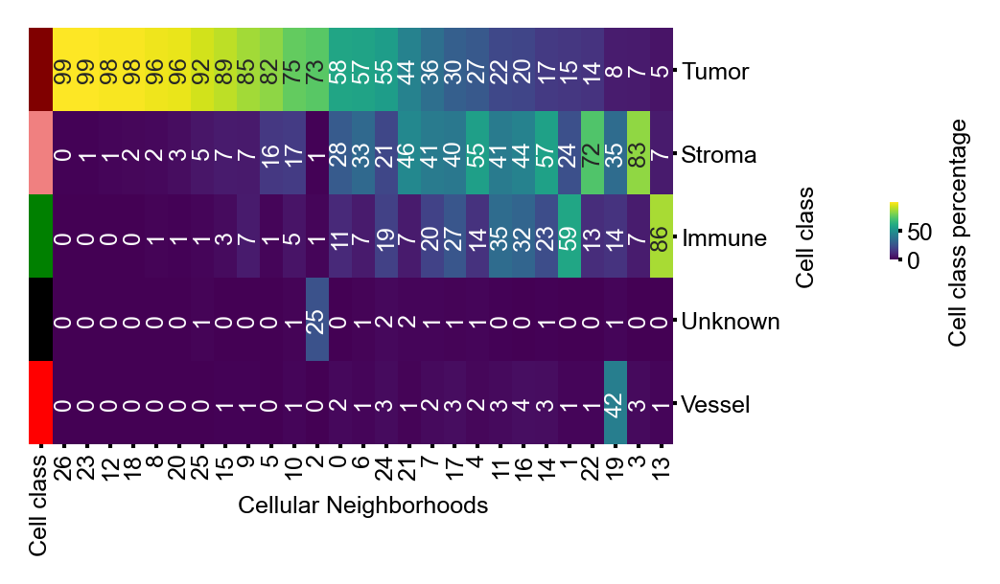

In [14]:
class_row_colors_df = pandas.DataFrame(
    [color for color in class_to_color.values()],
    index=class_to_color.keys(),
    columns=[CLASS_PLOT_NAME]
)

class_clustermap = sns.clustermap(
    class_percentages.T[(-class_percentages['Tumor']).argsort()] * 100, 
    col_cluster=False,
    annot=True,
    fmt='.0f',
    cmap='viridis',
    row_colors=class_row_colors_df,
    cbar_pos=(1.2, 0.4, 0.01, 0.1),
    annot_kws={"size": 6, "rotation": 90},
    cbar_kws={'label': f'{CLASS_PLOT_NAME} percentage'}
)

class_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
class_clustermap.ax_row_dendrogram.set_visible(False)
class_clustermap.ax_col_dendrogram.set_visible(False)

class_clustermap.ax_heatmap.set_yticklabels(class_clustermap.ax_heatmap.get_yticklabels(), size=6)
class_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
class_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
class_clustermap.ax_heatmap.set_xticklabels(class_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
class_clustermap.ax_row_colors.set_xticklabels(class_clustermap.ax_row_colors.get_xticklabels(), size=6)
class_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, pad=1)

class_clustermap.fig.set_dpi(PLOTTING_DPI)
class_clustermap.fig.set_size_inches((3, 2))
class_clustermap.fig.get_window_extent().width, class_clustermap.fig.get_window_extent().height

## Cell type related preparation:

In [15]:
celltype_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc="sum",
).fillna(0)

In [16]:
celltype_percentages = (celltype_counts.T / celltype_counts.sum(axis=1)).T
celltype_percentages.index.name = CC_PLOT_NAME
celltype_percentages.columns.name = CELLTYPE_PLOT_NAME

In [17]:
celltypes = list(celltype_percentages.columns)

In [18]:
celltypes_color_df = pandas.DataFrame(
    [class_to_color[celltype_to_class[ct]] for ct in celltypes],
    index=celltypes,
    columns=[CLASS_PLOT_NAME]
)

(1800.0, 600.0)

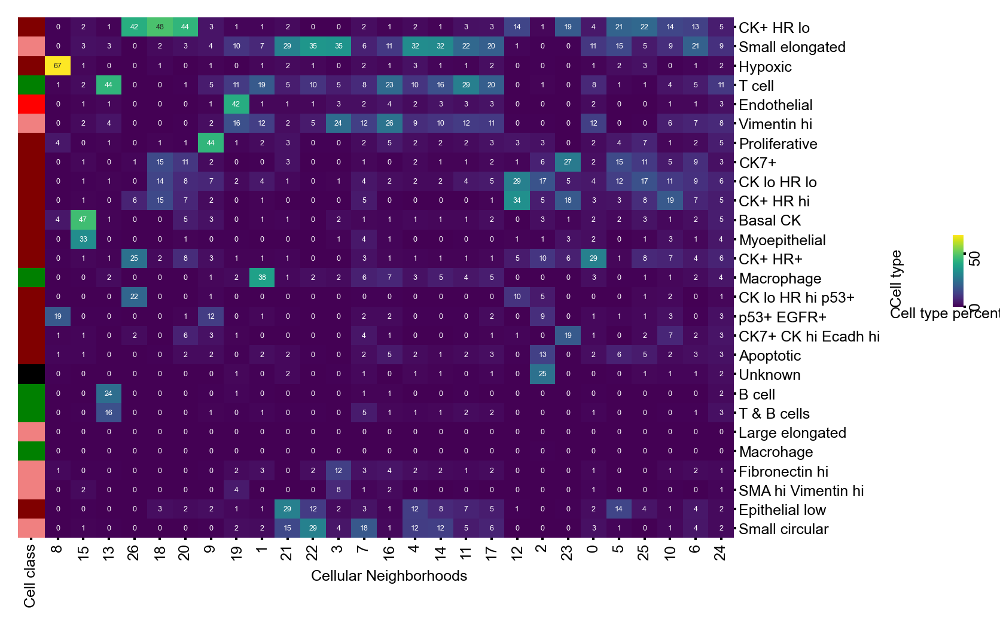

In [19]:
celltype_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.05, 0.4, 0.01, 0.1),
    annot_kws={"size": 3},
    cbar_kws={'label': ''}
)

celltype_clustermap.ax_cbar.set_xlabel(f'{CELLTYPE_PLOT_NAME} percentage', labelpad=0, size=6)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1, rotation=90)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
celltype_clustermap.ax_row_colors.set_xticklabels(celltype_clustermap.ax_row_colors.get_xticklabels(), size=6)
celltype_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, pad=1)

celltype_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_clustermap.fig.set_size_inches((6, 4))
celltype_clustermap.fig.get_window_extent().width, class_clustermap.fig.get_window_extent().height

## Marker analysis

### Cell type level:
For each marker compute the average marker expression for a given cell type:

In [20]:
marker_to_celltype_dfs = {}


for marker in JACKSON_MARKERS:
    marker_to_celltype_dfs[marker] = pandas.pivot_table(
    cell_df, 
    values=marker, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc='mean',
).fillna(0)

Now - let us transpose this dictionary to cell type to marker df:

In [21]:
marker_ct_ipc = numpy.stack([
    marker_df.values
    for marker_df in marker_to_celltype_dfs.values()
])

celltype_to_marker_dfs = {
    ct: pandas.DataFrame(
        marker_ct_ipc[:, :, ct_ind],
        index=JACKSON_MARKERS,
    )
    for ct_ind, ct in enumerate(celltypes)
}

Now - let's rename the markers to their clean names:

In [22]:
celltype_to_marker_dfs_clean = {}


for celltype, cdf in celltype_to_marker_dfs.items():
    cdf_clean = cdf.copy()
    cdf_clean[MARKER_PLOT_NAME] = JACKSON_MARKERS_CLEAN
    cdf_clean.set_index(MARKER_PLOT_NAME, inplace=True),
    celltype_to_marker_dfs_clean[celltype] = cdf_clean

## All marker analysis:

Now let's compute the overall marker distribution across all cells:

In [23]:
all_markers_distribution = cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[JACKSON_MARKERS]
all_markers_distribution -= all_markers_distribution.mean()
all_markers_distribution /= all_markers_distribution.std()
all_markers_distribution.columns = JACKSON_MARKERS_CLEAN

celltype_to_marker_dfs_clean[ALL_PLOT_NAME] = all_markers_distribution.T

/tmp/ipykernel_4104654/4082070946.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  all_markers_distribution = cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[JACKSON_MARKERS]


Now let's display the all marker distributions:

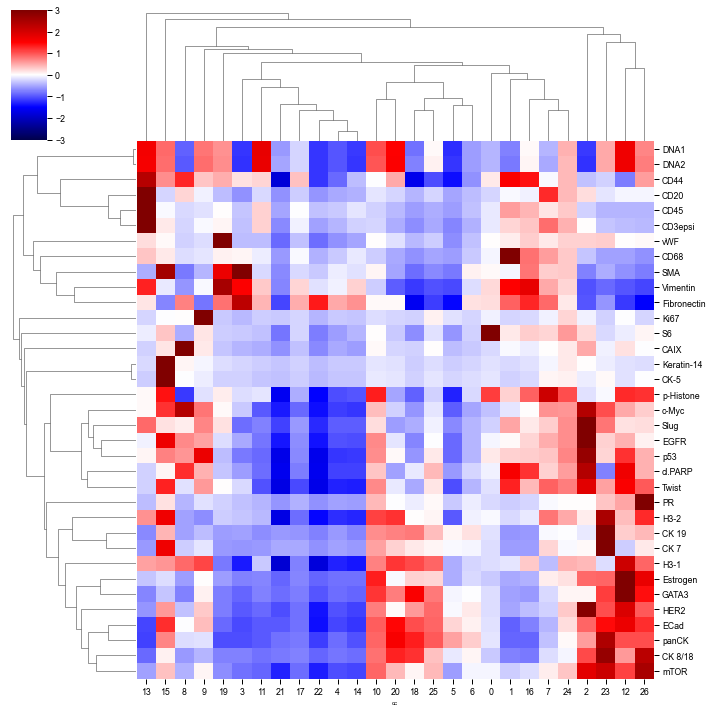

In [24]:
sns.clustermap(all_markers_distribution.T, center=0, cmap='seismic', vmin=-3, vmax=3)

Now - let's visualize the Cellohood Neighobrhoods with average markers.

Let's start with providing some handy tools:
- marker colormap:

In [25]:
marker_color_norm = mpl.colors.Normalize(vmin=-2, vmax=2)
marker_cmap = plt.get_cmap('coolwarm')

marker_sm = mcm.ScalarMappable(norm=marker_color_norm, cmap=marker_cmap)

and a code to transform values to vectors:

In [26]:
def transform_vec_to_colors(
    vec,
    colors,
    standarize=True,
    display=None,
    permute=None,
    ignore_color=(160 / 255, 160 / 255, 160 / 255),
):
    if standarize:
        vec = vec.copy()
        vec = vec - numpy.mean(vec)
        vec = vec / numpy.std(vec)
    result = [
        colors.to_rgba(x)
        for x in vec
    ]
    if display is not None:
        new_result = []
        for ind_, result_col in enumerate(result):
            current_color = list(result_col)
            if ind_ in display:
                pass 
            else:
                current_color = ignore_color
            new_result.append(current_color)
            
        result = new_result
    if permute:
        result = [
            result[i]
            for i in permute
        ]
    return result

Now let's transform average markers across all cells to colors:

In [27]:
all_colors_dict = {
    f'{marker}': transform_vec_to_colors( 
        vec=celltype_to_marker_dfs_clean[ALL_PLOT_NAME].loc[marker],
        colors=marker_sm,
    )
    for marker in JACKSON_MARKERS_CLEAN
}

all_colors_df = pandas.DataFrame(all_colors_dict)

and visualize CC clusters with average marker distributions:

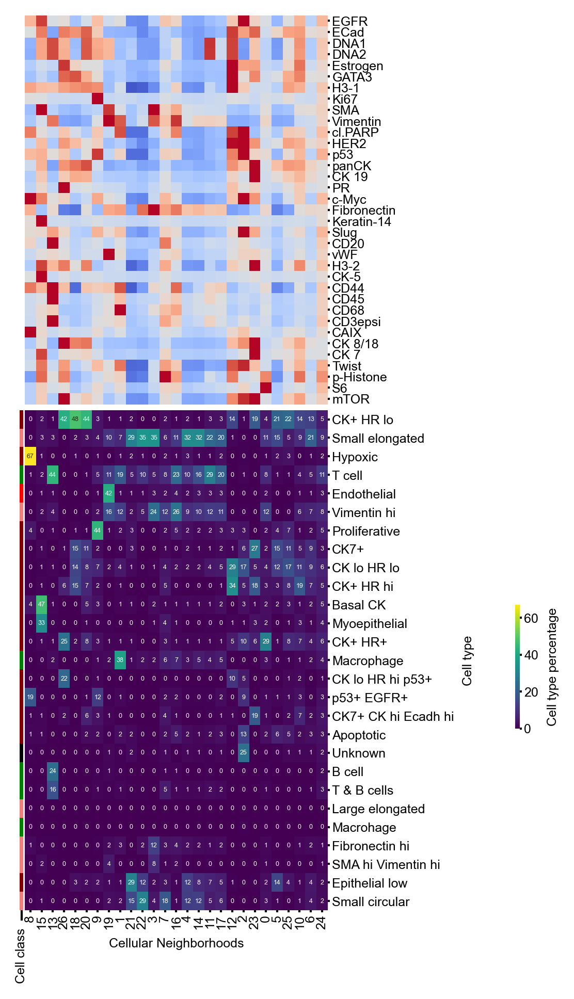

In [28]:
celltype_with_all_markers_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.25, 0.225, 0.01, 0.1),
    col_colors=all_colors_df,
    annot_kws={'size': 3},
    yticklabels=1,
    colors_ratio=(0.01, 0.01),
    cbar_kws={'label': f'{CELLTYPE_PLOT_NAME} percentage'}
)

celltype_with_all_markers_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_with_all_markers_clustermap.ax_row_dendrogram.set_visible(False)
celltype_with_all_markers_clustermap.ax_col_dendrogram.set_visible(False)

celltype_with_all_markers_clustermap.ax_heatmap.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_with_all_markers_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_with_all_markers_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_with_all_markers_clustermap.ax_heatmap.set_xticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

celltype_with_all_markers_clustermap.ax_row_colors.set_xticklabels(
    celltype_with_all_markers_clustermap.ax_row_colors.get_xticklabels(), size=6
)
celltype_with_all_markers_clustermap.ax_col_colors.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_col_colors.get_yticklabels(), size=6
)
celltype_with_all_markers_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

celltype_with_all_markers_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_with_all_markers_clustermap.fig.set_size_inches((3, 8))


## Class marker analysis:

In [29]:
from scipy.stats import trim_mean

class_marker_dfs = {}

for marker in JACKSON_MARKERS:
    class_marker_dfs[marker] = pandas.pivot_table(
    cell_df, 
    values=marker, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CLASS_COLNAME],
    aggfunc=lambda x: numpy.clip(x, 0, numpy.quantile(x, 0.95)).mean(),
).fillna(0)
    
    
class_marker_ct_ipc = numpy.stack([
    marker_df.values
    for marker_df in class_marker_dfs.values()
])


for class_ind, class_ in enumerate(list(class_marker_dfs.values())[0].columns):
    celltype_to_marker_dfs_clean[class_] = pandas.DataFrame(
        class_marker_ct_ipc[:, :, class_ind],
        index=JACKSON_MARKERS,
    )



for celltype, cdf in celltype_to_marker_dfs_clean.items():
    print(celltype)
    cdf_clean = cdf.copy()
    cdf_clean['Marker'] = JACKSON_MARKERS_CLEAN
    cdf_clean.set_index('Marker', inplace=True),
    celltype_to_marker_dfs_clean[celltype] = cdf_clean

Apoptotic
B cell
Basal CK
CK lo HR hi p53+
CK lo HR lo
CK+ HR hi
CK+ HR lo
CK+ HR+
CK7+
CK7+ CK hi Ecadh hi
Endothelial
Epithelial low
Fibronectin hi
Hypoxic
Large elongated
Macrohage
Macrophage
Myoepithelial
Proliferative
SMA hi Vimentin hi
Small circular
Small elongated
T & B cells
T cell
Unknown
Vimentin hi
p53+ EGFR+
All
Immune
Stroma
Tumor
Vessel


Tumor


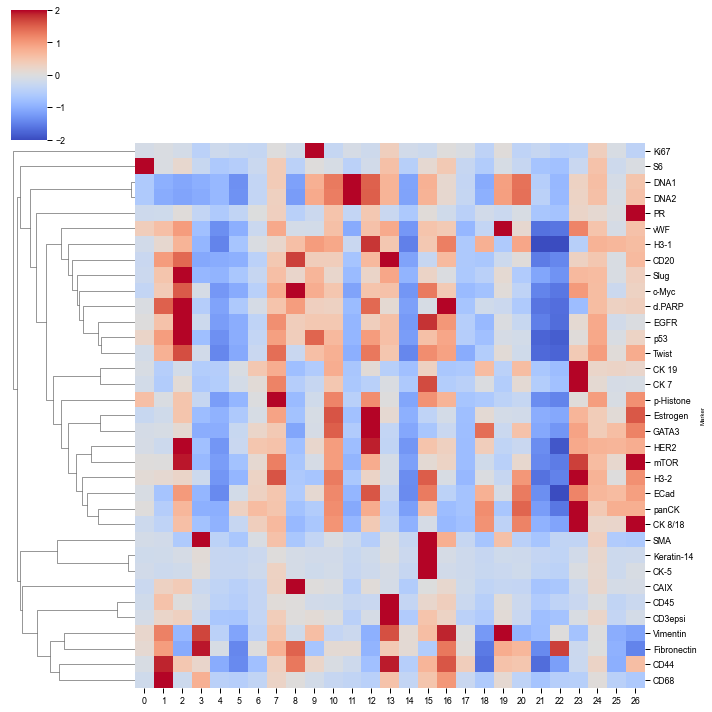

In [30]:
for ct in ['Tumor']:
    print(ct)
    sns.clustermap(
        celltype_to_marker_dfs_clean[ct].loc[JACKSON_MARKERS_CLEAN], 
        yticklabels=JACKSON_MARKERS_CLEAN,
        z_score=0,
        center=0,
        cmap='coolwarm',
        col_cluster=False,
        vmin=-2,
        vmax=2,
    )
    plt.show()

## Density analysis

In [31]:
cc_densities = cell_df.groupby(['cc', 'cellohood_neighborhood_cluster']).size().groupby('cc').mean()

## ROI Based Analysis:

Let us start from collection of the roi counts:

In [32]:
roi_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[ROI_COLUMN],
    columns=[PREDICTION_CLUSTER_COLUMN],
    aggfunc="sum",
).fillna(0)

and let's read clinical data:

In [33]:
clinical_data_basel = pandas.read_csv(CLINICAL_DATA)

let's filter out the control samples:

In [34]:
clinical_data_basel = clinical_data_basel[clinical_data_basel['diseasestatus'] == 'tumor']

and set the sample column:

In [35]:
clinical_data_basel['sample'] = ['_'.join(el.split('_')[:-1]) for el in clinical_data_basel.core]

Now - let's merge the data with the ROI counts:

In [36]:
clinical_data_basel = clinical_data_basel.reset_index()

Histology related analysis:

In [37]:
ductal, lobular, mucinous, medullary = [], [], [], [] 

first, second = [], []
for el in clinical_data_basel['histology']:
    first_el, _ = el.split('-')
    ductal.append('ductal' in first_el)
    lobular.append('lobular' in first_el)
    mucinous.append('mucinous' in first_el)
    medullary.append('medullary' in first_el)

    
clinical_data_basel['ductal'] = ductal 
clinical_data_basel['lobular'] = lobular
clinical_data_basel['mucinous'] = mucinous
clinical_data_basel['medullary'] = medullary

In [38]:
sample_count_basel = pandas.merge(clinical_data_basel, roi_counts, left_on='core', right_on='core')
sample_count_basel['patient'] = sample_count_basel.index

## Core correlations analysis:

Let us start with obtaining general Cellohood cluster counts:

In [39]:
cluster_counts = cell_df.groupby(PREDICTION_CLUSTER_COLUMN).size()

Now - let's visualize Clusters correlations and counts:

/tmp/ipykernel_4104654/3329225080.py:47: UserWarning: FixedFormatter should only be used together with FixedLocator
  barplot_ax.set_xticklabels(


array([2.4, 2.4])

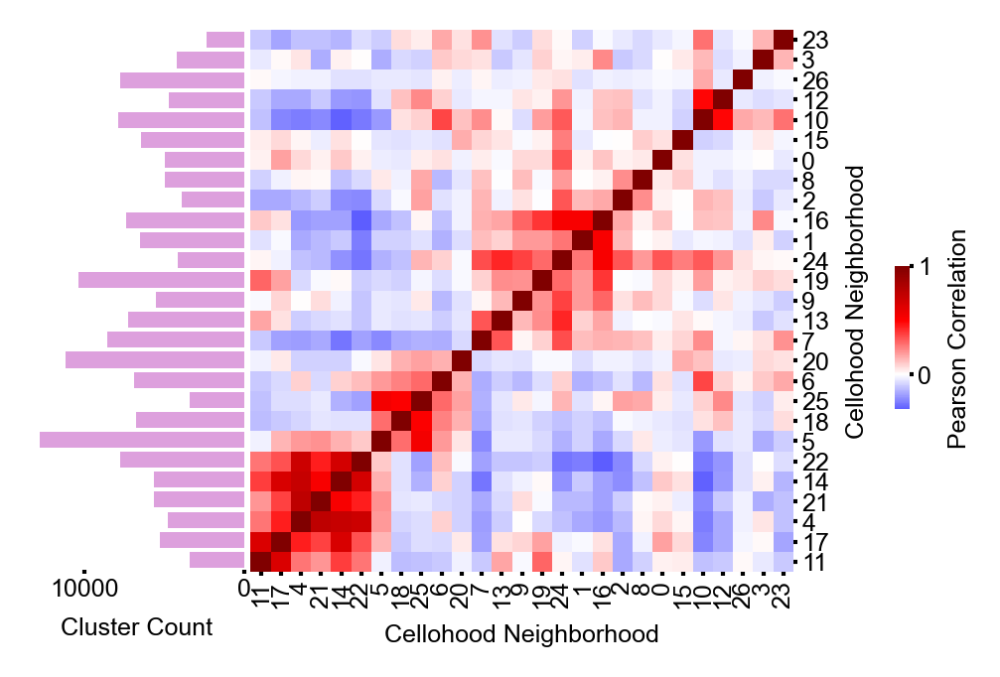

In [40]:
corr_df = sample_count_basel[list(range(JACKSON_NB_OF_CLUSTERS))].corr()
corr_df.index.name = 'Cellohood Neighborhood'
corr_df.columns.name = 'Cellohood Neighborhood'

mpl.rcParams.update(mpl.rcParamsDefault)

sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
plt.rcParams['legend.title_fontsize'] = 6
plt.rcParams['legend.fontsize'] = 6
mpl.rcParams['font.family'] = 'Arial'


corr_cmap = sns.clustermap(
    corr_df,
    center=0,
    cmap='seismic',
    xticklabels=True,
    yticklabels=True,
    #annot=True,
    #fmt='.2f',
    #annot_kws={'size': 3},
    cbar_pos=[1.1, 0.27, 0.02, 0.2],
    cbar_kws={'label': 'Pearson Correlation'}
)

corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)
#corr_cmap.ax_cbar.set_visible(False)

barplot_ax = corr_cmap.fig.add_axes([-.11, 0.045, .3, .755], sharey=corr_cmap.ax_heatmap)
barplot_ax.barh(
    corr_cmap.data2d.columns + 0.5,
    cluster_counts[corr_cmap.data2d.columns],
    align='center',
    height=0.8,
    color='plum',
)
barplot_ax.invert_yaxis()
barplot_ax.invert_xaxis()
barplot_ax.spines['left'].set_visible(False)
barplot_ax.spines['top'].set_visible(False)
barplot_ax.spines['right'].set_visible(False)
barplot_ax.spines['bottom'].set_visible(False)
barplot_ax.yaxis.set_visible(False)
barplot_ax.set_xlabel('Cluster Count', size=6)
barplot_ax.xaxis.set_tick_params(size=1, left=True, pad=1)
barplot_ax.set_xticklabels(
    barplot_ax.get_xticklabels(), size=6, rotation=0
)

corr_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)

corr_cmap.ax_heatmap.set_yticklabels(
    corr_cmap.ax_heatmap.get_yticklabels(), size=6)
corr_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
corr_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
corr_cmap.ax_heatmap.set_xticklabels(
    corr_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

corr_cmap.fig.set_dpi(PLOTTING_DPI)
corr_cmap.fig.set_size_inches((2.4, 2.4))
plt.gcf().get_size_inches()

## Log-1p area adjustment of counts:

Here we will provide area-adjusted counts in the same way as in the original paper:

In [41]:
AA_ADJUSTED_COLS = [f'{i}AA' for i in range(JACKSON_NB_OF_CLUSTERS)]


sample_count_basel[AA_ADJUSTED_COLS] = numpy.log1p(
    sample_count_basel[range(JACKSON_NB_OF_CLUSTERS)].values / sample_count_basel['area'].values.reshape((-1, 1)
                                                                                                        ) * 10000000
)

for col in AA_ADJUSTED_COLS:
    current_quantile = numpy.quantile(sample_count_basel[col], 0.99)
    sample_count_basel[col] = numpy.clip(sample_count_basel[col], 0, current_quantile)

## Cluster number selection:

Let us run the algorithm for the cluster number selection:

3


4


5


6


7


8


... (19 outputs left out)

28


29


30


3260.317239046097


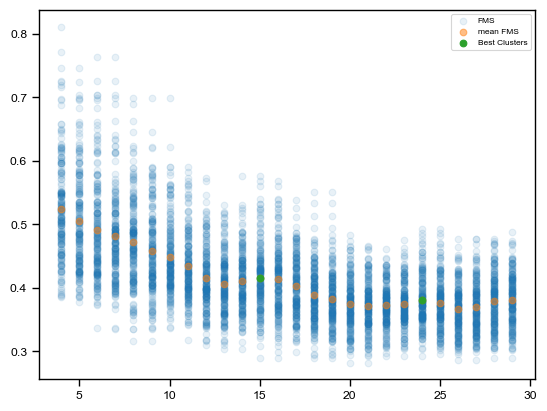

In [42]:
import pickle 
import time

import immuw.clustering.clustering_utils as cimu


start_time = time.time()


if os.path.exists(JACKSON_CLUSTER_SELECTION_PATH):
    with open(JACKSON_CLUSTER_SELECTION_PATH, 'rb') as handle:
        jackson_cs_result = pickle.load(handle)
        jackson_cs_best_clusterers = cimu.get_best_clusters_from_cimu_result(jackson_cs_result)
else:
    jackson_cs_result, jackson_cs_best_clusterers = tau.perform_cluster_selection(
        sample_count_basel, 
        AA_ADJUSTED_COLS,
        vectorization_function=VECTORIZER,
        nb_of_tries_per_cluster_nb=10,
    )
    os.makedirs(JACKSON_CLUSTER_SELECTION_DIR, exist_ok=True)
    with open(JACKSON_CLUSTER_SELECTION_PATH, 'wb') as handle:
        pickle.dump(jackson_cs_result, handle)

print(time.time() - start_time)

and let us have a look at found cluster numbers:

In [43]:
jackson_cs_best_clusterers

{15: MiniBatchKMeans(n_clusters=15, n_init='auto', random_state=163),
 24: MiniBatchKMeans(n_clusters=24, n_init='auto', random_state=259)}

## Patient Clustermap:

Let us start with preparation of appropriate vectors and clusters:

In [44]:
JACKSON_ROI_CLUSTERS = 15
clusterer = jackson_cs_best_clusterers[JACKSON_ROI_CLUSTERS]

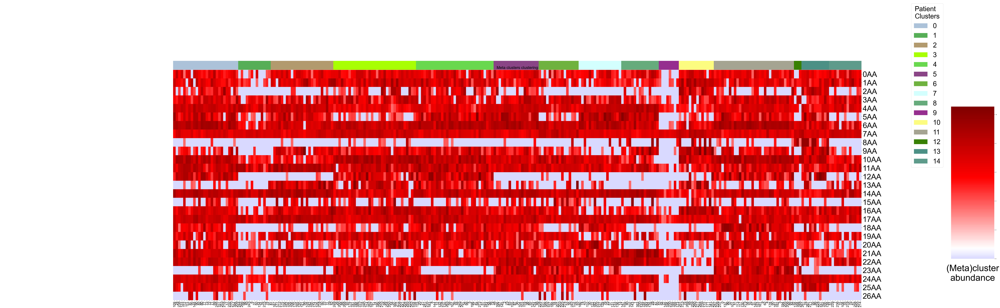

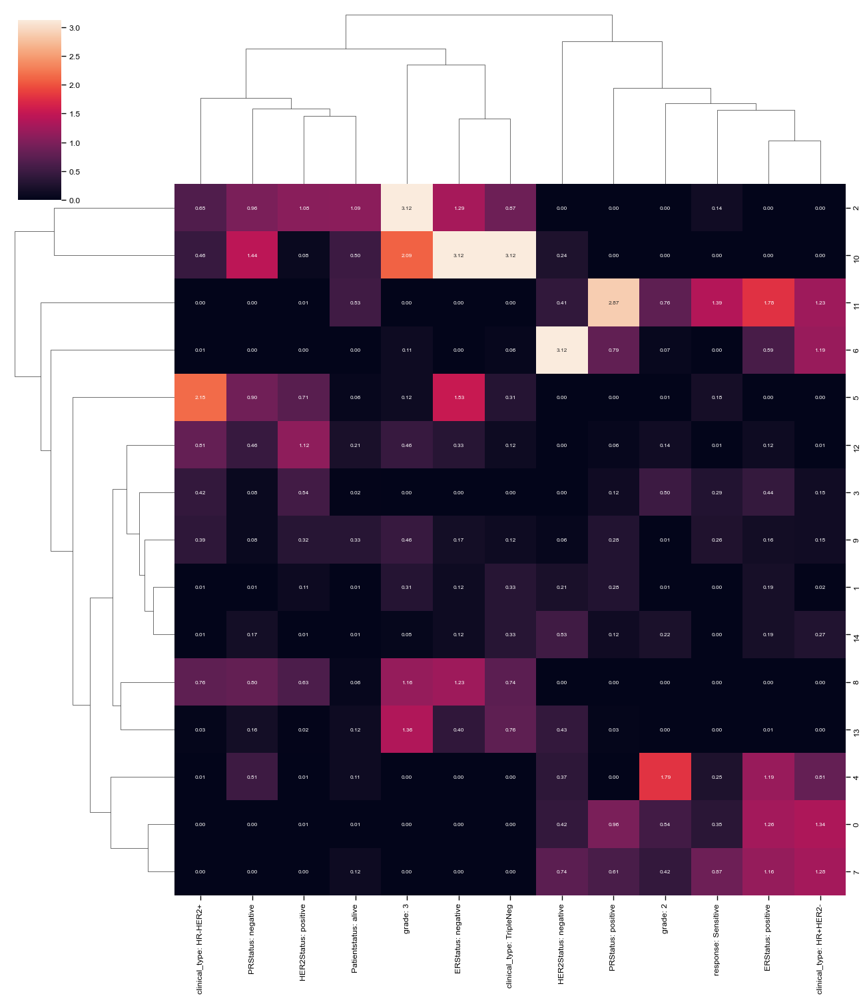

In [45]:
_, vectors, clusters, clusterer, qvals = tau.visualize_patient_clusters_with_survival_analysis_and_hg_no_lung(
    patients_df=sample_count_basel,
    clusterer_type=clusterer,
    clusters_to_select=AA_ADJUSTED_COLS,
    hypergeometric_columns=CLINICAL_DATA_COLS_FOR_ANALYSIS,
    vectorization_function=VECTORIZER, 
    #center=0.0,
    filter_below_percentage=0.01,
    cmap='seismic',
    number_of_clusters=JACKSON_ROI_CLUSTERS,
    hypergeometric_fdr_alpha=0.1,
    hypergeometric_filter_nas=True,
)

In [46]:
sample_count_basel[ROI_CLUSTER_NAME] = clusters
sample_count_basel[DUMMY_COL_NAME] = 1

Now - let's prepare color coding for the analyzed clinical variables:

In [47]:
CLINICAL_DATA_COLS_FOR_ANALYSIS

['ERStatus',
 'HER2Status',
 'grade',
 'Patientstatus',
 'PRStatus',
 'response',
 'clinical_type']

In [48]:
ER_PLOT_NAME = 'ER'
PR_PLOT_NAME = 'PR'
HER2_PLOT_NAME = 'HER2'
GRADE_PLOT_NAME = 'Grade'
PS_PLOT_NAME = 'Patient Status'
RESPONSE_PLOT_NAME = 'Response'
PTNM_PLOT_NAME = 'PTNM: Radical'
CLINICAL_TYPE_PLOT_NAME = 'Clinical Type'
SN_PLOT_NAME = 'SN'
MI_PLOT_NAME = 'microinvasion'

ER_POSITIVE_COLOR = 'black'
PR_POSITIVE_COLOR = 'black'
HER2_POSITIVE_COLOR = 'black'
NAN_COLOR = 'lightgrey'

In [49]:
patient_to_clinical_colors_dict = {}

# ER Status
er_color = collections.defaultdict(lambda: mcolors.CSS4_COLORS[NAN_COLOR])
er_color['negative'] = mcolors.CSS4_COLORS['white']
er_color['positive'] = mcolors.CSS4_COLORS[ER_POSITIVE_COLOR]
er_colors = sample_count_basel['ERStatus'].apply(lambda x: er_color[x])
patient_to_clinical_colors_dict[ER_PLOT_NAME] = er_colors

# PR Status
pr_color = collections.defaultdict(lambda: mcolors.CSS4_COLORS[NAN_COLOR])
pr_color['negative'] = mcolors.CSS4_COLORS['white']
pr_color['positive'] = mcolors.CSS4_COLORS[PR_POSITIVE_COLOR]
pr_colors = sample_count_basel['PRStatus'].apply(lambda x: pr_color[x])
patient_to_clinical_colors_dict[PR_PLOT_NAME] = pr_colors

# HER2 Status
her2_color = collections.defaultdict(lambda: mcolors.CSS4_COLORS[NAN_COLOR])
her2_color['negative'] = mcolors.CSS4_COLORS['white']
her2_color['positive'] = mcolors.CSS4_COLORS[PR_POSITIVE_COLOR]
her2_colors = sample_count_basel['HER2Status'].apply(lambda x: her2_color[x])
patient_to_clinical_colors_dict[HER2_PLOT_NAME] = her2_colors

# Grade Color
sample_count_basel['grade'] = sample_count_basel['grade'].apply(lambda x: int(x) if not numpy.isnan(x) else -1)
grade_color = {
    1: mcolors.CSS4_COLORS['green'],
    2: mcolors.CSS4_COLORS['blue'],
    3: mcolors.CSS4_COLORS['red'],
    -1: mcolors.CSS4_COLORS[NAN_COLOR],
}
grade_colors = sample_count_basel['grade'].apply(lambda x: grade_color[x])
patient_to_clinical_colors_dict[GRADE_PLOT_NAME] = grade_colors

# Patient Status
ps_color = collections.defaultdict(lambda: mcolors.CSS4_COLORS[NAN_COLOR])
ps_color['alive'] = 'g'
ps_color['alive w metastases'] = 'y'
ps_color['death'] = 'k'
ps_color['death by primary disease'] = 'r'
ps_colors = sample_count_basel['Patientstatus'].apply(lambda x: ps_color[x])
patient_to_clinical_colors_dict[PS_PLOT_NAME] = ps_colors

# Response
response_color = collections.defaultdict(lambda: mcolors.CSS4_COLORS[NAN_COLOR])
response_color['Refractory'] = '#F4845F'
response_color['Resistant'] = '#D62828'
response_color['Sensitive'] = '#00A878'
response_colors = sample_count_basel['response'].apply(lambda x: response_color[x])
patient_to_clinical_colors_dict[RESPONSE_PLOT_NAME] = response_colors

# PTNM
ptnm_color = collections.defaultdict(lambda: mcolors.CSS4_COLORS[NAN_COLOR])
ptnm_color[1.0] = mcolors.CSS4_COLORS['black']
ptnm_color[0.0] = mcolors.CSS4_COLORS['white']
ptnm_colors = sample_count_basel['PTNM_Radicality'].apply(lambda x: ptnm_color[x])
#patient_to_clinical_colors_dict[PTNM_PLOT_NAME] = ptnm_colors


clinical_type_color = collections.defaultdict(lambda: mcolors.CSS4_COLORS[NAN_COLOR])
clinical_type_color['HR+HER2-'] = mcolors.CSS4_COLORS['orange']
clinical_type_color['HR+HER2+'] = mcolors.CSS4_COLORS['pink']
clinical_type_color['HR-HER2+'] = mcolors.CSS4_COLORS['darkslateblue']
clinical_type_color['TripleNeg'] = mcolors.CSS4_COLORS['teal']
clinical_type_colors = sample_count_basel['clinical_type'].apply(lambda x: clinical_type_color[x])
patient_to_clinical_colors_dict[CLINICAL_TYPE_PLOT_NAME] = clinical_type_colors

# SN
sn_color = collections.defaultdict(lambda: mcolors.CSS4_COLORS[NAN_COLOR])
sn_color['sn'] = mcolors.CSS4_COLORS['black']
sn_color['sl'] = mcolors.CSS4_COLORS['white']
sn_colors = sample_count_basel['SN'].apply(lambda x: sn_color[x])
#patient_to_clinical_colors_dict[SN_PLOT_NAME] = sn_colors

# I Plus Neg
ipn_color = collections.defaultdict(lambda: mcolors.CSS4_COLORS[NAN_COLOR])
ipn_color['i+'] = mcolors.CSS4_COLORS['black']
ipn_color['i-'] = mcolors.CSS4_COLORS['white']
ipn_colors = sample_count_basel['I_plus_neg'].apply(lambda x: ipn_color[x])
#patient_to_clinical_colors_dict['IPN'] = ipn_colors

# Microinvasion
mi_color = collections.defaultdict(lambda: mcolors.CSS4_COLORS[NAN_COLOR])
mi_color[1.0] = mcolors.CSS4_COLORS['black']
mi_color[0.0] = mcolors.CSS4_COLORS['white']
mi_colors = sample_count_basel['microinvasion'].apply(lambda x: mi_color[x])
#patient_to_clinical_colors_dict[MI_PLOT_NAME] = mi_colors


patient_to_clinical_colors_df = pandas.DataFrame(patient_to_clinical_colors_dict)

In [50]:
cluster_counter = collections.Counter(clusters)
cluster_positions = numpy.zeros((JACKSON_ROI_CLUSTERS + 1,))

for i in range(JACKSON_ROI_CLUSTERS):
    cluster_positions[i + 1] = cluster_counter[i]

cluster_positions = cluster_positions.cumsum()
cluster_centers = (0.5 * (cluster_positions[1:] + cluster_positions[:-1])).astype('int')

ticks = []
current_cluster = 0
for i in range(sample_count_basel.shape[0]):
    if i in cluster_positions:
        ticks.append('-')
        continue
    if i in cluster_centers:
        ticks.append(str(current_cluster))
        current_cluster += 1
        continue
    ticks.append('')

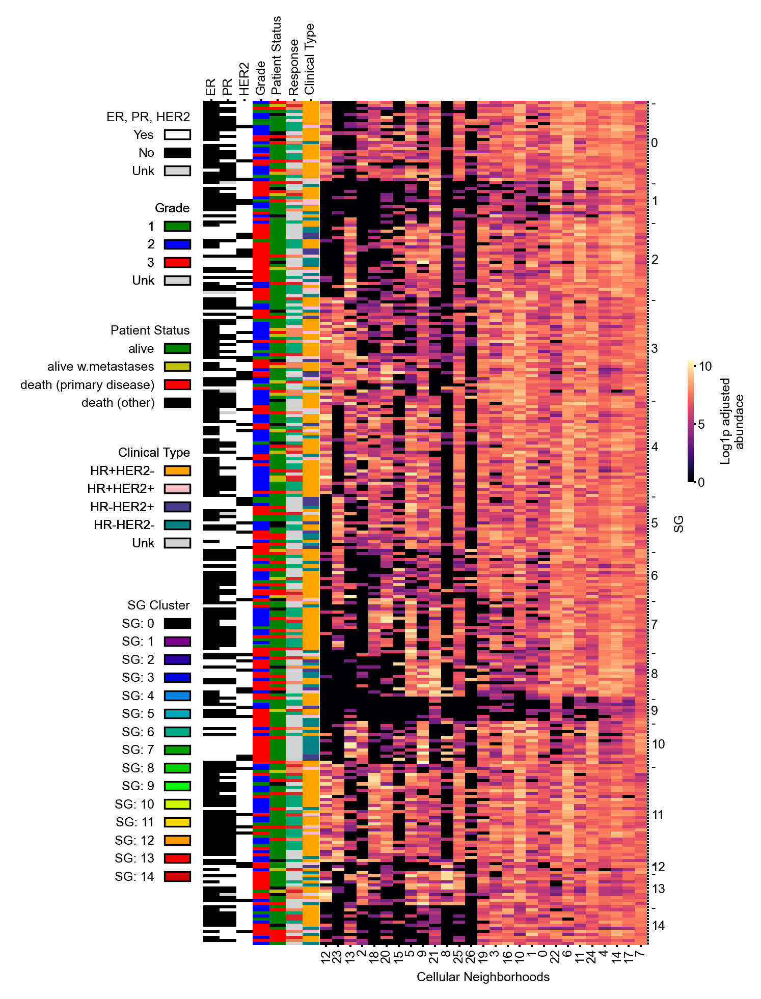

In [51]:
from matplotlib import cm as mcm
import matplotlib as mpl

plt.rcParams['font.family'] = 'Arial'

cluster_norm = mpl.colors.Normalize(vmin=0, vmax=JACKSON_ROI_CLUSTERS)
cluster_cmap = plt.get_cmap('nipy_spectral')

cluster_sm = mcm.ScalarMappable(norm=cluster_norm, cmap=cluster_cmap)

vectors_df = pandas.DataFrame(
    vectors.T,
    index=patient_to_clinical_colors_df.index,
)
vectors_df.index.name = ROI_PLOT_NAME
vectors_df.columns.name = CC_PLOT_NAME


#patient_to_clinical_colors_df['Cluster'] = [cluster_sm.to_rgba(x) for x in clusters]

patient_clustermap = sns.clustermap( 
    vectors_df.iloc[clusters.argsort()].T.iloc[(-vectors_df.std(axis=0)).argsort()].T,
    col_cluster=False,
    row_cluster=False,
    xticklabels=1,
    cbar_pos=[.99, 0.5, 0.01, .1],
    cbar_kws={'label': 'Log1p adjusted\nabundace'},
    yticklabels=ticks,
    row_colors=patient_to_clinical_colors_df,
    figsize=(6, 8),
    cmap='magma',
)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(rotation=0)

patient_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
patient_clustermap.ax_row_dendrogram.set_visible(False)
patient_clustermap.ax_col_dendrogram.set_visible(False)

patient_clustermap.ax_heatmap.set_yticklabels(
    patient_clustermap.ax_heatmap.get_yticklabels(), size=6)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
patient_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
patient_clustermap.ax_heatmap.set_xticklabels(
    patient_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)


patient_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, top=True, pad=2, rotation=90)
patient_clustermap.ax_row_colors.set_xticklabels(
    patient_clustermap.ax_row_colors.get_xticklabels(), size=6,
)
patient_clustermap.ax_row_colors.xaxis.tick_top()
#patient_clustermap.ax_col_colors.set_yticklabels(
#    patient_clustermap.ax_col_colors.get_yticklabels(), size=6
#)
#patient_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

LEGEND_SPACING = 0.195

pos_neg_handles = [Patch(facecolor=er_color[name], edgecolor='black') for name in er_color]
pos_neg_legend = plt.legend(
    pos_neg_handles, 
    ['Yes', 'No', 'Unk'], 
    title='ER, PR, HER2',
    bbox_to_anchor=(LEGEND_SPACING, .8125), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(pos_neg_legend)


grade_handles = [Patch(facecolor=grade_color[name], edgecolor='black') for name in grade_color]
grade_legend = plt.legend(
    grade_handles, 
    [1, 2, 3, 'Unk'], 
    title='Grade',
    bbox_to_anchor=(LEGEND_SPACING, .7375), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(grade_legend)

ps_handles = [
    Patch(facecolor=ps_color[name], edgecolor='black')
    for name in ['alive', 'alive w metastases', 'death by primary disease', 'death']
]
ps_legend = plt.legend(
    ps_handles, 
    ['alive', 'alive w.metastases', 'death (primary disease)', 'death (other)'], 
    title='Patient Status',
    bbox_to_anchor=(LEGEND_SPACING, .6375), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(ps_legend)

response_handles = [Patch(facecolor=response_color[name], edgecolor='black') for name in response_color]
response_legend = plt.legend(
    response_handles, 
    ['Refractory', 'Resistant', 'Sensitive', 'Unk'], 
    title='Response',
    bbox_to_anchor=(LEGEND_SPACING, .5375), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(grade_legend)

clinical_handles = [Patch(facecolor=clinical_type_color[name], edgecolor='black') for name in clinical_type_color]
clinical_legend = plt.legend(
    clinical_handles, 
    ['HR+HER2-', 'HR+HER2+', 'HR-HER2+', 'HR-HER2-', 'Unk'], 
    title='Clinical Type',
    bbox_to_anchor=(LEGEND_SPACING, .5375), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(clinical_legend)

cluster_handles = [
    Patch(facecolor=cluster_sm.to_rgba(x), edgecolor='black')
    for x in range(JACKSON_ROI_CLUSTERS)
]
cluster_legend = plt.legend(
    cluster_handles, 
    [f'{ROI_PLOT_NAME}: {ind_}' for ind_ in range(JACKSON_ROI_CLUSTERS)], 
    title=f'{ROI_PLOT_NAME} Cluster',
    bbox_to_anchor=(LEGEND_SPACING, .4125), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(clinical_legend)

patient_clustermap.fig.set_dpi(PLOTTING_DPI)
patient_clustermap.fig.set_size_inches((4, 8))

## Clinical Data analysis

In [52]:
roi_cluster_counts = pandas.pivot_table(
    sample_count_basel, 
    values='dummy', 
    index=['sample'],
    columns=[ROI_CLUSTER_NAME],
    aggfunc="sum",
).fillna(0)

In [53]:
ROI_CLUSTER_NAMES = [f'{ROI_PLOT_NAME}: {cl_}' for cl_ in roi_cluster_counts.columns]

ROI_CLUSTER_INDICES = list(roi_cluster_counts.columns)
roi_cluster_counts.columns = ROI_CLUSTER_NAMES

In [54]:
roi_cluster_counts.index.name = 'sample'

In [55]:
roi_cluster_with_clinical = pandas.merge(roi_cluster_counts, clinical_data_basel, on='sample')

Now, let's filter out patients with percentage lower than `0.04`.

In [56]:
PERCENTAGE_TO_FILTER_OUT = 0.04

JACKSON_GOOD_ROI_CLUSTERS = [
    cl 
    for cl, row in roi_cluster_with_clinical[ROI_CLUSTER_NAMES].mean(axis=0).to_frame().iterrows()
    if row[0] > PERCENTAGE_TO_FILTER_OUT
]


JACKSON_GOOD_ROI_CLUSTERS_INDS = [
    row_nb 
    for row_nb, (cl, row) in enumerate(roi_cluster_with_clinical[ROI_CLUSTER_NAMES].mean(axis=0).to_frame().iterrows())
    if row[0] > PERCENTAGE_TO_FILTER_OUT
]

Now, let us compute a table with enrichements scores for clusters and clinical features, for subgroups of patients that have a particular ROI cluster:

In [57]:
import matplotlib.pyplot as plt


jackson_roi_pval_table = pandas.concat(
    [
        pandas.concat(
            [
                tau.compute_hypergeometrics_for_df(
                    df=roi_cluster_with_clinical,
                    clusters=roi_cluster_with_clinical[cluster] > 0,
                    column=column,
                    values=None,
                    filter_nas=True,
            ).iloc[[1]]
            for column in CLINICAL_DATA_COLS_FOR_ANALYSIS],
            axis=1,
        )
        for cluster in JACKSON_GOOD_ROI_CLUSTERS
    ],
    axis=0,
)

jackson_roi_pval_table.index = [
    f'{cluster}'
    for cluster in JACKSON_GOOD_ROI_CLUSTERS
]

Now, let's compute the FDR corrected p-values:

In [58]:
jackson_roi_qval_table = tau.apply_fdr_to_df(jackson_roi_pval_table)

Now, let's clean out the names of the clinical features:

In [59]:
raw_clinical_to_clean_clinical_names = {
    'grade': 'Grade',
    'Patientstatus': 'Patient',
    'HER2Status': 'HER2',
    'PRStatus': 'PR',
    'ERStatus': 'ER',
    'clinical_type': 'Clinical Type',
    'TripleNeg': 'HR-HER2-',
    'response': 'Response',
    'Sensitive': 'sensitive',
    'primary disease': 'cancer',
}

def clean_clinical_name(name, replacement_dict=None):
    if replacement_dict is None:
        replacement_dict = raw_clinical_to_clean_clinical_names
    for raw_name, clean_name in replacement_dict.items():
        name = name.replace(raw_name, clean_name)
    return name

In [60]:
jackson_roi_qval_table.columns = [clean_clinical_name(col) for col in jackson_roi_qval_table.columns]

Now, let's filter out the cases with `FDR_ALPHA` and lower scores:

In [61]:
FDR_ALPHA = 0.2

jackson_q_vals_sig_series = jackson_roi_qval_table.min() < FDR_ALPHA

jackson_sl_qvals_text = jackson_roi_qval_table.copy()
jackson_sl_qvals_text = jackson_sl_qvals_text.applymap(lambda x: str(round(x, 2)) if x < FDR_ALPHA  else '')

<Figure size 3840x2880 with 0 Axes>

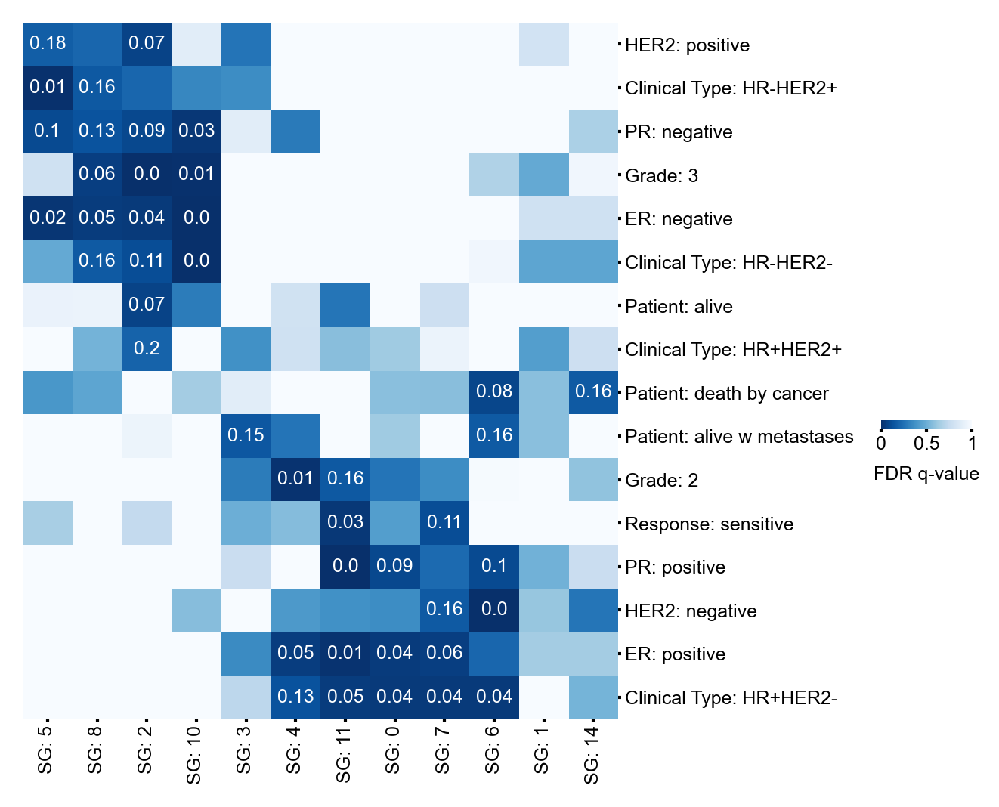

In [62]:
plt.figure(dpi=600)

clinical_cm = sns.clustermap(
    jackson_roi_qval_table.T[jackson_q_vals_sig_series], 
    cmap='Blues_r', 
    annot=jackson_sl_qvals_text.T[jackson_q_vals_sig_series], 
    yticklabels=jackson_sl_qvals_text.T[jackson_q_vals_sig_series].index,
    fmt='', 
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.1, .01],
    cbar_kws={'label': 'FDR q-value', 'orientation': 'horizontal'},
)
clinical_cm.ax_cbar.set_visible('False')
clinical_cm.ax_heatmap.xaxis.set_tick_params(rotation=0)

clinical_cm.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
clinical_cm.ax_cbar.set_xticks(
    [0, 0.5, 1],
    [0, 0.5, 1]
)
clinical_cm.ax_row_dendrogram.set_visible(False)
clinical_cm.ax_col_dendrogram.set_visible(False)

clinical_cm.ax_heatmap.set_yticklabels(
    clinical_cm.ax_heatmap.get_yticklabels(), size=6
)
clinical_cm.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
clinical_cm.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
clinical_cm.ax_heatmap.set_xticklabels(
    clinical_cm.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

clinical_cm.fig.set_dpi(PLOTTING_DPI)
clinical_cm.fig.set_size_inches((4, 4))

Now, let's prepare a colored version of the above table:

In [63]:
clinical_norm = mpl.colors.Normalize(vmin=0, vmax=1)
clinical_cmap = plt.get_cmap('Blues_r')

clinical_sm = mcm.ScalarMappable(norm=clinical_norm, cmap=clinical_cmap)

clinical_colors = clinical_cm.data2d.applymap(lambda x: clinical_sm.to_rgba(x))

## Survival analysis:

Now, let's prepare a table for the Cox analysis. We will use the information about grades and clinical types, similarly to the original paper.

### CC Cluster analysis:

In [64]:
additional_feature_columns = ['HR+HER2+', 'HR-HER2+', 'HR+HER2-', 'HR-HER2-']


sample_count_basel['days_to_death'] = sample_count_basel['OSmonth']
sample_count_basel['death'] = (sample_count_basel['Patientstatus'].apply(
    lambda x: x in ['death by primary disease']))
sample_count_basel['simple_stage'] = sample_count_basel['grade']
sample_count_basel['HR+HER2+'] = sample_count_basel['clinical_type'] == 'HR+HER2+'
sample_count_basel['HR+HER2-'] = sample_count_basel['clinical_type'] == 'HR+HER2-'
sample_count_basel['HR-HER2+'] = sample_count_basel['clinical_type'] == 'HR-HER2+'
sample_count_basel['HR-HER2-'] = sample_count_basel['clinical_type'] == 'TripleNeg'

Now, let's prepare the main Cox table for the Cellohood cluster area-adjusted counts:

In [65]:
jackson_survival_df_clusters = pandas.DataFrame(
    {
        **{
            'died': sample_count_basel[tau.DEATH_COLNAME],
            'survival': sample_count_basel[tau.SURVIVAL_COLNAME], 
            'simple_stage': sample_count_basel[tau.SIMPLE_STAGE_COLNAME],
        },
       **{
            col: sample_count_basel[col]
            for col in additional_feature_columns
        },
        **{
            f'simple_stage_{i}': (sample_count_basel[tau.SIMPLE_STAGE_COLNAME] == i).astype('int')
            for i in range(1, 4 + 1) if sum(sample_count_basel[tau.SIMPLE_STAGE_COLNAME] == i)
        },
        **{
            f'pl_{i[:-2]}': sample_count_basel[i]
            for i in AA_ADJUSTED_COLS
        },
    }
)

Now, let's run the Cox model:

In [66]:
def rename_cox_summary_index(index_, prefix='ROI', simple_stage_name='Grade'):
    new_index = []
    for el in index_:
        if el.startswith('pl'):
            new_index.append(f'{prefix}: {el.split("_")[-1]}')
            continue
        if el.startswith('simple_stage'):
            new_index.append(f'{simple_stage_name}: {el.split("_")[-1]}')
            continue
        new_index.append(el)
    return new_index
        

/tmp/ipykernel_4104654/4240186894.py:25: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = cox_ax.set_xticklabels(cox_ax.get_xticklabels(), size=6)


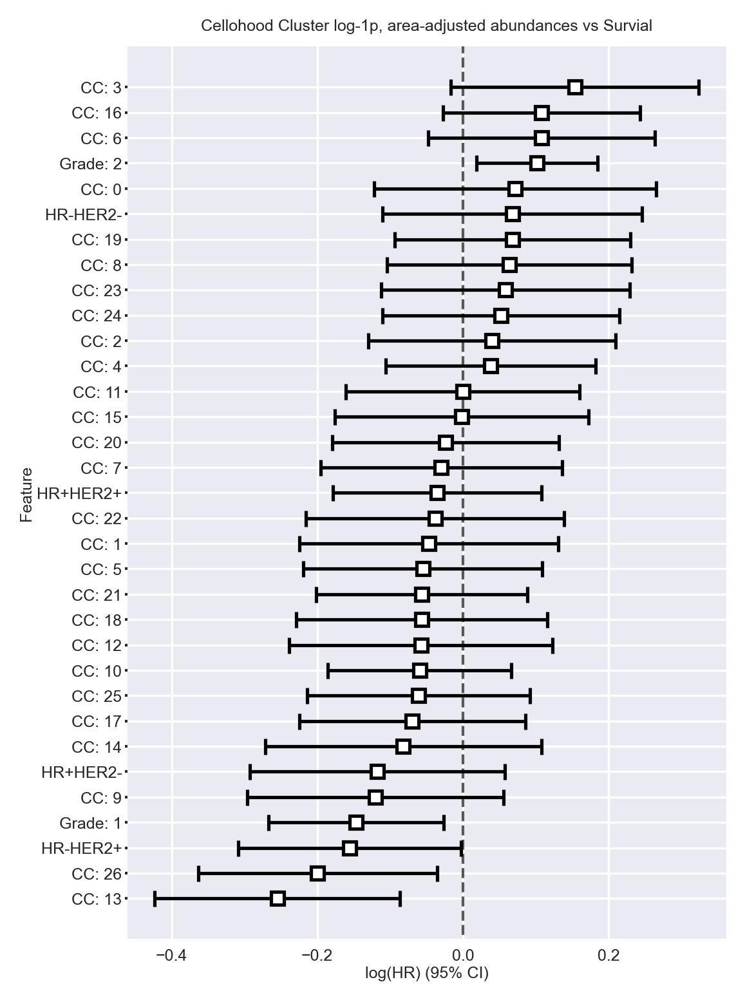

In [67]:
l2_true_value = 1e-1
l1_true_value = 0

coxphf_penalizer = l1_true_value + l2_true_value
coxphf_l1 = l1_true_value / (l1_true_value + l2_true_value)


jackson_cluster_cox = tau.surivial_on_df(
    jackson_survival_df_clusters, 
    l1_ratio=coxphf_l1,
    penalizer=coxphf_penalizer, 
    standardize=True,
    fit_kwargs={'robust': True, 'strata': 'simple_stage_3'}
)
plt.style.use('seaborn-v0_8-darkgrid')
plt.figure(figsize=(4, 6), dpi=300)
jackson_cluster_cox.plot()
plt.title('Cellohood Cluster log-1p, area-adjusted abundances vs Survial', size=6)
cox_ax = plt.gca()
yticklabels = [el.get_text() for el in cox_ax.get_yticklabels()]
_ = cox_ax.set_yticklabels(rename_cox_summary_index(yticklabels, prefix='CC'), size=6)
plt.ylabel('Feature', labelpad=1, fontdict={'size': 6})
plt.xlabel('log(HR) (95% CI)', labelpad=1, fontdict={'size': 6})
cox_ax.yaxis.set_tick_params(pad=1, size=1)
_ = cox_ax.set_xticklabels(cox_ax.get_xticklabels(), size=6)

### ROI Cluster Analysis

In [68]:
additional_feature_columns = ['HR+HER2+', 'HR-HER2+', 'HR+HER2-', 'HR-HER2-']


roi_cluster_with_clinical['days_to_death'] = roi_cluster_with_clinical['OSmonth']
roi_cluster_with_clinical['death'] = (roi_cluster_with_clinical['Patientstatus'].apply(
    lambda x: x in ['death by primary disease']))
roi_cluster_with_clinical['simple_stage'] = roi_cluster_with_clinical['grade']
roi_cluster_with_clinical['HR+HER2+'] = roi_cluster_with_clinical['clinical_type'] == 'HR+HER2+'
roi_cluster_with_clinical['HR+HER2-'] = roi_cluster_with_clinical['clinical_type'] == 'HR+HER2-'
roi_cluster_with_clinical['HR-HER2+'] = roi_cluster_with_clinical['clinical_type'] == 'HR-HER2+'
roi_cluster_with_clinical['HR-HER2-'] = roi_cluster_with_clinical['clinical_type'] == 'TripleNeg'


jackson_survival_df = pandas.DataFrame(
    {
        **{
            'died': roi_cluster_with_clinical[tau.DEATH_COLNAME],
            'survival': roi_cluster_with_clinical[tau.SURVIVAL_COLNAME], 
            'simple_stage': roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME],
        },
        **{
           col: roi_cluster_with_clinical[col]
           for col in additional_feature_columns
        },
        **{
            f'simple_stage_{i}': (roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME] == i).astype('int')
            for i in range(1, 4 + 1) if sum(roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME] == i)
        },
        **{
            f'pl_{JACKSON_ROI_CLUSTERS}_{int(i)}': roi_cluster_with_clinical[f'{ROI_PLOT_NAME}: {i}']
            for i in JACKSON_GOOD_ROI_CLUSTERS_INDS
        },
    }
)

In [69]:
def get_cox_feature_colors(
    feature,
    cluster_prefix=f'{ROI_PLOT_NAME}: '
):
    if feature.startswith(cluster_prefix):
        cluster_ind = int(feature.split(cluster_prefix)[-1])
        return cluster_sm.to_rgba(cluster_ind)
    if feature.startswith('HR'):
        return clinical_type_color[feature]
    if feature.startswith('Grade'):
        grade_int = int(feature[-1])
        return grade_color[grade_int]

/tmp/ipykernel_4104654/4223486248.py:29: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = ax.set_xticklabels(ax.get_xticklabels(), size=6)


Text(0.5, 1.0, 'Cox PH Model\nfor Slide Groups')

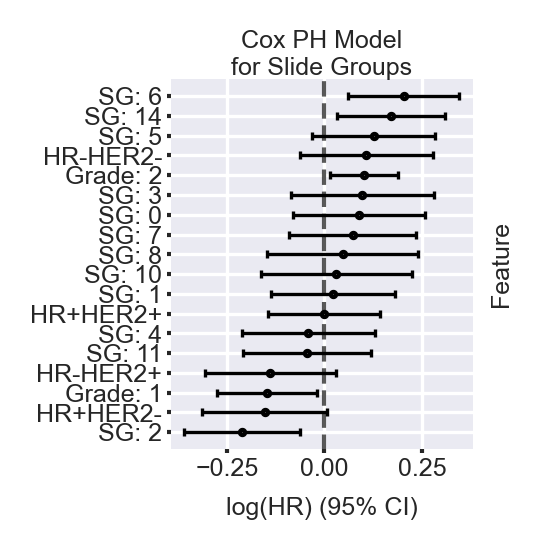

In [70]:
jackson_cox = tau.surivial_on_df(
    jackson_survival_df,
    l1_ratio=coxphf_l1,
    penalizer=coxphf_penalizer,
    fit_kwargs={'robust': True, 'strata': 'simple_stage_3'},
)

COVS_TO_PLOT = [
    el for el in jackson_cox.summary.sort_values('coef', ascending=False).index 
   # if el not in ['pl_15_13', 'pl_15_9']
]
plt.style.use('seaborn-v0_8-darkgrid')
plt.figure(figsize=(1.3, 1.6), dpi=300)
ax = jackson_cox.plot()#columns=COVS_TO_PLOT)
ax.get_children()[0].set_marker('.')
ax.get_children()[0].set_markersize(2.)
ax.get_children()[1].set_linewidth(.8)
ax.get_children()[2].set_markeredgewidth(.8)
ax.get_children()[2].set_markersize(2.)
ax.get_children()[3].set_markeredgewidth(.8)
ax.get_children()[3].set_markersize(2.)
yticklabels = [el.get_text() for el in ax.get_yticklabels()]
new_labels = rename_cox_summary_index(yticklabels, prefix='SG')
labels_colors = [get_cox_feature_colors(feature) for feature in new_labels]
_ = ax.set_yticklabels(new_labels, size=6)
#for ticklabel, tickcolor in zip(ax.get_yticklabels(), labels_colors):
#    ticklabel.set_color(tickcolor)
ax.yaxis.set_tick_params(pad=1, size=1)
_ = ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.xaxis.set_tick_params(pad=1, size=1)
ax.set_ylabel('Feature')
ax.yaxis.set_label_position("right")
#ax.set_ylabel('Feature')
ax.set_title('Cox PH Model\nfor Slide Groups', fontsize=6, pad=1)
#ax.get_children()[0].set_color('blue')

## Kaplan-Meier Curves:

### Cross-ROI clusters analysis

13


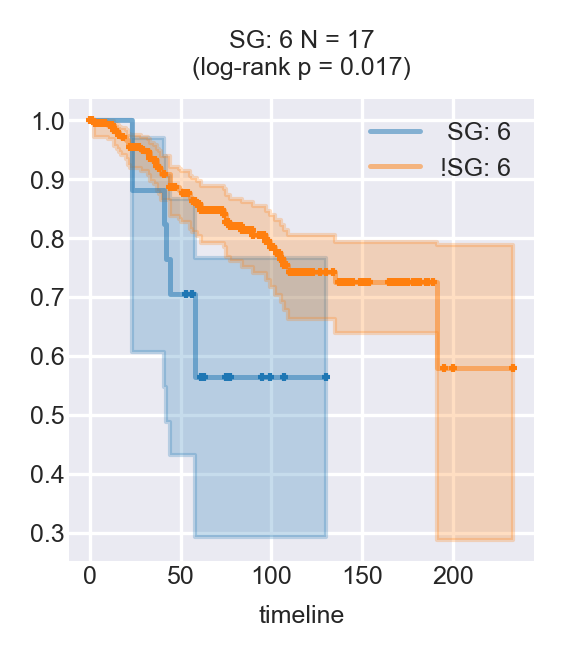

14
13


In [71]:
cluster_log_rank_p_values = numpy.ones((len(JACKSON_GOOD_ROI_CLUSTERS), 1))


for l_ind, l_roi_cc in enumerate(JACKSON_GOOD_ROI_CLUSTERS):
        l_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
        r_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] != 1]
        l_N = l_current_df.shape[0]
        if l_N < 15:
            print(l_N)
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        cluster_log_rank_p_values[l_ind, 0] = current_test.p_value
        if cluster_log_rank_p_values[l_ind, 0] < 0.05:
            plt.figure(figsize=(2, 2), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f' {l_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'!{l_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} N = {l_current_df.shape[0]}\n(log-rank p = {round(cluster_log_rank_p_values[l_ind, 0], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            plt.show()

In [72]:
cluster_log_rank_p_values_df = pandas.DataFrame(
    cluster_log_rank_p_values,
    index=JACKSON_GOOD_ROI_CLUSTERS,
)

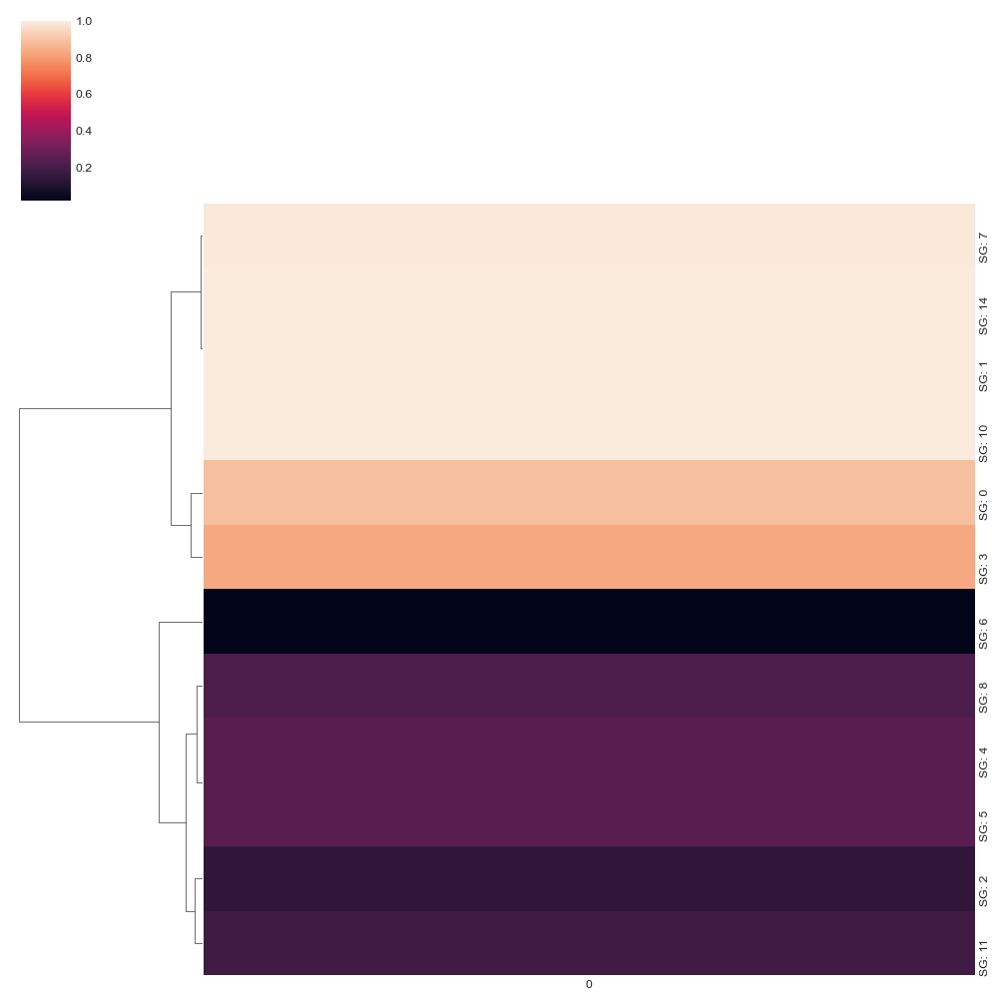

In [73]:
sns.clustermap(cluster_log_rank_p_values_df, col_cluster=False)

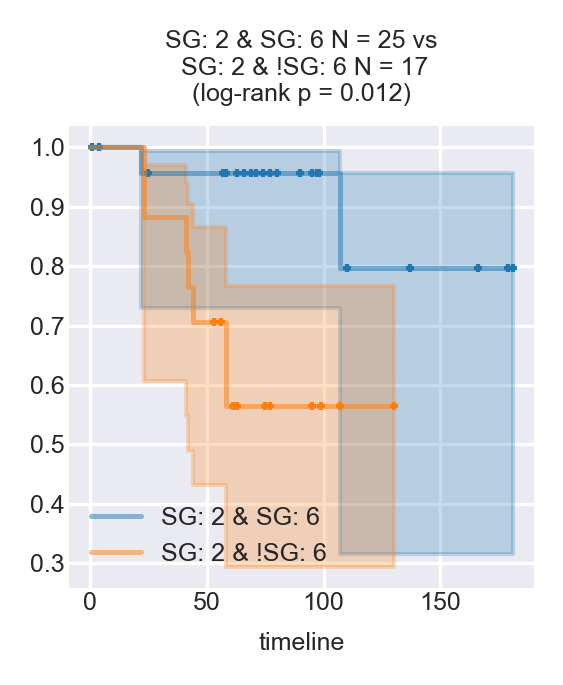

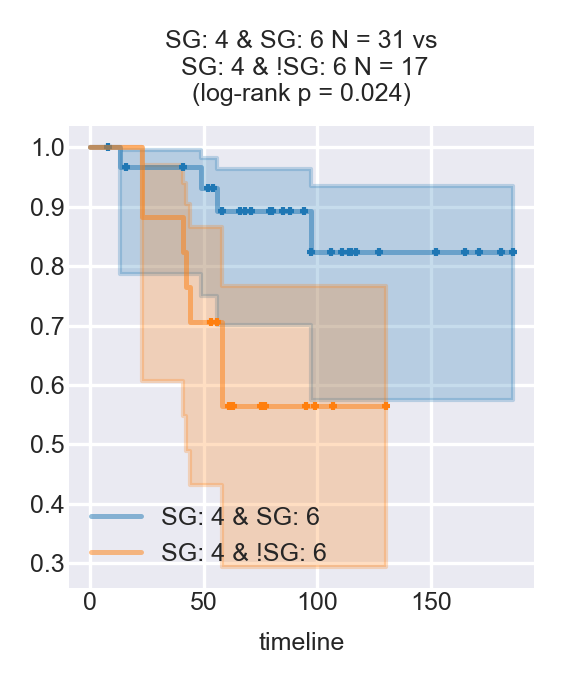

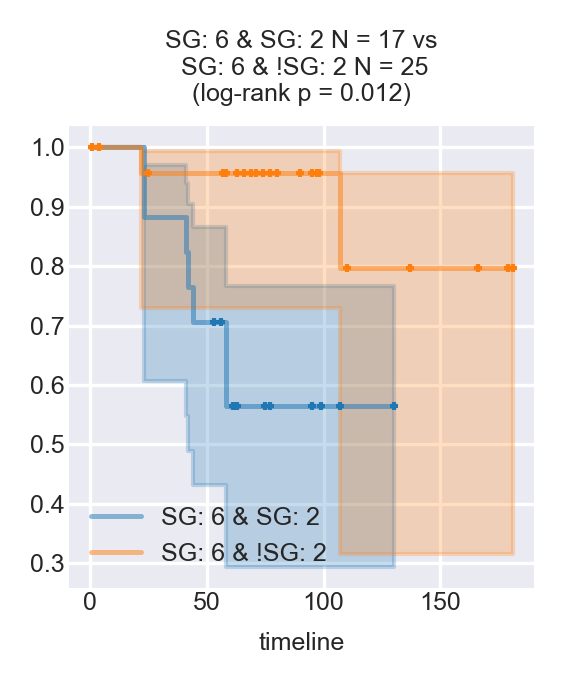

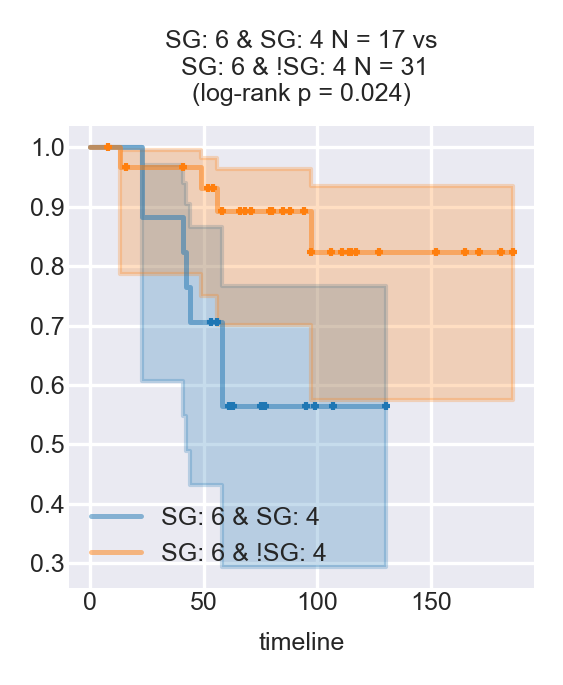

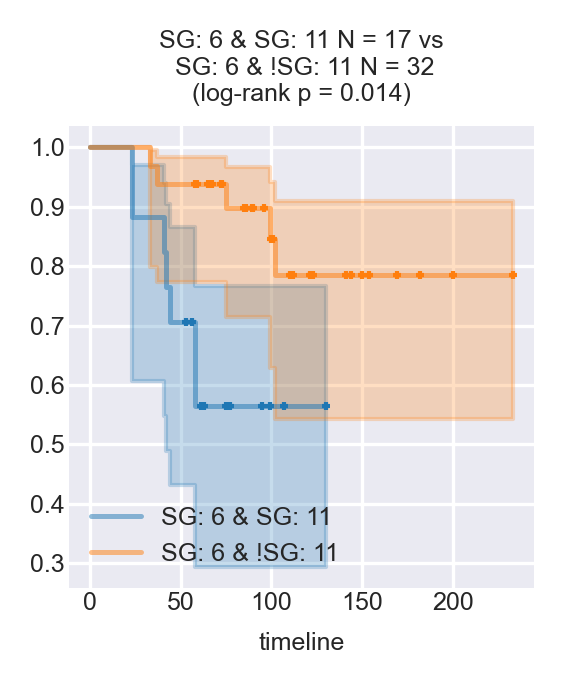

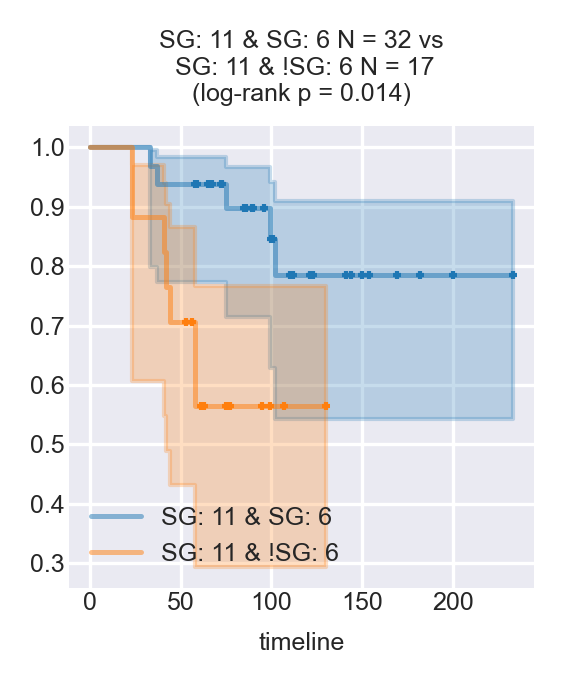

In [74]:
cross_cluster_log_rank_p_values = numpy.ones((len(JACKSON_GOOD_ROI_CLUSTERS), len(JACKSON_GOOD_ROI_CLUSTERS)))


for l_ind, l_roi_cc in enumerate(JACKSON_GOOD_ROI_CLUSTERS):
    for r_ind, r_roi_cc in enumerate(JACKSON_GOOD_ROI_CLUSTERS):
        l_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
        r_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[r_roi_cc] == 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 15 or r_N < 15:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        cross_cluster_log_rank_p_values[l_ind, r_ind] = current_test.p_value
        if cross_cluster_log_rank_p_values[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(2, 2), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & !{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} & {r_roi_cc} N = {l_current_df.shape[0]} vs\n {l_roi_cc} & !{r_roi_cc} N = {r_current_df.shape[0]}\n(log-rank p = {round(cross_cluster_log_rank_p_values[l_ind, r_ind], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            plt.show()

In [75]:
cross_cluster_log_rank_p_values_df = pandas.DataFrame(
    cross_cluster_log_rank_p_values,
    index=JACKSON_GOOD_ROI_CLUSTERS,
    columns=JACKSON_GOOD_ROI_CLUSTERS,
)
cross_cluster_log_rank_p_values_df.index.name = f'{ROI_PLOT_NAME} Clusters'
cross_cluster_log_rank_p_values_df.columns.name = f'{ROI_PLOT_NAME} Clusters'

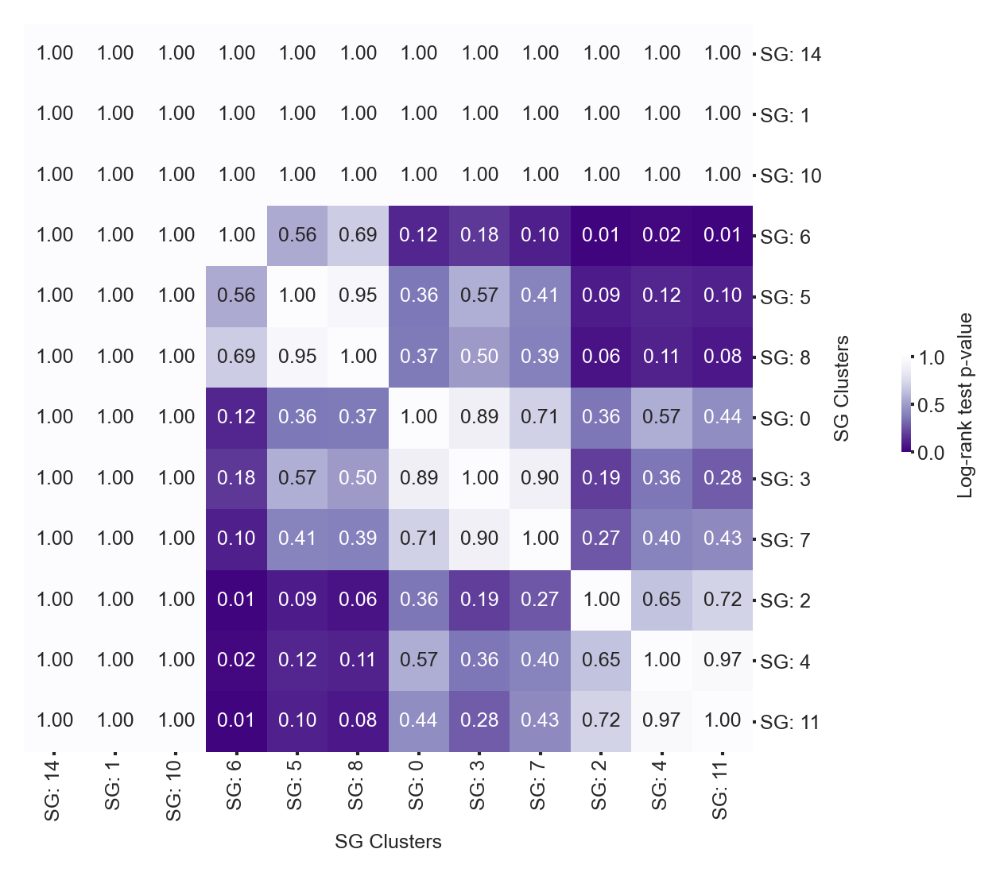

In [76]:
cross_cluster_log_rank_cmap = sns.clustermap(
    cross_cluster_log_rank_p_values_df,
    cmap='Purples_r',
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'Log-rank test p-value'},
)

cross_cluster_log_rank_cmap.ax_cbar.set_visible('False')
cross_cluster_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(rotation=0)

cross_cluster_log_rank_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
cross_cluster_log_rank_cmap.ax_row_dendrogram.set_visible(False)
cross_cluster_log_rank_cmap.ax_col_dendrogram.set_visible(False)

cross_cluster_log_rank_cmap.ax_heatmap.set_yticklabels(
    cross_cluster_log_rank_cmap.ax_heatmap.get_yticklabels(), size=6
)
cross_cluster_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
cross_cluster_log_rank_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
cross_cluster_log_rank_cmap.ax_heatmap.set_xticklabels(
    cross_cluster_log_rank_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

cross_cluster_log_rank_cmap.fig.set_dpi(PLOTTING_DPI)
cross_cluster_log_rank_cmap.fig.set_size_inches((4, 4))

### Clinical Type vs ROI analysis

/tmp/ipykernel_4104654/2471714626.py:55: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  handles = leg.legendHandles


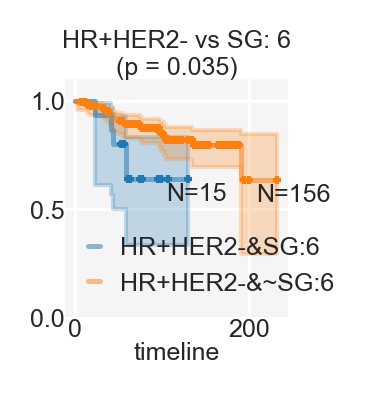

In [77]:
CLINICAL_TYPES = ['HR+HER2+', 'HR-HER2+', 'HR+HER2-', 'HR-HER2-']


cluster_vs_ct_log_rank_pvalues = numpy.ones((len(CLINICAL_TYPES), len(JACKSON_GOOD_ROI_CLUSTERS)))


for l_ind, l_roi_cc in enumerate(CLINICAL_TYPES):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
    for r_ind, r_roi_cc in enumerate(JACKSON_GOOD_ROI_CLUSTERS):
        l_current_df = current_df[current_df[r_roi_cc] == 1]
        r_current_df = current_df[current_df[r_roi_cc] != 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 15 or r_N < 15:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        cluster_vs_ct_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if cluster_vs_ct_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(1.2, 1.4), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & {r_roi_cc}'.replace(' ', ''))
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc}&~{r_roi_cc}'.replace(' ', ''))
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} vs {r_roi_cc}\n(p = {round(cluster_vs_ct_log_rank_pvalues[l_ind, r_ind], 3)})', 
                      size=6, pad=0)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.set_xlabel('timeline', labelpad=0)
            ax.grid(zorder=0)
            plt.ylim([0, 1.1])
            #ax.yaxis.set_ticks([0., 0.25, 0.5, 0.75, 1])
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            ax.grid(color='white', gapcolor='gray')
            l_x = ax.get_children()[1].get_xdata()[-1]
            l_y = ax.get_children()[1].get_ydata()[-1]
            plt.text(l_x - 25, l_y - 0.1, f'N={l_N}', size=6)
            leg = plt.gca().get_legend()
            r_x = ax.get_children()[3].get_xdata()[-1]
            r_y = ax.get_children()[3].get_ydata()[-1]
            plt.text(r_x - 25, r_y - 0.1, f'N={r_N}', size=6)
            ax.set_aspect(250)
            leg = plt.gca().get_legend()
            # Get the current legend properties
            labels = [text.get_text() for text in leg.get_texts()]
            handles = leg.legendHandles

# Remove old legend
            leg.remove()

# Create new legend with desired handle length
            plt.legend(handles, labels, handlelength=.5)
            ax.get_legend().handlelength = 0.1
#             for legend_line in ax.get_legend().get_lines():
#                 legend_line.set_xdata(legend_line.get_xdata() / 3.)
#             for t in ax.get_legend().get_texts():
#                 text_width = t.get_window_extent().width
#                 t.set_ha('right')
            #c
            plt.tight_layout()
            plt.show()

In [78]:
cluster_vs_ct_log_rank_pvalues_df = pandas.DataFrame(
    cluster_vs_ct_log_rank_pvalues,
    columns=JACKSON_GOOD_ROI_CLUSTERS,
    index=CLINICAL_TYPES,
)
cluster_vs_ct_log_rank_pvalues_df.columns.name = f'{ROI_PLOT_NAME} Clusters'
cluster_vs_ct_log_rank_pvalues_df.index.name = f'Clinical Type'

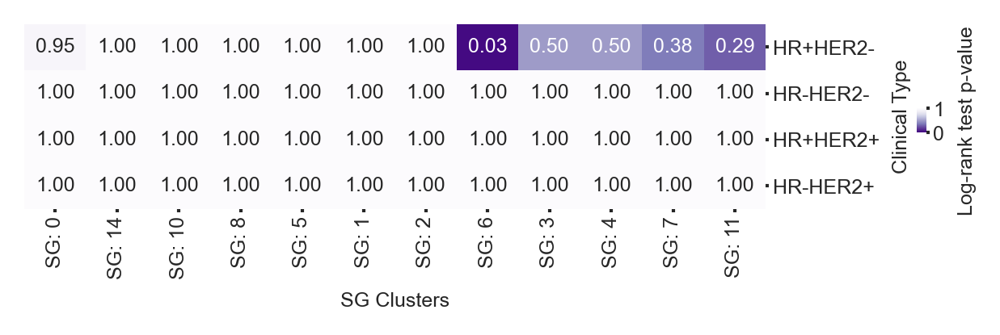

In [79]:
cluster_vs_ct_log_rank_cmap = sns.clustermap(
    cluster_vs_ct_log_rank_pvalues_df,
    cmap='Purples_r',
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'Log-rank test p-value'},
)

cluster_vs_ct_log_rank_cmap.ax_cbar.set_visible('False')
cluster_vs_ct_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(rotation=0)

cluster_vs_ct_log_rank_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
cluster_vs_ct_log_rank_cmap.ax_row_dendrogram.set_visible(False)
cluster_vs_ct_log_rank_cmap.ax_col_dendrogram.set_visible(False)

cluster_vs_ct_log_rank_cmap.ax_heatmap.set_yticklabels(
    cluster_vs_ct_log_rank_cmap.ax_heatmap.get_yticklabels(), size=6
)
cluster_vs_ct_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
cluster_vs_ct_log_rank_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
cluster_vs_ct_log_rank_cmap.ax_heatmap.set_xticklabels(
    cluster_vs_ct_log_rank_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

cluster_vs_ct_log_rank_cmap.fig.set_dpi(PLOTTING_DPI)
cluster_vs_ct_log_rank_cmap.fig.set_size_inches((4, 1))

### Clinical type vs ROI

/tmp/ipykernel_4104654/650781581.py:42: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  handles = leg.legendHandles


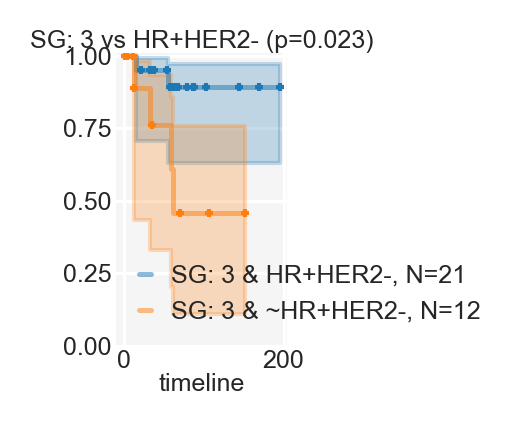

In [80]:
ct_vs_cluster_log_rank_pvalues = numpy.ones((len(JACKSON_GOOD_ROI_CLUSTERS), len(CLINICAL_TYPES)))


for l_ind, l_roi_cc in enumerate(JACKSON_GOOD_ROI_CLUSTERS):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
    for r_ind, r_roi_cc in enumerate(CLINICAL_TYPES):
        l_current_df = current_df[current_df[r_roi_cc] == 1]
        r_current_df = current_df[current_df[r_roi_cc] != 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        ct_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if ct_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(1.2, 1.4), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc.replace("ROI: ", "")} & {r_roi_cc}, N={l_N}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc.replace("ROI: ", "")} & ~{r_roi_cc}, N={r_N}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(
                f'{l_roi_cc} vs {r_roi_cc} (p={round(ct_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})',
                size=6, pad=0)
            ax.set_xlabel('timeline', labelpad=0)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            leg = plt.gca().get_legend()

            # Get the current legend properties
            labels = [text.get_text() for text in leg.get_texts()]
            handles = leg.legendHandles
            plt.ylim([0.0, 1.01])

# Remove old legend
            leg.remove()

# Create new legend with desired handle length
            plt.legend(handles, labels, handlelength=.5)
            ax.get_legend().handlelength = 0.1
#             for legend_line in ax.get_legend().get_lines():
#                 legend_line.set_xdata(legend_line.get_xdata() / 3.)
#             for t in ax.get_legend().get_texts():
#                 text_width = t.get_window_extent().width
#                 t.set_ha('right')
            ax.grid(color='white', gapcolor='gray')
            plt.tight_layout()
            plt.show()

In [81]:
ct_vs_cluster_log_rank_pvalues_df = pandas.DataFrame(
    ct_vs_cluster_log_rank_pvalues,
    index=JACKSON_GOOD_ROI_CLUSTERS,
    columns=CLINICAL_TYPES,
)
ct_vs_cluster_log_rank_pvalues_df.index.name = f'{ROI_PLOT_NAME} Clusters'
ct_vs_cluster_log_rank_pvalues_df.columns.name = f'Clinical Type'

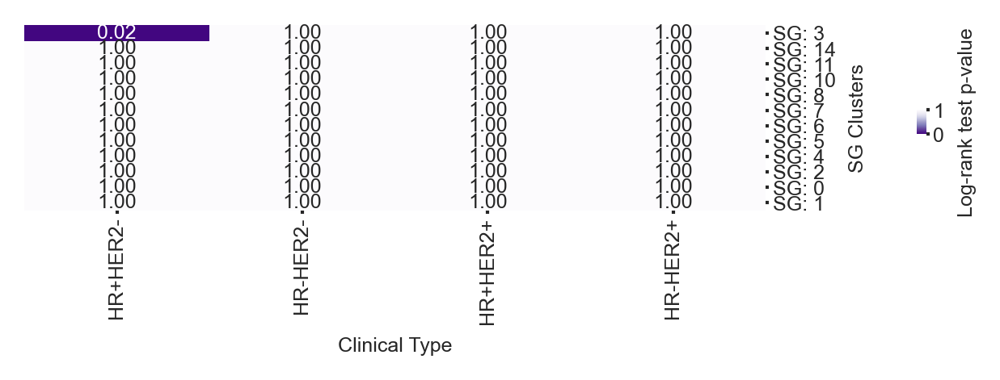

In [82]:
ct_vs_clusterlog_rank_cmap = sns.clustermap(
    ct_vs_cluster_log_rank_pvalues_df,
    cmap='Purples_r',
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'Log-rank test p-value'},
)

ct_vs_clusterlog_rank_cmap.ax_cbar.set_visible('False')
ct_vs_clusterlog_rank_cmap.ax_heatmap.xaxis.set_tick_params(rotation=0)

ct_vs_clusterlog_rank_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
ct_vs_clusterlog_rank_cmap.ax_row_dendrogram.set_visible(False)
ct_vs_clusterlog_rank_cmap.ax_col_dendrogram.set_visible(False)

ct_vs_clusterlog_rank_cmap.ax_heatmap.set_yticklabels(
    ct_vs_clusterlog_rank_cmap.ax_heatmap.get_yticklabels(), size=6
)
ct_vs_clusterlog_rank_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
ct_vs_clusterlog_rank_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
ct_vs_clusterlog_rank_cmap.ax_heatmap.set_xticklabels(
    ct_vs_clusterlog_rank_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

ct_vs_clusterlog_rank_cmap.fig.set_dpi(PLOTTING_DPI)
ct_vs_clusterlog_rank_cmap.fig.set_size_inches((4, 1))

## Grade vs ROI

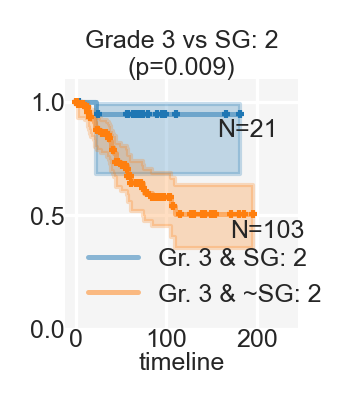

In [83]:
GRADES = [1, 2, 3]

grade_vs_cluster_log_rank_pvalues = numpy.ones((len(GRADES), len(JACKSON_GOOD_ROI_CLUSTERS)))

xticks_font = font_manager.FontProperties(family='Arial')


for l_ind, l_roi_cc in enumerate(GRADES):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_stage'] == l_roi_cc]
    for r_ind, r_roi_cc in enumerate(JACKSON_GOOD_ROI_CLUSTERS):
        l_current_df = current_df[current_df[r_roi_cc] == 1]
        r_current_df = current_df[current_df[r_roi_cc] != 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(1., 1.4), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'Gr. {l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'Gr. {l_roi_cc} & ~{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(
                f'Grade {l_roi_cc} vs {r_roi_cc}\n(p={round(grade_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})',
                size=6, pad=0)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.set_xlabel('timeline', labelpad=0)
            l_x = ax.get_children()[1].get_xdata()[-1]
            l_y = ax.get_children()[1].get_ydata()[-1]
            plt.text(l_x - 25, l_y - 0.1, f'N={l_N}', size=6)
            leg = plt.gca().get_legend()
            r_x = ax.get_children()[3].get_xdata()[-1]
            r_y = ax.get_children()[3].get_ydata()[-1]
            plt.text(r_x - 25, r_y - 0.1, f'N={r_N}', size=6)
            ax.grid(zorder=0)
            plt.ylim([0, 1.1])
            ax.set_aspect(250)
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            ax.grid(color='white', gapcolor='gray')
            plt.xlim((-11.65, 244.65))
            

## Marker Cluster analysis for cell types

Now let's analyse the marker expression for cells within certain Cellohood Clusters:

In [84]:
celltypes_to_marker_to_show = {
#    'CK+ HR hi': ['Estrogen', 'GATA3', 'HER2'],
    'CK+ HR hi': ['Estrogen', 'HER2'],
#    'CK+ HR lo': ['ECadherin', 'Histone-H3-1', 'Fibronectin'],
    'CK+ HR lo': ['Fibronectin'],
    'CK lo HR lo': ['cl.PARP', 'Slug'],
    'CK7+': ['mTOR'],
    'CK+ HR+': ['Slug', 'cl.PARP', 'PR', 'S6'],
    'T cell': ['CD45'],
    'All': ['Ki67', 'c-Myc', 'CAIX', 'vWF', 'SMA']
}

and analyze for which cluster they should be displayed:

In [85]:
celltypes_cc_display = {
    'CK+ HR hi': [ind_ for ind_, el in enumerate(celltype_percentages['CK+ HR hi'] > 0.05) if el >= 0.05],
    'CK+ HR lo': [ind_ for ind_, el in enumerate(celltype_percentages['CK+ HR lo'] > 0.05) if el >= 0.05],
    'CK lo HR lo': [ind_ for ind_, el in enumerate(celltype_percentages['CK lo HR lo'] > 0.05) if el >= 0.05],
    'CK7+': [ind_ for ind_, el in enumerate(celltype_percentages['CK7+'] > 0.05) if el >= 0.05],
    'CK+ HR+': [ind_ for ind_, el in enumerate(celltype_percentages['CK+ HR+'] > 0.05) if el >= 0.05],
    'T cell': [ind_ for ind_, el in enumerate(celltype_percentages['T cell'] > 0.05) if el >= 0.05],
}

Now - let's define the color-based for df:

In [86]:
cc_colors_dict = {}
for ct, markers in celltypes_to_marker_to_show.items():
    for marker in markers:
        cc_colors_dict[f'{ct}: {marker}'] = transform_vec_to_colors( 
                vec=celltype_to_marker_dfs_clean[ct].loc[marker],
                colors=marker_sm,
                display=celltypes_cc_display[ct] if ct in celltypes_cc_display else None,
            )


cc_marker_ct_colors = pandas.DataFrame(cc_colors_dict)

cc_marker_ct_colors['All: Cell density'] = transform_vec_to_colors( 
        vec=cc_densities,
        colors=marker_sm,
)

In [87]:
from matplotlib import cm as mcm
import matplotlib as mpl

norm = mpl.colors.Normalize(vmin=0, vmax=JACKSON_ROI_CLUSTERS)
cmap = plt.get_cmap('seismic')

seis_m = mcm.ScalarMappable(norm=norm, cmap=cmap)

/tmp/ipykernel_4104654/2449520928.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_4104654/2449520928.py:68: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


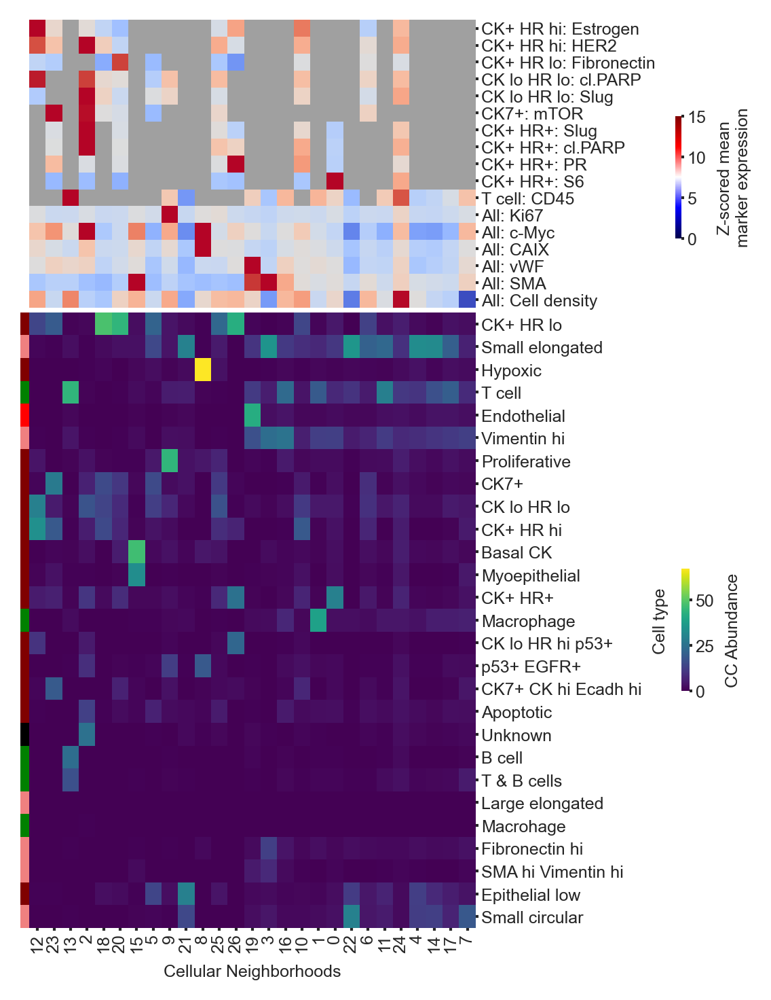

In [88]:
COLORBARS_SHIFT = 0.92

cc_abundance_std_argsort = (-sample_count_basel[AA_ADJUSTED_COLS].std(axis=0).values).argsort()

celltype_clustermap = sns.clustermap(
    (celltype_percentages[celltypes].T * 100)[cc_abundance_std_argsort], 
    #annot=True,
    col_cluster=False,
    #fmt='.0f',
    cmap='viridis',
    figsize=(5, 7),
    col_colors=cc_marker_ct_colors,
    row_colors=[class_to_color[celltype_to_class[ct]] for ct in numpy.array(celltypes)],
    colors_ratio=0.015,
    yticklabels=True,
    xticklabels=cc_abundance_std_argsort,
    #linewidth=0.003
    #annot_kws={"size": 3},
    cbar_pos=[COLORBARS_SHIFT + 0.05, 0.25, 0.01, .1],
    cbar_kws={'label': 'CC Abundance'}
)


handles = [Patch(facecolor=class_to_color[name]) for name in class_to_color]
#plt.legend(
#    handles, 
#    class_to_color, 
#    title=' Cell type Metatype',
#    bbox_to_anchor=(0.17, 0.53), 
#    bbox_transform=plt.gcf().transFigure,
#    frameon=False,
#    fontsize=6,
#)

celltype_clustermap.ax_col_dendrogram.set_visible(False)

cb_ax = celltype_clustermap.fig.add_axes([COLORBARS_SHIFT, .27, .05, .8])
cb_ax.imshow([[0, 1]])
cb_ax.set_visible(False)

cbar = celltype_clustermap.fig.colorbar(
    seis_m, 
    drawedges=False,
    #bbox_to_anchor=(1, 0.5),
    label='Z-scored mean\nmarker expression',
    ax=cb_ax,
    #panchor=(1.5, 0.5),
    #anchor=(1.5, 0.5),
)

cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=6, size=1, pad=1)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
celltype_clustermap.ax_col_colors.set_yticklabels(celltype_clustermap.ax_col_colors.get_yticklabels(), size=6)
celltype_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)


celltype_clustermap.fig.set_dpi(300)
celltype_clustermap.fig.set_size_inches((4, 6))
plt.tight_layout()

## Class-based analysis

In [89]:
# CDICT

class_to_marker_to_show = {
    'Tumor': [ 
        'c-Myc',       # Oncogene
        'CAIX',        # Hypoxia marker
        'Keratin-14',  # Basal cell marker
        'CK-5',        # Basal cell marker
        'PR',          # Progesterone receptor
        'CK 8/18',     # Luminal cell marker
        'panCK',       # Pan-cytokeratin, epithelial marker
        'CK 19',       # Cytokeratin 19, epithelial marker
        'CK 7',        # Epithelial marker
        'EGFR',        # Growth factor receptor, often in triple-negative breast cancer
        'p53',         # Tumor suppressor protein
        'HER2',        # Growth factor receptor, key breast cancer marker
        'Estrogen',    # Hormone receptor, key breast cancer marker
        'GATA3',       # Transcription factor, breast cancer marker
        'Ki67',        # Proliferation marker
        'ECad',        # Cell adhesion, loss can indicate EMT    
        'CD44',        # Cancer stem cell marker
        'cl.PARP',
        'Twist',
        'Fibronectin',
        'S6',
        'p-Histone',
        'DNA1',
    ],
    'Stroma': [
            'Vimentin',     # Mesenchymal cell marker, fibroblasts
    'SMA',          # Alpha smooth muscle actin, myofibroblasts/activated fibroblasts
    'Fibronectin',  # Extracellular matrix protein
    'vWF',          # von Willebrand Factor, endothelial cells/vasculature
        'DNA1',
    ],
    'Immune': [
        'CD20',      # B cells
        'CD45',      # Common leukocyte antigen, all immune cells
        'CD68',      # Macrophages
        'CD3epsi',   # T cells
        'DNA1',
    ]
}

In [90]:
class_cc_display = {
    'Tumor': [ind_ for ind_, el in enumerate(class_percentages['Tumor']) if el >= 0.2],
    'Stroma': [ind_ for ind_, el in enumerate(class_percentages['Stroma']) if el >= 0.2],
    'Immune': [ind_ for ind_, el in enumerate(class_percentages['Immune']) if el >= 0.2],
}

In [91]:
class_colors_dict = {}
for ct, markers in class_to_marker_to_show.items():
    for marker in markers:
        class_colors_dict[f'{ct}: {marker}'] = transform_vec_to_colors( 
                vec=celltype_to_marker_dfs_clean[ct].loc[marker],
                colors=marker_sm,
                display=class_cc_display[ct] if ct in class_cc_display else None,
            )


class_marker_ct_colors = pandas.DataFrame(class_colors_dict)

class_marker_ct_colors['All: Cell density'] = transform_vec_to_colors( 
        vec=cc_densities,
        colors=marker_sm,
)

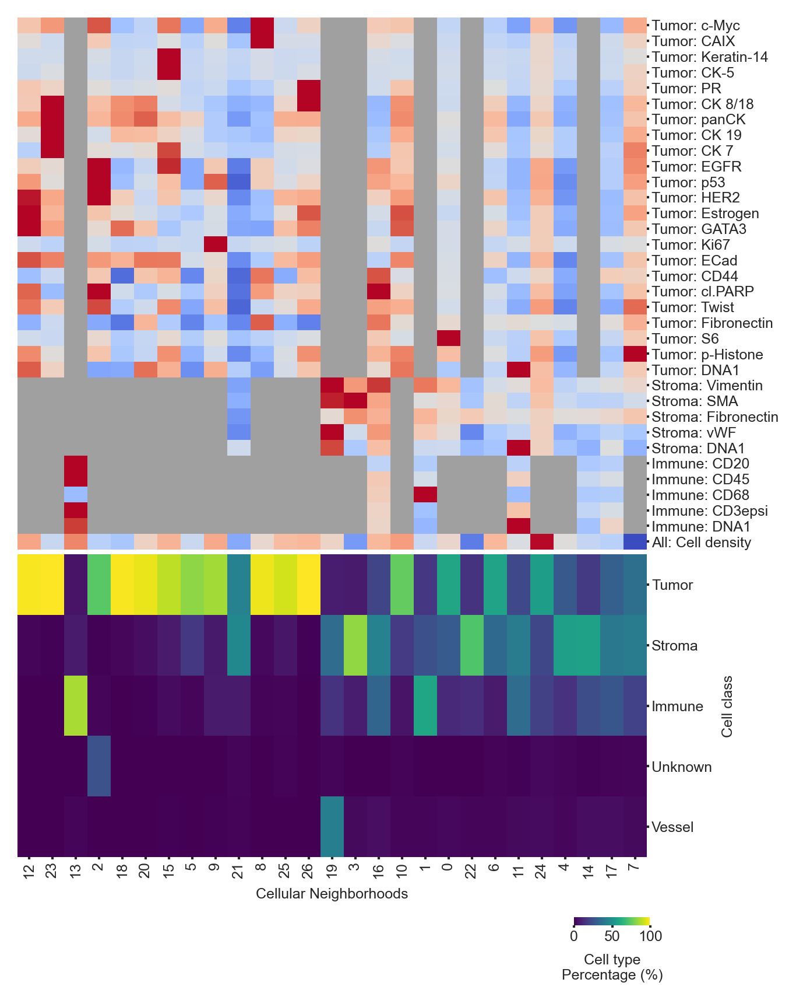

In [92]:
COLORBARS_SHIFT = 0.92

cc_abundance_std_argsort = (-sample_count_basel[AA_ADJUSTED_COLS].std(axis=0).values).argsort()

class_clustermap = sns.clustermap(
    (class_percentages.T * 100)[cc_abundance_std_argsort], 
    #annot=True,
    col_cluster=False,
    #fmt='.0f',
    cmap='viridis',
    figsize=(5.8, 6.5),
    col_colors=class_marker_ct_colors,
    colors_ratio=0.015,
    yticklabels=True,
    xticklabels=cc_abundance_std_argsort,
    #linewidth=0.003
    #annot_kws={"size": 3},
    cbar_pos=[COLORBARS_SHIFT - 0.2, 0., 0.075, .0075],
    cbar_kws={'label': 'Cell type\nPercentage (%)', 'orientation': 'horizontal'}
)


handles = [Patch(facecolor=class_to_color[name]) for name in class_to_color]
#plt.legend(
#    handles, 
#    class_to_color, 
#    title=' Cell type Metatype',
#    bbox_to_anchor=(0.17, 0.53), 
#    bbox_transform=plt.gcf().transFigure,
#    frameon=False,
#    fontsize=6,
#)

class_clustermap.ax_col_dendrogram.set_visible(False)

# cb_ax = class_clustermap.fig.add_axes([COLORBARS_SHIFT, .27, .7, .07])
# cb_ax.imshow([[0, 1]])
# cb_ax.set_visible(False)

# cbar = class_clustermap.fig.colorbar(
#     marker_sm, 
#     drawedges=False,
#     #bbox_to_anchor=(1, 0.5),
#     label='Z-scored mean\nmarker expression',
#     ax=cb_ax,
#     orientation='horizontal',
#     #panchor=(1.5, 0.5),
#     #anchor=(1.5, 0.5),
# )

# cbar.outline.set_visible(False)
# cbar.ax.tick_params(labelsize=6, size=1, pad=1)

class_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
class_clustermap.ax_cbar.set_xticks(
    [0, 50, 100],
    [0, 50, 100]
)
class_clustermap.ax_row_dendrogram.set_visible(False)
class_clustermap.ax_col_dendrogram.set_visible(False)

class_clustermap.ax_heatmap.set_yticklabels(class_clustermap.ax_heatmap.get_yticklabels(), size=6)
class_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
class_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1)
class_clustermap.ax_heatmap.set_xticklabels(class_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
class_clustermap.ax_col_colors.set_yticklabels(class_clustermap.ax_col_colors.get_yticklabels(), size=6)
class_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)


class_clustermap.fig.set_dpi(300)
#class_clustermap.fig.set_size_inches((4, 6))
#plt.tight_layout()

## Cluster analysis

In [93]:
clustering_df = pandas.DataFrame(
    clusterer.cluster_centers_[JACKSON_GOOD_ROI_CLUSTERS_INDS],
    index=JACKSON_GOOD_ROI_CLUSTERS,
    columns=[int(col[:-2]) for col in AA_ADJUSTED_COLS],
)

In [94]:
ct_norm = mpl.colors.Normalize(vmin=0, vmax=celltype_percentages.values.max())
ct_cmap = plt.get_cmap('viridis')

ct_sm = mcm.ScalarMappable(norm=ct_norm, cmap=ct_cmap)

In [95]:
full_cc_colors_with_ct = cc_marker_ct_colors.copy()

for celltype in celltype_clustermap.data2d.index:
    full_cc_colors_with_ct[f'{celltype}%'] = [
        ct_sm.to_rgba(x) for x in celltype_percentages[celltype]
    ]

In [96]:
# CCC

full_class_colors_with_ct = class_marker_ct_colors.copy()

for class_ in class_clustermap.data2d.index:
    full_class_colors_with_ct[f'{class_}%'] = [
        ct_sm.to_rgba(x) for x in class_percentages[class_]
    ]

In [97]:
full_cc_colors_with_ct.index = [i for i in range(full_cc_colors_with_ct.shape[0])]
full_class_colors_with_ct.index = [i for i in range(full_class_colors_with_ct.shape[0])]

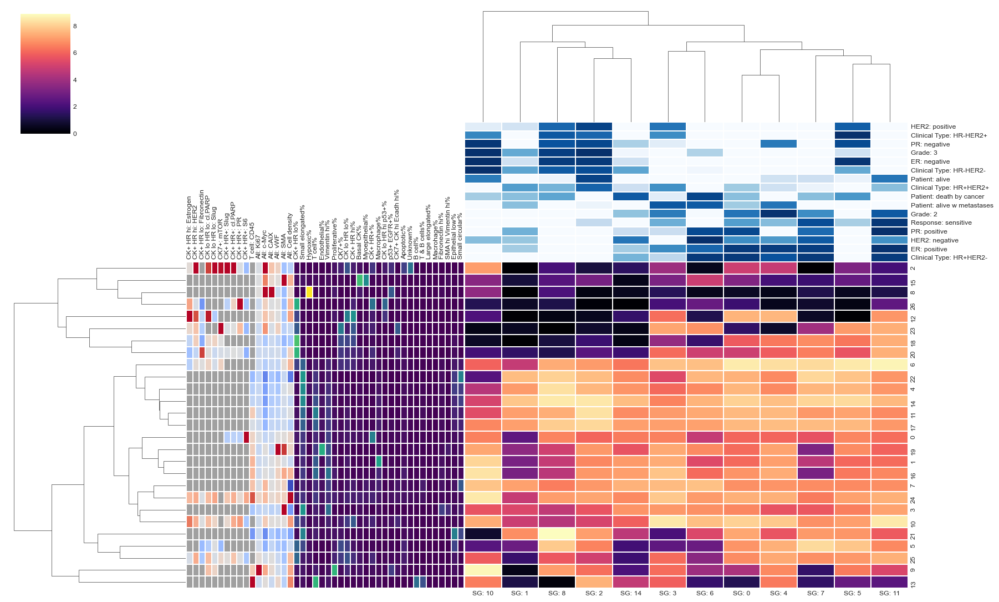

In [98]:
full_cm = sns.clustermap(
    clustering_df.T,  
    cmap='magma',
    col_colors=clinical_colors.T,
    row_colors=full_cc_colors_with_ct,
    figsize=(18, 12),
    colors_ratio=(0.007, 0.015),
    linewidth=0.00395,
    #vmin=-1.5,
    #vmax=1.5,
)

full_cm.ax_row_colors.xaxis.tick_top()
full_cm.ax_row_colors.xaxis.set_tick_params(rotation=90)
#dir(full_cm.ax_row_colors.xaxis)

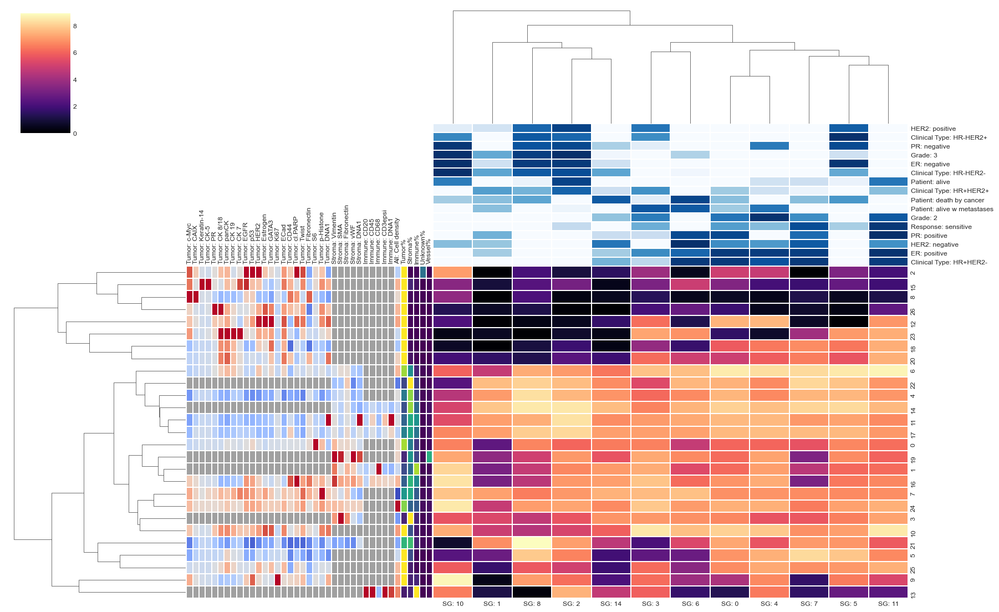

In [99]:
full_cm = sns.clustermap(
    clustering_df.T,  
    cmap='magma',
    col_colors=clinical_colors.T,
    row_colors=full_class_colors_with_ct,
    figsize=(18, 12),
    colors_ratio=(0.007, 0.015),
    linewidth=0.00395,
    #vmin=-1.5,
    #vmax=1.5,
)

full_cm.ax_row_colors.xaxis.tick_top()
full_cm.ax_row_colors.xaxis.set_tick_params(rotation=90)
#dir(full_cm.ax_row_colors.xaxis)

Now, the figure with only clinical features:

In [100]:
clinical_colors_with_cluster_color = clinical_colors.copy().T
#clinical_colors_with_cluster_color['ROI Cluster'] = [cluster_sm.to_rgba(x) for x in JACKSON_GOOD_ROI_CLUSTERS_INDS]

In [101]:
clustering_df.index.name = ''
clustering_df.columns.name = 'Cellohood\nNeighborhood\nCluster'

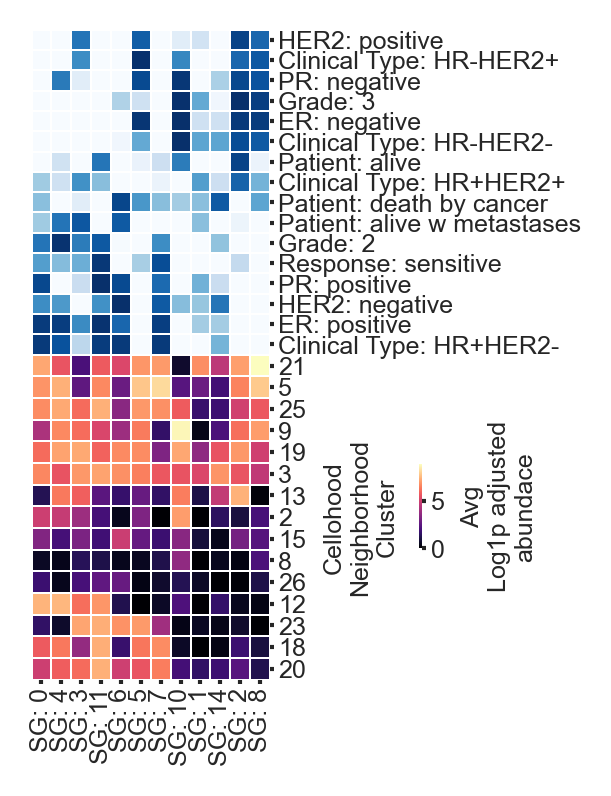

In [102]:
clusters_with_clinical = sns.clustermap(
    clustering_df[cc_abundance_std_argsort[:15]].T,  
    cmap='magma',
    col_colors=clinical_colors_with_cluster_color,
    colors_ratio=(0.025),
    xticklabels=[el.replace('ROI: ', '') for el in clustering_df.index],
    linewidth=0.00395,
    cbar_pos=[1.25, 0.18, 0.01, .1],
    cbar_kws={'label': 'Avg\nLog1p adjusted\nabundace'},
)


clusters_with_clinical.ax_heatmap.xaxis.set_tick_params(rotation=0)
#clusters_with_clinical.ax_heatmap.set_xlabel('Cellohood Neighborhood\nCluster')

clusters_with_clinical.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
clusters_with_clinical.ax_row_dendrogram.set_visible(False)
clusters_with_clinical.ax_col_dendrogram.set_visible(False)

clusters_with_clinical.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
clusters_with_clinical.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
clusters_with_clinical.ax_heatmap.set_xticklabels(
    clusters_with_clinical.ax_heatmap.get_xticklabels(), size=6, rotation=90
)
clusters_with_clinical.ax_heatmap.set_yticklabels(
    clusters_with_clinical.ax_heatmap.get_yticklabels(), size=6, rotation=0
)
clusters_with_clinical.ax_col_colors.yaxis.set_tick_params(size=1, pad=1, rotation=0)
clusters_with_clinical.ax_col_colors.set_yticklabels(
    clusters_with_clinical.ax_col_colors.get_yticklabels(), size=6,
)
clusters_with_clinical.fig.set_dpi(PLOTTING_DPI)
clusters_with_clinical.fig.set_size_inches((1.2, 2.8))

/tmp/ipykernel_4104654/1357350305.py:187: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  patient_clustermap.fig.tight_layout()


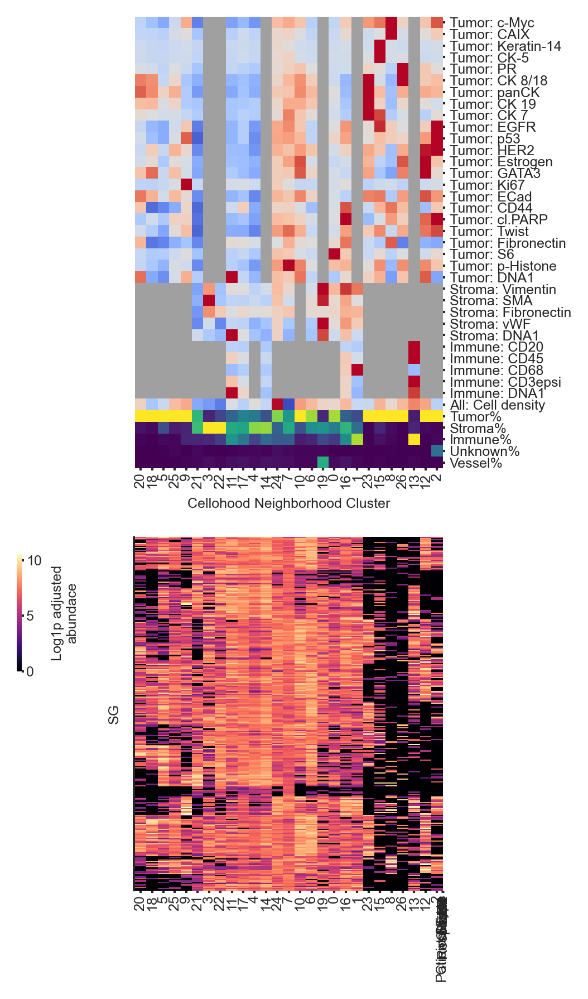

In [103]:
from matplotlib import cm as mcm
import matplotlib as mpl

cluster_norm = mpl.colors.Normalize(vmin=0, vmax=JACKSON_ROI_CLUSTERS)
cluster_cmap = plt.get_cmap('nipy_spectral')

cluster_sm = mcm.ScalarMappable(norm=cluster_norm, cmap=cluster_cmap)

vectors_df = pandas.DataFrame(
    vectors.T,
    index=patient_to_clinical_colors_df.index,
)
vectors_df.index.name = ROI_PLOT_NAME
vectors_df.columns.name = CC_PLOT_NAME


patient_to_clinical_colors_df['Cluster'] = [cluster_sm.to_rgba(x) for x in clusters]

patient_clustermap = sns.clustermap( 
    vectors_df.iloc[clusters.argsort()].T.iloc[(-vectors_df.std(axis=0)).argsort()].T,
    #col_cluster=False,
    row_cluster=False,
    xticklabels=1,
    cbar_pos=[-0.05, 0.3, 0.01, .1],
    cbar_kws={'label': 'Log1p adjusted\nabundace'},
    yticklabels=ticks,
    row_colors=patient_to_clinical_colors_df,
    figsize=(6, 8),
    linewidths=(0.000, 0.01),
    colors_ratio=(0.0000001, 0.0115),
    col_colors=full_class_colors_with_ct,
    cmap='magma',
)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(rotation=0)

patient_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
patient_clustermap.ax_row_dendrogram.set_visible(False)
patient_clustermap.ax_col_dendrogram.set_visible(False)

patient_clustermap.ax_heatmap.set_yticklabels(
    [], size=6)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
patient_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
patient_clustermap.ax_heatmap.set_xticklabels(
    patient_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)


patient_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
patient_clustermap.ax_row_colors.set_xticklabels(
    patient_clustermap.ax_row_colors.get_xticklabels(), size=6,
)
#patient_clustermap.ax_row_colors.xaxis.tick_top()
patient_clustermap.ax_heatmap.yaxis.tick_left()

patient_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=2, rotation=0)
patient_clustermap.ax_col_colors.set_yticklabels(
    patient_clustermap.ax_col_colors.get_yticklabels(), size=6,
)
patient_clustermap.ax_col_colors.xaxis.set_tick_params(size=1, pad=1, rotation=0)
patient_clustermap.ax_col_colors.set_xticks(
    patient_clustermap.ax_heatmap.get_xticks(), 
    labels=patient_clustermap.ax_heatmap.get_xticklabels(),
    size=6,
    rotation=90,
)
patient_clustermap.ax_col_colors.set_xlabel('Cellohood Neighborhood Cluster')
patient_clustermap.ax_heatmap.set_xlabel('')


#patient_clustermap.ax_col_colors.set_yticklabels(
#    patient_clustermap.ax_col_colors.get_yticklabels(), size=6
#)
#patient_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)
patient_clustermap.ax_heatmap.yaxis.set_label_position('left')

HORIZONTAL_START = 0.09
LEGEND_START = -0.1

# pos_neg_handles = [Patch(facecolor=er_color[name], edgecolor='black') for name in er_color]
# pos_neg_legend = plt.legend(
#     pos_neg_handles, 
#     ['Yes', 'No', 'Unk'], 
#     title='ER, PR, HER2',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .95), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='left',
#     markerfirst=True,
#     labelspacing=0.1,
# )
# plt.gcf().add_artist(pos_neg_legend)


# grade_handles = [Patch(facecolor=grade_color[name], edgecolor='black') for name in grade_color]
# grade_legend = plt.legend(
#     grade_handles, 
#     [1, 2, 3, 'Unk'], 
#     title='Grade',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .8), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='left',
#     markerfirst=True,
#     labelspacing=0.1,
# )
# plt.gcf().add_artist(grade_legend)

# ps_handles = [
#     Patch(facecolor=ps_color[name], edgecolor='black')
#     for name in ['alive', 'alive w metastases', 'death by primary disease', 'death']
# ]
# ps_legend = plt.legend(
#     ps_handles, 
#     ['alive', 'alive w.metastases', 'death (primary disease)', 'death (other)'], 
#     title='Patient Status',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .65), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='left',
#     markerfirst=True,
#     labelspacing=0.1,
# )
# plt.gcf().add_artist(ps_legend)

# response_handles = [Patch(facecolor=response_color[name], edgecolor='black') for name in response_color]
# response_legend = plt.legend(
#     response_handles, 
#     ['Refractory', 'Resistant', 'Sensitive', 'Unk'], 
#     title='Response',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .5), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='left',
#     markerfirst=True,
#     labelspacing=0.1,
# )
# plt.gcf().add_artist(grade_legend)

# clinical_handles = [Patch(facecolor=clinical_type_color[name], edgecolor='black') for name in clinical_type_color]
# clinical_legend = plt.legend(
#     clinical_handles[:4], 
#     ['HR+HER2-', 'HR+HER2+', 'HR-HER2+', 'HR-HER2-'], 
#     title='Clinical Type',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .35), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='center',
#     markerfirst=True,
#     labelspacing=0.1,
#     ncol=2,
# )
# plt.gcf().add_artist(clinical_legend)

ax_row_colors = patient_clustermap.ax_row_colors
ax_col_colors = patient_clustermap.ax_col_colors
row_box = ax_row_colors.get_position()
col_box = ax_col_colors.get_position()

box_heatmap = patient_clustermap.ax_heatmap.get_position()
ax_row_colors.set_position([box_heatmap.max[0], row_box.y0, row_box.width*1.5, row_box.height])
ax_col_colors.set_position([col_box.x0, col_box.y0 + 0.05, col_box.width, col_box.height])


"""
cluster_handles = [
    Patch(facecolor=cluster_sm.to_rgba(x), edgecolor='black')
    for x in range(JACKSON_ROI_CLUSTERS)
]
cluster_legend = plt.legend(
    cluster_handles, 
    [f'{ROI_PLOT_NAME}: {ind_}' for ind_ in range(JACKSON_ROI_CLUSTERS)], 
    title=f'{ROI_PLOT_NAME} Cluster',
    bbox_to_anchor=(LEGEND_SPACING, .4125), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(clinical_legend)
"""
patient_clustermap.fig.tight_layout()
patient_clustermap.fig.set_dpi(PLOTTING_DPI)
patient_clustermap.fig.set_size_inches((3, 7))

/tmp/ipykernel_4104654/2959894083.py:187: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  patient_clustermap.fig.tight_layout()


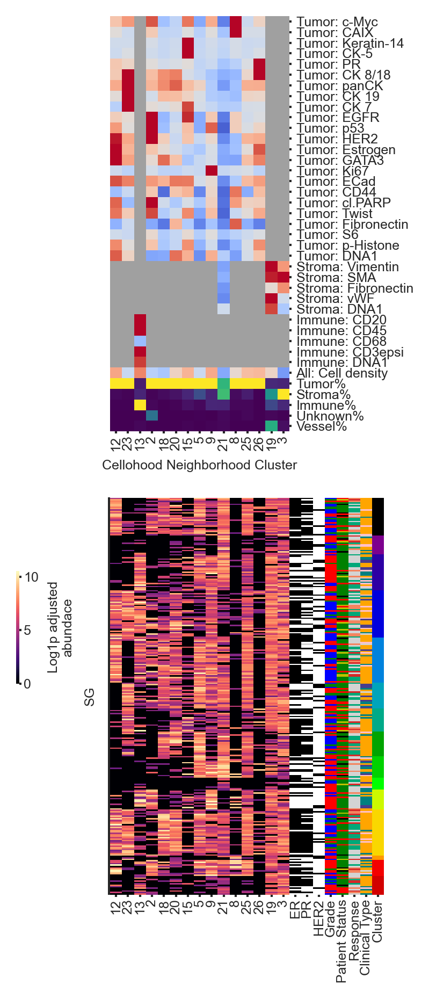

In [104]:
from matplotlib import cm as mcm
import matplotlib as mpl

cluster_norm = mpl.colors.Normalize(vmin=0, vmax=JACKSON_ROI_CLUSTERS)
cluster_cmap = plt.get_cmap('nipy_spectral')

cluster_sm = mcm.ScalarMappable(norm=cluster_norm, cmap=cluster_cmap)

vectors_df = pandas.DataFrame(
    vectors.T,
    index=patient_to_clinical_colors_df.index,
)
vectors_df.index.name = ROI_PLOT_NAME
vectors_df.columns.name = CC_PLOT_NAME


patient_to_clinical_colors_df['Cluster'] = [cluster_sm.to_rgba(x) for x in clusters]

patient_clustermap = sns.clustermap( 
    vectors_df.iloc[clusters.argsort()].T.iloc[cc_abundance_std_argsort[:15]].T,
    col_cluster=False,
    row_cluster=False,
    xticklabels=1,
    cbar_pos=[-0.05, 0.3, 0.01, .1],
    cbar_kws={'label': 'Log1p adjusted\nabundace'},
    yticklabels=ticks,
    row_colors=patient_to_clinical_colors_df,
    figsize=(6, 8),
    linewidths=(0.000, 0.017),
    colors_ratio=(0.01, 0.01),
    col_colors=full_class_colors_with_ct,
    cmap='magma',
)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(rotation=0)

patient_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
patient_clustermap.ax_row_dendrogram.set_visible(False)
patient_clustermap.ax_col_dendrogram.set_visible(False)

patient_clustermap.ax_heatmap.set_yticklabels(
    [], size=6)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
patient_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
patient_clustermap.ax_heatmap.set_xticklabels(
    patient_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)


patient_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
patient_clustermap.ax_row_colors.set_xticklabels(
    patient_clustermap.ax_row_colors.get_xticklabels(), size=6,
)
#patient_clustermap.ax_row_colors.xaxis.tick_top()
patient_clustermap.ax_heatmap.yaxis.tick_left()

patient_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=2, rotation=0)
patient_clustermap.ax_col_colors.set_yticklabels(
    patient_clustermap.ax_col_colors.get_yticklabels(), size=6,
)
patient_clustermap.ax_col_colors.xaxis.set_tick_params(size=1, pad=1, rotation=0)
patient_clustermap.ax_col_colors.set_xticks(
    patient_clustermap.ax_heatmap.get_xticks(), 
    labels=patient_clustermap.ax_heatmap.get_xticklabels(),
    size=6,
    rotation=90,
)
patient_clustermap.ax_col_colors.set_xlabel('Cellohood Neighborhood Cluster')
patient_clustermap.ax_heatmap.set_xlabel('')


#patient_clustermap.ax_col_colors.set_yticklabels(
#    patient_clustermap.ax_col_colors.get_yticklabels(), size=6
#)
#patient_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)
patient_clustermap.ax_heatmap.yaxis.set_label_position('left')

HORIZONTAL_START = 0.09
LEGEND_START = -0.1

# pos_neg_handles = [Patch(facecolor=er_color[name], edgecolor='black') for name in er_color]
# pos_neg_legend = plt.legend(
#     pos_neg_handles, 
#     ['Yes', 'No', 'Unk'], 
#     title='ER, PR, HER2',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .95), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='left',
#     markerfirst=True,
#     labelspacing=0.1,
# )
# plt.gcf().add_artist(pos_neg_legend)


# grade_handles = [Patch(facecolor=grade_color[name], edgecolor='black') for name in grade_color]
# grade_legend = plt.legend(
#     grade_handles, 
#     [1, 2, 3, 'Unk'], 
#     title='Grade',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .8), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='left',
#     markerfirst=True,
#     labelspacing=0.1,
# )
# plt.gcf().add_artist(grade_legend)

# ps_handles = [
#     Patch(facecolor=ps_color[name], edgecolor='black')
#     for name in ['alive', 'alive w metastases', 'death by primary disease', 'death']
# ]
# ps_legend = plt.legend(
#     ps_handles, 
#     ['alive', 'alive w.metastases', 'death (primary disease)', 'death (other)'], 
#     title='Patient Status',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .65), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='left',
#     markerfirst=True,
#     labelspacing=0.1,
# )
# plt.gcf().add_artist(ps_legend)

# response_handles = [Patch(facecolor=response_color[name], edgecolor='black') for name in response_color]
# response_legend = plt.legend(
#     response_handles, 
#     ['Refractory', 'Resistant', 'Sensitive', 'Unk'], 
#     title='Response',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .5), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='left',
#     markerfirst=True,
#     labelspacing=0.1,
# )
# plt.gcf().add_artist(grade_legend)

# clinical_handles = [Patch(facecolor=clinical_type_color[name], edgecolor='black') for name in clinical_type_color]
# clinical_legend = plt.legend(
#     clinical_handles[:4], 
#     ['HR+HER2-', 'HR+HER2+', 'HR-HER2+', 'HR-HER2-'], 
#     title='Clinical Type',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .35), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='center',
#     markerfirst=True,
#     labelspacing=0.1,
#     ncol=2,
# )
# plt.gcf().add_artist(clinical_legend)

ax_row_colors = patient_clustermap.ax_row_colors
ax_col_colors = patient_clustermap.ax_col_colors
row_box = ax_row_colors.get_position()
col_box = ax_col_colors.get_position()

box_heatmap = patient_clustermap.ax_heatmap.get_position()
ax_row_colors.set_position([box_heatmap.max[0], row_box.y0, row_box.width * 4.75 , row_box.height])
ax_col_colors.set_position([col_box.x0, col_box.y0 + 0.05, col_box.width, col_box.height * 1.1])


"""
cluster_handles = [
    Patch(facecolor=cluster_sm.to_rgba(x), edgecolor='black')
    for x in range(JACKSON_ROI_CLUSTERS)
]
cluster_legend = plt.legend(
    cluster_handles, 
    [f'{ROI_PLOT_NAME}: {ind_}' for ind_ in range(JACKSON_ROI_CLUSTERS)], 
    title=f'{ROI_PLOT_NAME} Cluster',
    bbox_to_anchor=(LEGEND_SPACING, .4125), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(clinical_legend)
"""
patient_clustermap.fig.tight_layout()
patient_clustermap.fig.set_dpi(PLOTTING_DPI)
patient_clustermap.fig.set_size_inches((2, 7))

## Camera ready COX plot

/tmp/ipykernel_4104654/398399795.py:16: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = ax.set_xticklabels(ax.get_xticklabels(), size=6)


Text(0.5, 1.0, 'Cox Model')

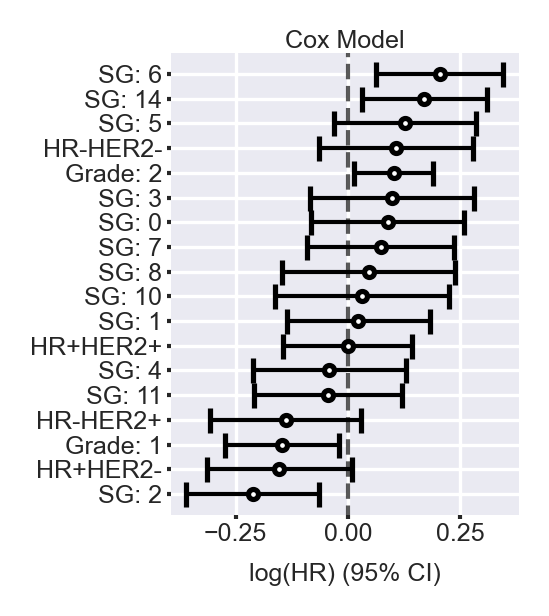

In [105]:

#COVS_TO_PLOT = [
#     el for el in jackson_cox.summary.sort_values('coef', ascending=False).index 
#     if el not in ['pl_15_13', 'pl_15_9']
# ]
plt.style.use('seaborn-v0_8-darkgrid')
plt.figure(figsize=(1.5, 2), dpi=300)
ax = jackson_cox.plot()
ax.get_children()[0].set_marker('.')
ax.get_children()[1].set_linewidth(1)
ax.get_children()[2].set_linewidth(0.00)
ax.get_children()[5].set_linewidth(0.00)
ax.get_children()[6].set_color('blue')
yticklabels = [el.get_text() for el in ax.get_yticklabels()]
_ = ax.set_yticklabels(rename_cox_summary_index(yticklabels, prefix='SG'), size=6)
ax.yaxis.set_tick_params(pad=1, size=1)
_ = ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.xaxis.set_tick_params(pad=1, size=1)
ax.set_title('Cox Model', fontsize=6, pad=1)

# BIG-L Fiugre

In [106]:
big_l_full_cc_colors_with_ct = full_cc_colors_with_ct.copy()
EXCLUDE_COLS = [
    'Unknown%',
    'Macrohage%',
    'Large elongated%',
]
big_l_full_cc_colors_with_ct = big_l_full_cc_colors_with_ct[
    [col for col in big_l_full_cc_colors_with_ct.columns if col not in EXCLUDE_COLS]
]

In [107]:
big_l_clustering_df = clustering_df.copy()
big_l_clustering_df.columns.name = ''

In [108]:
def clean_up_big_l_clinical_tick(tick):
    tick_text = tick.get_text()
    #print(tick.text)
    tick_text = tick_text.replace(': positive', '+')
    tick_text = tick_text.replace(': negative', '-')
    tick_text = tick_text.replace('Clinical Type: ', '')
    tick_text = tick_text.replace('Patient: ', 'P.')
    return tick_text


Text(0.5, 266.69444444444446, 'Slide Group')

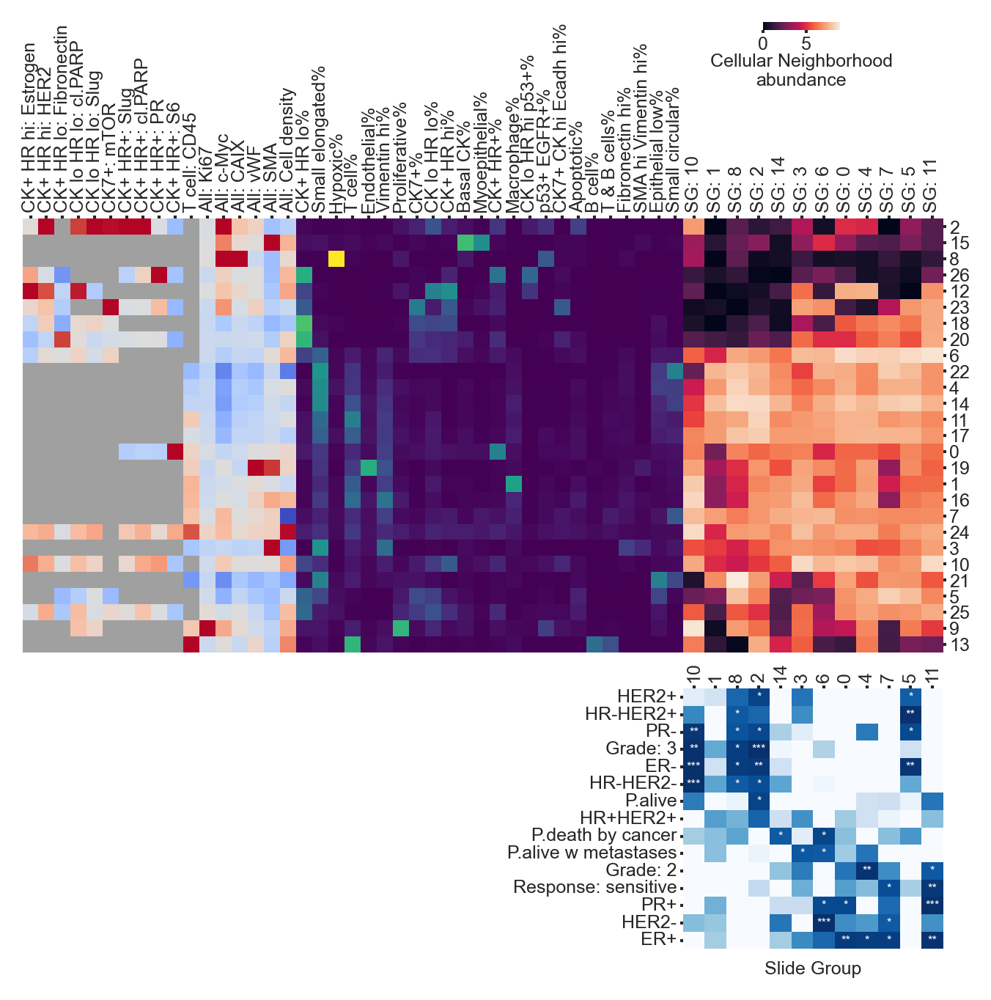

In [109]:
mpl.rcParams['font.family'] = 'Arial'

big_l_figure = sns.clustermap(
    big_l_clustering_df.T,
    figsize=(7, 5.5),
    row_colors=big_l_full_cc_colors_with_ct,
    col_colors=clinical_colors_with_cluster_color[list(clinical_colors_with_cluster_color.columns)[:-1]],
    colors_ratio=(0.014, 0.02),
    xticklabels=True,
    yticklabels=True,
    cbar_pos=[0.65, 0.77, 0.05, 0.007],
    cbar_kws={'label': 'CN abundance', 'aspect': 10, 'orientation': 'horizontal'}
)

big_l_figure.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_heatmap.set_yticklabels(
    big_l_figure.ax_heatmap.get_yticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_heatmap.set_xticklabels(
    big_l_figure.ax_heatmap.get_xticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.tick_top()

big_l_figure.ax_col_colors.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_col_colors.set_yticklabels(
    [clean_up_big_l_clinical_tick(tick) for tick in big_l_figure.ax_col_colors.get_yticklabels()],
    size=6,
)

big_l_figure.ax_col_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_col_colors.xaxis.tick_top()
big_l_figure.ax_col_colors.set_xticks(
    ticks=[i + 0.5 for i in range(len(big_l_figure.data2d.columns))],
    labels=[int(x.split(':')[1]) for x in big_l_figure.data2d.columns],
    size=6,
)

big_l_figure.ax_row_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_row_colors.set_xticklabels(
    big_l_figure.ax_row_colors.get_xticklabels(), size=6,
)
big_l_figure.ax_row_colors.xaxis.tick_top()
big_l_figure.ax_col_colors.yaxis.tick_left()

ax_row_colors = big_l_figure.ax_row_colors
ax_col_colors = big_l_figure.ax_col_colors
row_box = ax_row_colors.get_position()
col_box = ax_col_colors.get_position()

box_heatmap = big_l_figure.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.min[1] - col_box.height - 0.03, col_box.width, col_box.height])
ax_row_colors.set_position([box_heatmap.min[0] - row_box.width, row_box.y0, row_box.width, row_box.height])


big_l_figure.ax_col_dendrogram.set_visible(False)
big_l_figure.ax_row_dendrogram.set_visible(False)
#big_l_figure.ax_cbar.set_visible(False)
big_l_figure.fig.set_dpi(PLOTTING_DPI)
#big_l_figure.fig.set_size_inches((9, 6.5))

#big_l_figure.ax_cbar.outline.set_visible(False)
big_l_figure.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
big_l_figure.ax_cbar.set_xlabel('Cellular Neighborhood\nabundance', labelpad=0, size=6)

annot_shape = clinical_cm.data2d.values.shape
permuted_rois = list(big_l_figure.data2d.columns)
permuted_features = list(clinical_cm.data2d.index)

for i in range(annot_shape[1]):
    for j in range(annot_shape[0]):
        current_text = clinical_cm.data2d.T.loc[permuted_rois[i]].loc[permuted_features[j]]
        current_text = round(current_text, 2)
        stars = ''
        if current_text < 0.2:
            stars += '*'
        if current_text < 0.05:
            stars += '*'
        if current_text < 0.01:
            stars += '*'
        big_l_figure.ax_col_colors.text(
            i + 0.5, j + 0.5, 
            stars, 
            horizontalalignment='center', 
            verticalalignment='center',
            c='w', size=4)
        
big_l_figure.ax_col_colors.set_xlabel('Slide Group')

In [110]:
class_argsort = [8, 15, 26, 23, 2, 12, 9, 20, 25,  5,  18, 10,  0, 6, 24, 21,
        7,  4, 17, 16, 11, 3, 22, 14,  1, 13, 19]

In [111]:
sg_order = [col for col in clinical_cm.data2d.columns if col in big_l_clustering_df.index]

In [112]:
full_class_colors_with_ct.columns = [
    col.replace('%', '')
    for col in full_class_colors_with_ct.columns
]

In [113]:
full_class_colors_with_ct.insert(
    full_class_colors_with_ct.shape[1] - 5,
    '',
    [(1., 1., 1., 1.) for _ in range(full_class_colors_with_ct.shape[0])]
)

In [114]:
big_l_clustering_df.columns.name = 'Cellular Neighborhood\n(PLDA.100)'


In [115]:
full_class_colors_with_ct.columns = [
    col.replace('Estrogen', 'ER').replace('CD3epsi', 'CD3') for col in full_class_colors_with_ct.columns
]

In [116]:
sg_counts = roi_cluster_with_clinical[
    [
        col for col in roi_cluster_with_clinical.columns if col.startswith('SG:')]
].sum().to_frame()

In [117]:
clinical_counts_for_big_l = pandas.DataFrame(
    [
        (roi_cluster_with_clinical['HER2Status'] == 'positive').sum(), #
        (roi_cluster_with_clinical['HR-HER2+']).sum(), #
        (roi_cluster_with_clinical['PRStatus'] == 'negative').sum(), #
        (roi_cluster_with_clinical['grade'] == 3).sum(), #
        (roi_cluster_with_clinical['ERStatus'] == 'negative').sum(), #
        (roi_cluster_with_clinical['HR-HER2-']).sum(), #
        (roi_cluster_with_clinical['Patientstatus'] == 'alive').sum(), #
        (roi_cluster_with_clinical['HR+HER2-']).sum(), #
        (roi_cluster_with_clinical['Patientstatus'] == 'death by primary disease').sum(), #
        (roi_cluster_with_clinical['Patientstatus'] == 'alive w metastases').sum(), #
        (roi_cluster_with_clinical['grade'] == 2).sum(), #
        (roi_cluster_with_clinical['response'] == 'Sensitive').sum(), #
        (roi_cluster_with_clinical['PRStatus'] == 'positive').sum(), #
        (roi_cluster_with_clinical['HER2Status'] == 'negative').sum(),
        (roi_cluster_with_clinical['ERStatus'] == 'positive').sum(), #
        (roi_cluster_with_clinical['HR+HER2-']).sum(),
    ],
    index=clinical_cm.data2d.index
)

['SG: 5', 'SG: 8', 'SG: 2', 'SG: 10', 'SG: 3', 'SG: 4', 'SG: 11', 'SG: 0', 'SG: 7', 'SG: 6', 'SG: 1', 'SG: 14'] ['HER2: positive', 'Clinical Type: HR-HER2+', 'PR: negative', 'Grade: 3', 'ER: negative', 'Clinical Type: HR-HER2-', 'Patient: alive', 'Clinical Type: HR+HER2+', 'Patient: death by cancer', 'Patient: alive w metastases', 'Grade: 2', 'Response: sensitive', 'PR: positive', 'HER2: negative', 'ER: positive', 'Clinical Type: HR+HER2-']


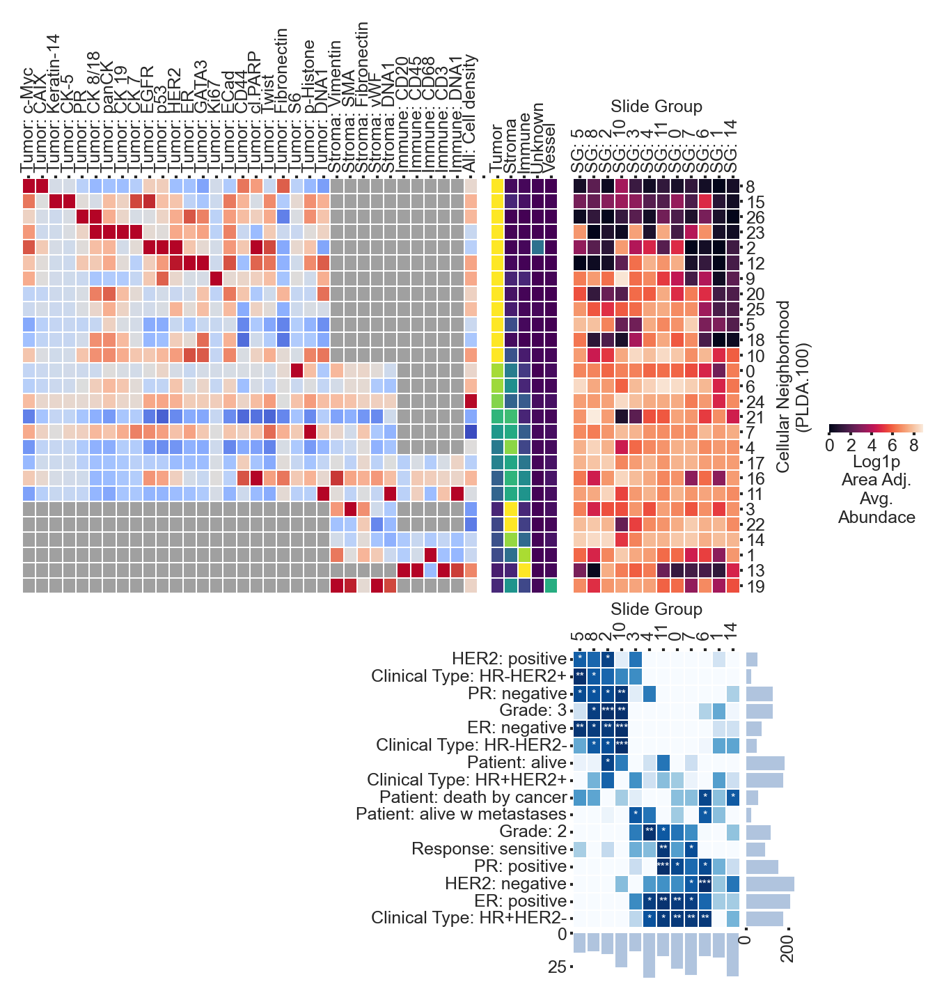

In [118]:
# CBIGL


big_l_figure = sns.clustermap(
    big_l_clustering_df.loc[sg_order].T.iloc[class_argsort],
    row_cluster=False,
    col_cluster=False,
    figsize=(6., 5.5),
    row_colors=full_class_colors_with_ct,
    col_colors=clinical_colors_with_cluster_color[list(clinical_colors_with_cluster_color.columns)],
    colors_ratio=(0.01525, 0.02),
    xticklabels=True,
    yticklabels=True,
    linewidth=0.01,
    cbar_pos=[.8, 0.36, 0.075, 0.0075],
    cbar_kws={'label': 'CN abundance', 'aspect': 10, 'orientation': 'horizontal'}
)

big_l_figure.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_heatmap.set_yticklabels(
    big_l_figure.ax_heatmap.get_yticklabels(), size=6,
)

xticks = big_l_figure.ax_heatmap.get_xticklabels()
big_l_figure.ax_heatmap.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_heatmap.set_xticklabels(
    xticks, size=6,
)
big_l_figure.ax_heatmap.xaxis.tick_top()

big_l_figure.ax_col_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_col_colors.set_xticks(
    [i + 0.5 for i in range(len(xticks))],
    labels=[tick.get_text().split(':')[1] for tick in xticks],
    size=6,
)
big_l_figure.ax_col_colors.xaxis.tick_top()

big_l_figure.ax_col_colors.set_xticklabels(
    big_l_figure.ax_col_colors.get_xticklabels(),
    size=6,
)

big_l_figure.ax_row_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_row_colors.set_xticklabels(
    [clean_up_big_l_clinical_tick(tick) for tick in big_l_figure.ax_row_colors.get_xticklabels()],
    size=6,
    #ha='right',
)

# big_l_figure.ax_row_colors.yaxis.set_tick_params(size=1, pad=1, rotation=0)
# big_l_figure.ax_row_colors.yaxis.tick_right()
# big_l_figure.ax_row_colors.set_yticks(
#     ticks=[i + 0.5 for i in range(len(big_l_figure.data2d.index))],
#     labels=[x for x in big_l_figure.data2d.index],
#     size=6,
# )

big_l_figure.ax_col_colors.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_col_colors.set_yticklabels(
    big_l_figure.ax_col_colors.get_yticklabels(), size=6,
)
big_l_figure.ax_row_colors.xaxis.tick_top()
big_l_figure.ax_col_colors.yaxis.tick_left()
big_l_figure.ax_heatmap.yaxis.tick_right()

ax_row_colors = big_l_figure.ax_row_colors
ax_col_colors = big_l_figure.ax_col_colors
row_box = ax_row_colors.get_position()
col_box = ax_col_colors.get_position()

box_heatmap = big_l_figure.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.min[1] - col_box.height -  0.05, col_box.width, col_box.height])
ax_row_colors.set_position([box_heatmap.min[0] - row_box.width - 0.012, row_box.y0, row_box.width, row_box.height])


big_l_figure.ax_col_dendrogram.set_visible(False)
big_l_figure.ax_row_dendrogram.set_visible(False)
#big_l_figure.ax_cbar.set_visible(False)
big_l_figure.fig.set_dpi(PLOTTING_DPI)
#big_l_figure.fig.set_size_inches((9, 6.5))

#big_l_figure.ax_cbar.outline.set_visible(False)
big_l_figure.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
big_l_figure.ax_cbar.set_xticks(
    [0, 2, 4, 6, 8],
    [0, 2, 4, 6, 8]
)
big_l_figure.ax_cbar.set_xlabel('Log1p\nArea Adj.\nAvg.\nAbundace', labelpad=0, size=6)

ordered_counts = [sg_counts.loc[roi].values[0] for roi in permuted_rois]
ordered_counts_cl = clinical_counts_for_big_l.values[::-1, 0]

bar_height = 0.04  # Adjust this to change the height of the barplot
bar_height_cl = 0.04
bar_ax = big_l_figure.fig.add_axes([
    col_box.x0, 
    ax_col_colors.get_position().min[1] - bar_height - 0.005,  # Position above col_colors
    col_box.width, 
    bar_height
])

bar_ax_cl = big_l_figure.fig.add_axes([
    col_box.x1 + 0.005, 
    ax_col_colors.get_position().max[1] - col_box.height,  # Position above col_colors
    bar_height_cl,
    col_box.height
])


# Create the barplot
x_positions = list(range(len(ordered_counts)))
bars_ = bar_ax.bar(x_positions, ordered_counts, width=0.75, 
                  color='lightsteelblue', edgecolor='lightsteelblue', linewidth=0.5)
bar_ax.invert_yaxis()
bar_ax.set_facecolor('white')

x_positions_cl = list(range(len(ordered_counts_cl)))
bars_cl = bar_ax_cl.barh(x_positions_cl, ordered_counts_cl, height=0.75, 
                  color='lightsteelblue', edgecolor='lightsteelblue', linewidth=0.5)
#bar_ax_cl.invert_xaxis()
bar_ax_cl.set_facecolor('white')


# Style the barplot
bar_ax.set_xlim(-0.5, len(ordered_counts) - 0.5)
bar_ax.set_xticks([])  # Remove x-axis ticks since they're shown below
bar_ax.spines['bottom'].set_visible(False)
bar_ax.spines['top'].set_visible(False)
bar_ax.spines['right'].set_visible(False)
bar_ax.spines['left'].set_linewidth(0.0)

# Style y-axis
bar_ax.tick_params(axis='y', labelsize=6, size=1, pad=1)
#bar_ax.set_ylabel('Counts', size=6, labelpad=2)
#bar_ax.yaxis.tick_right()

bar_ax_cl.set_ylim(-0.5, len(ordered_counts_cl) - 0.5)
bar_ax_cl.set_yticks([])  # Remove x-axis ticks since they're shown below
bar_ax_cl.spines['bottom'].set_visible(False)
bar_ax_cl.spines['top'].set_visible(False)
bar_ax_cl.spines['right'].set_visible(False)
bar_ax_cl.spines['left'].set_linewidth(0.0)

# Style y-axis
bar_ax_cl.tick_params(axis='x', labelsize=6, size=1, pad=1., rotation=90)


annot_shape = clinical_cm.data2d.values.shape
permuted_rois = list(big_l_figure.data2d.columns)
permuted_features = list(clinical_cm.data2d.index)

print(permuted_rois, permuted_features)

for i in range(annot_shape[1]):
    for j in range(annot_shape[0]):
        current_text = clinical_cm.data2d.T.loc[permuted_rois[i]].loc[permuted_features[j]]
        current_text = round(current_text, 2)
        stars = ''
        if current_text < 0.2:
            stars += '*'
        if current_text < 0.05:
            stars += '*'
        if current_text < 0.01:
            stars += '*'
        big_l_figure.ax_col_colors.text(
            i + 0.5, j + 0.5, 
            stars, 
            horizontalalignment='center', 
            verticalalignment='center',
            c='w', size=4)
        
big_l_figure.ax_col_colors.set_xlabel('Slide Group', labelpad=2.2)
big_l_figure.ax_col_colors.xaxis.set_label_position('top')

big_l_figure.ax_heatmap.set_xlabel('Slide Group', labelpad=2.2)
big_l_figure.ax_heatmap.xaxis.set_label_position('top')

array([2.35, 2.35])

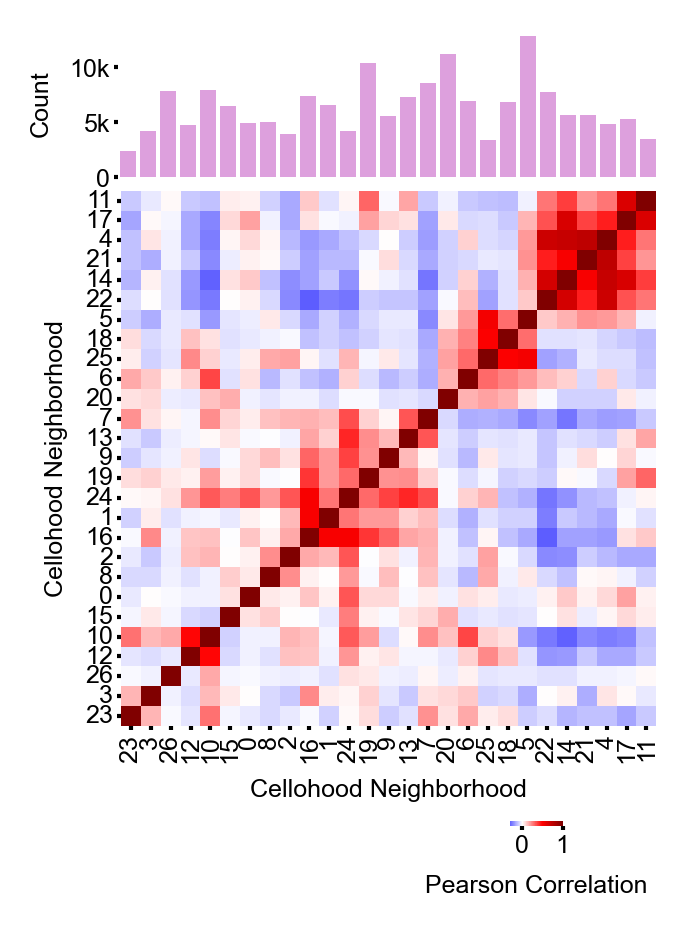

In [119]:
corr_df = sample_count_basel[list(range(JACKSON_NB_OF_CLUSTERS))].corr()
corr_df.index.name = 'Cellohood Neighborhood'
corr_df.columns.name = 'Cellohood Neighborhood'

mpl.rcParams.update(mpl.rcParamsDefault)

sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
plt.rcParams['legend.title_fontsize'] = 6
plt.rcParams['legend.fontsize'] = 6
mpl.rcParams['font.family'] = 'Arial'


corr_cmap = sns.clustermap(
    corr_df,
    center=0,
    cmap='seismic',
    xticklabels=True,
    yticklabels=True,
    #annot=True,
    #fmt='.2f',
    #annot_kws={'size': 3},
    cbar_pos=[0.75, -0.1, 0.075, 0.0075],
    cbar_kws={'label': 'Pearson Correlation', 'orientation': 'horizontal'}
)

corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)
corr_cmap.ax_heatmap.yaxis.set_label_position("left")
corr_cmap.ax_heatmap.yaxis.tick_left()

#corr_cmap.ax_cbar.set_visible(False)

barplot_ax = corr_cmap.fig.add_axes([0.195, 0.82, .765, .21], sharex=corr_cmap.ax_heatmap)
barplot_ax.bar(
    corr_cmap.data2d.columns + 0.5,
    cluster_counts[corr_cmap.data2d.columns],
    align='center',
    width=0.8,
    color='plum',
)
#barplot_ax.invert_yaxis()
barplot_ax.invert_xaxis()
#barplot_ax.spines['left'].set_visible(False)
barplot_ax.spines['top'].set_visible(False)
barplot_ax.spines['right'].set_visible(False)
barplot_ax.spines['bottom'].set_visible(False)
barplot_ax.xaxis.set_visible(False)
barplot_ax.set_ylabel('Count', size=6)
barplot_ax.yaxis.set_tick_params(size=1, pad=1)
#barplot_ax.yaxis.tick_right()
#barplot_ax.yaxis.set_label_position("right")
barplot_ax.set_yticks(
    [0, 25000, 50000], 
    ['0', '5k', '10k'],
    size=6, rotation=0,
)
barplot_ax.spines['left'].set_linewidth(0.)

corr_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)

corr_cmap.ax_heatmap.set_yticklabels(
    corr_cmap.ax_heatmap.get_yticklabels(), size=6)
corr_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
corr_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
corr_cmap.ax_heatmap.set_xticklabels(
    corr_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

corr_cmap.fig.set_dpi(PLOTTING_DPI)
corr_cmap.fig.set_size_inches((2.35, 2.35))
plt.gcf().get_size_inches()

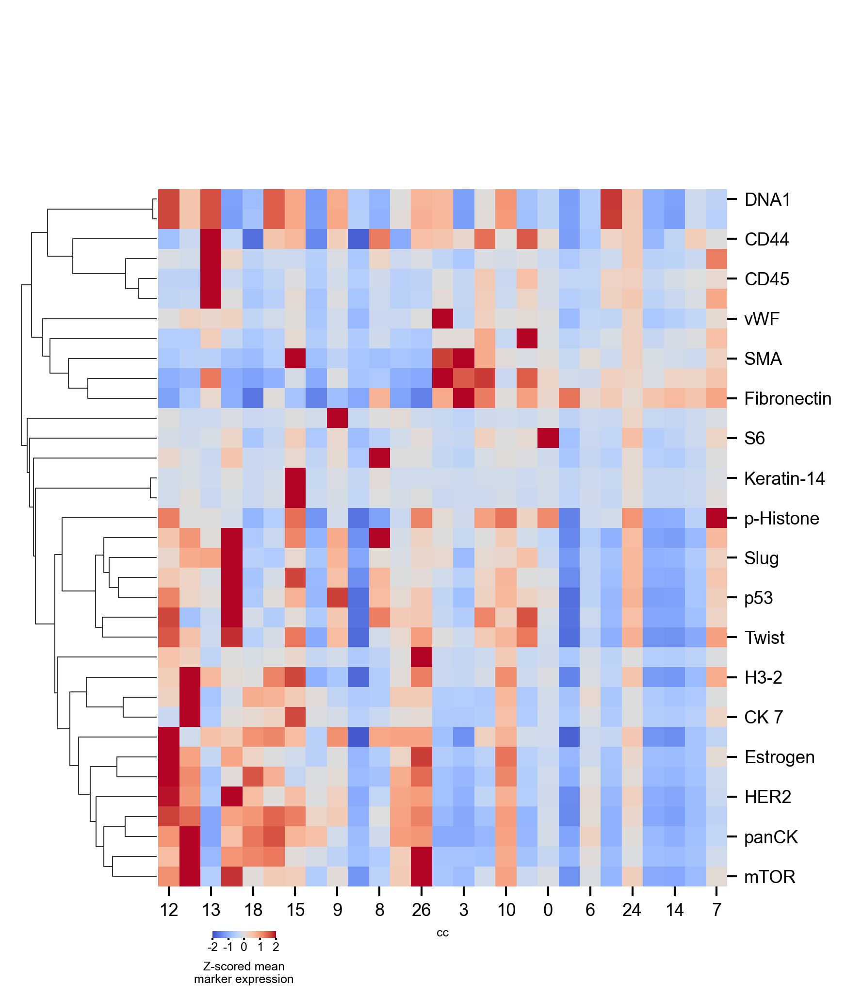

In [120]:
mcmap = sns.clustermap(
    all_markers_distribution.T[celltype_clustermap.data2d.columns], 
    center=0, 
    cmap='coolwarm', 
    vmin=-2, 
    vmax=2,
    col_cluster=False,
    figsize=(5.8, 6.5),
    cbar_pos=[.25, 0.01, 0.075, 0.0075],
    cbar_kws={'label': 'Z-scored mean\nmarker expression', 'aspect': 10, 'orientation': 'horizontal'}
)
mcmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
mcmap.ax_cbar.set_xticks(
    [-2, -1, 0, 1, 2],
    [-2, -1, 0, 1, 2],
)
mcmap.fig.set_dpi(PLOTTING_DPI)

## Patients horizontal

In [121]:
clean_ticks = [
    tick if tick != '12' else ''
    for tick in ticks
]

clean_ticks = [
    tick if tick != '-' else '|'
    for tick in clean_ticks
]

/tmp/ipykernel_4104654/3890836575.py:201: UserWarning: Tight layout not applied. tight_layout cannot make axes height small enough to accommodate all axes decorations.
  patient_clustermap.fig.tight_layout()


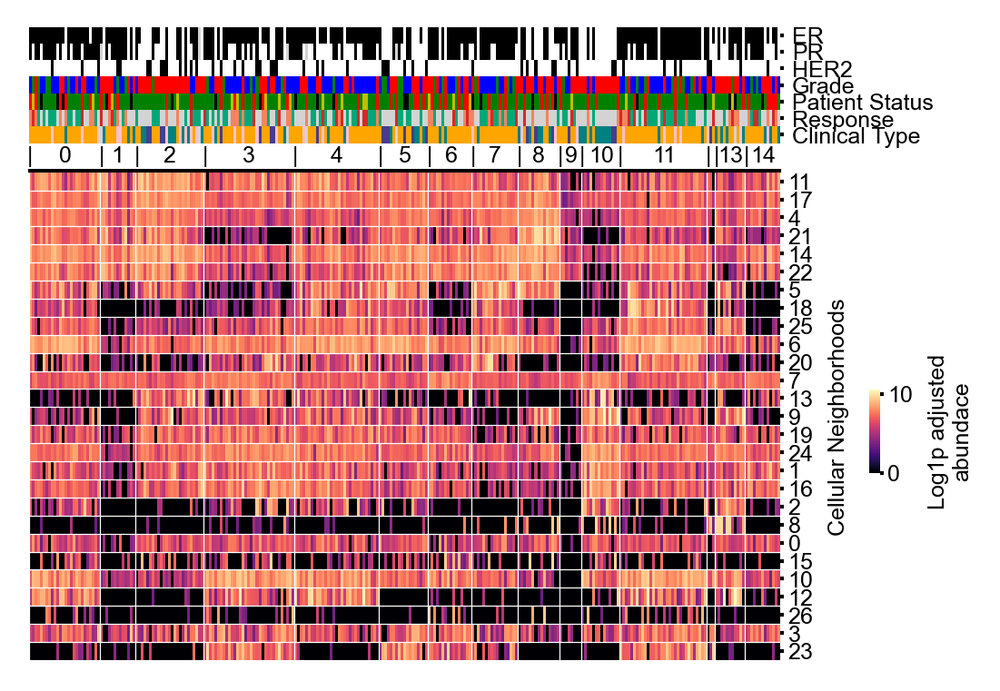

In [122]:
from matplotlib import cm as mcm
import matplotlib as mpl

cluster_norm = mpl.colors.Normalize(vmin=0, vmax=JACKSON_ROI_CLUSTERS)
cluster_cmap = plt.get_cmap('nipy_spectral')

cluster_sm = mcm.ScalarMappable(norm=cluster_norm, cmap=cluster_cmap)

vectors_df = pandas.DataFrame(
    vectors.T,
    index=patient_to_clinical_colors_df.index,
)
vectors_df.index.name = ROI_PLOT_NAME
vectors_df.columns.name = CC_PLOT_NAME


patient_to_clinical_colors_df['Cluster'] = [cluster_sm.to_rgba(x) for x in clusters]

patient_clustermap = sns.clustermap( 
    vectors_df.iloc[clusters.argsort()].T.iloc[corr_cmap.data2d.columns],
    col_cluster=False,
    row_cluster=False,
    cbar_pos=[.96, 0.3, 0.01, .1],
    cbar_kws={'label': 'Log1p adjusted\nabundace'},
    xticklabels=clean_ticks,
    col_colors=patient_to_clinical_colors_df[
        [col for col in patient_to_clinical_colors_df.columns if col != 'Cluster']
    ],
    figsize=(8, 6),
    linewidths=(0.000, 0.01),
    colors_ratio=0.022,
    yticklabels=1,
    cmap='magma',
)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(rotation=0)

patient_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
patient_clustermap.ax_row_dendrogram.set_visible(False)
patient_clustermap.ax_col_dendrogram.set_visible(False)

patient_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=.5)
patient_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
patient_clustermap.ax_heatmap.xaxis.tick_top()
patient_clustermap.ax_heatmap.set_xticklabels(
    patient_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=0
)
patient_clustermap.ax_heatmap.set_yticklabels(
    patient_clustermap.ax_heatmap.get_yticklabels(), size=6, rotation=0
)


#patient_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
#patient_clustermap.ax_row_colors.set_xticklabels(
#    patient_clustermap.ax_row_colors.get_xticklabels(), size=6,
#)
#patient_clustermap.ax_row_colors.xaxis.tick_top()
#patient_clustermap.ax_heatmap.yaxis.tick_left()

patient_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=2, rotation=0)
patient_clustermap.ax_col_colors.set_yticklabels(
    patient_clustermap.ax_col_colors.get_yticklabels(), size=6,
)
#patient_clustermap.ax_col_colors.xaxis.set_tick_params(size=1, pad=1, rotation=0)
# patient_clustermap.ax_col_colors.set_xticks(
#     patient_clustermap.ax_heatmap.get_xticks(), 
#     labels=patient_clustermap.ax_heatmap.get_xticklabels(),
#     size=6,
#     rotation=90,
# )
# patient_clustermap.ax_col_colors.set_xlabel('Cellohood Neighborhood Cluster')
patient_clustermap.ax_heatmap.set_xlabel('')

#patient_clustermap.ax_cbar.set_visible(False)

#patient_clustermap.ax_col_colors.set_yticklabels(
#    patient_clustermap.ax_col_colors.get_yticklabels(), size=6
#)
#patient_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)
#patient_clustermap.ax_heatmap.yaxis.set_label_position('left')

HORIZONTAL_START = 0.09
LEGEND_START = -0.1

# pos_neg_handles = [Patch(facecolor=er_color[name], edgecolor='black') for name in er_color]
# pos_neg_legend = plt.legend(
#     pos_neg_handles, 
#     ['Yes', 'No', 'Unk'], 
#     title='ER, PR, HER2',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .95), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='left',
#     markerfirst=True,
#     labelspacing=0.1,
# )
# plt.gcf().add_artist(pos_neg_legend)


# grade_handles = [Patch(facecolor=grade_color[name], edgecolor='black') for name in grade_color]
# grade_legend = plt.legend(
#     grade_handles, 
#     [1, 2, 3, 'Unk'], 
#     title='Grade',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .8), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='left',
#     markerfirst=True,
#     labelspacing=0.1,
# )
# plt.gcf().add_artist(grade_legend)

# ps_handles = [
#     Patch(facecolor=ps_color[name], edgecolor='black')
#     for name in ['alive', 'alive w metastases', 'death by primary disease', 'death']
# ]
# ps_legend = plt.legend(
#     ps_handles, 
#     ['alive', 'alive w.metastases', 'death (primary disease)', 'death (other)'], 
#     title='Patient Status',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .65), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='left',
#     markerfirst=True,
#     labelspacing=0.1,
# )
# plt.gcf().add_artist(ps_legend)

# response_handles = [Patch(facecolor=response_color[name], edgecolor='black') for name in response_color]
# response_legend = plt.legend(
#     response_handles, 
#     ['Refractory', 'Resistant', 'Sensitive', 'Unk'], 
#     title='Response',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .5), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='left',
#     markerfirst=True,
#     labelspacing=0.1,
# )
# plt.gcf().add_artist(grade_legend)

# clinical_handles = [Patch(facecolor=clinical_type_color[name], edgecolor='black') for name in clinical_type_color]
# clinical_legend = plt.legend(
#     clinical_handles[:4], 
#     ['HR+HER2-', 'HR+HER2+', 'HR-HER2+', 'HR-HER2-'], 
#     title='Clinical Type',
#     bbox_to_anchor=(LEGEND_SPACING, LEGEND_START + .35), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='center',
#     markerfirst=True,
#     labelspacing=0.1,
#     ncol=2,
# )
# plt.gcf().add_artist(clinical_legend)

#ax_row_colors = patient_clustermap.ax_row_colors
ax_col_colors = patient_clustermap.ax_col_colors
row_box = ax_row_colors.get_position()
col_box = ax_col_colors.get_position()

box_heatmap = patient_clustermap.ax_heatmap.get_position()
#ax_row_colors.set_position([box_heatmap.max[0], row_box.y0, box.width*1.5, row_box.height])
ax_col_colors.set_position([col_box.x0, col_box.y0 + 0.032, col_box.width, col_box.height])


"""
cluster_handles = [
    Patch(facecolor=cluster_sm.to_rgba(x), edgecolor='black')
    for x in range(JACKSON_ROI_CLUSTERS)
]
cluster_legend = plt.legend(
    cluster_handles, 
    [f'{ROI_PLOT_NAME}: {ind_}' for ind_ in range(JACKSON_ROI_CLUSTERS)], 
    title=f'{ROI_PLOT_NAME} Cluster',
    bbox_to_anchor=(LEGEND_SPACING, .4125), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(clinical_legend)
"""

for i in range(1, vectors_df.shape[1]):
    patient_clustermap.ax_heatmap.hlines(i, 0, vectors_df.shape[0], linewidth=0.3, color="white")
    
bars = [ind_ for ind_, tick in enumerate(clean_ticks) if tick == '|']

for bar in bars:
    patient_clustermap.ax_heatmap.vlines(bar , 0, vectors_df.shape[1], linewidth=0.3, color="white")
    
patient_clustermap.fig.tight_layout()
patient_clustermap.fig.set_dpi(PLOTTING_DPI)
patient_clustermap.fig.set_size_inches((4, 3.07))

In [123]:
cell_df['class'] = cell_df['cell_type'].apply(lambda x: celltype_to_class[x]) 
cell_df['class_color'] = cell_df['class'].apply(lambda x: class_to_color[x])

In [124]:
ROI_CLUSTER = 'SG: 2'

roi_samples = list(
    roi_cluster_with_clinical[roi_cluster_with_clinical[ROI_CLUSTER] == 1]['sample']
)

In [125]:
ROI_SAMPLE = roi_samples[5]

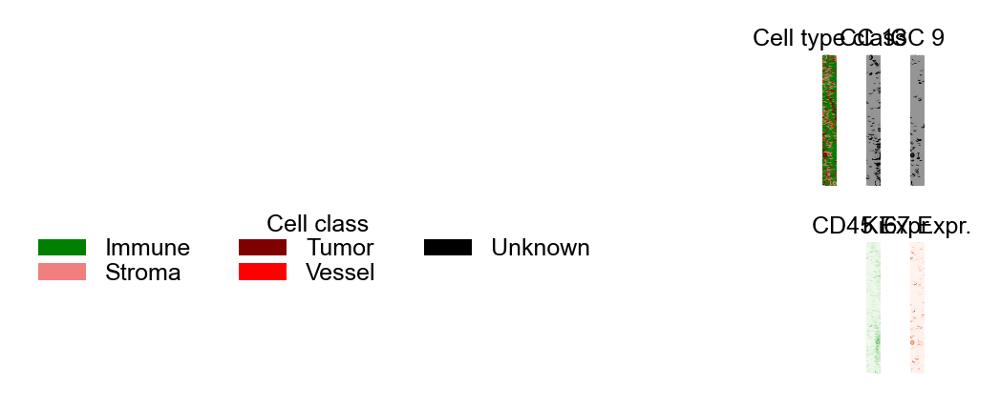

In [126]:
image_df = cell_df[cell_df['image'] == ROI_SAMPLE]

plt.figure(figsize=(2, 1.4), dpi=300)

MARKER_SIZE = 0.03

plt.subplot(2, 3, 1)
plt.scatter(
    image_df['Location_Center_X'],
    image_df['Location_Center_Y'],
    c=image_df['class_color'],
    #alpha=0.5,
    s=MARKER_SIZE,
)
plt.title('Cell type class', pad=0)
plt.axis('off')
plt.subplot(2, 3, 2)
plt.scatter(
    image_df['Location_Center_X'],
    image_df['Location_Center_Y'],
    c=0.5 + 0.5 * (image_df['cc'] == 13),
    vmin=0,
    #alpha=0.5,
    cmap='Greys',
    s=MARKER_SIZE,
)
plt.axis('off')
plt.title('CC 13', pad=0)
plt.subplot(2, 3, 3)
plt.scatter(
    image_df['Location_Center_X'],
    image_df['Location_Center_Y'],
    c=0.5 + 0.5 * (image_df['cc'] == 9),
    cmap='Greys',
    vmin=0,
    #alpha=0.5,
    s=MARKER_SIZE,
)
plt.title('CC 9', pad=0)
plt.axis('off')
plt.subplot(2, 3, 6)
plt.scatter(
    image_df['Location_Center_X'],
    image_df['Location_Center_Y'],
    c=image_df['1441101Er168Di Ki67'],
    cmap='Reds',
    s=MARKER_SIZE,
)
plt.title('Ki67 Expr.', pad=0)
plt.axis('off')
plt.subplot(2, 3, 5)
plt.scatter(
    image_df['Location_Center_X'],
    image_df['Location_Center_Y'],
    c=image_df['71790Dy162Di CD45'],
    cmap='Greens',
    s=MARKER_SIZE,
)
plt.title('CD45 Expr.', fontsize=6, pad=0)
plt.axis('off')
plt.subplot(2, 3, 4)

handles = [Patch(facecolor=class_to_color[name]) for name in class_to_color]
plt.legend(
    handles, 
    class_to_color, 
    title=' Cell class',
    bbox_to_anchor=(0.41, 0.525), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    labelspacing=0.1,
    ncols=3,
    fontsize=6,
)
plt.axis('off')
plt.subplots_adjust(wspace=-0.0, hspace=-0.00)

plt.tight_layout()



In [127]:
import numpy as np


def compute_triangle_areas(triangulation):
    """
    Compute areas of all triangles in a matplotlib triangulation
    
    Args:
        triangulation: matplotlib.tri.Triangulation object
        
    Returns:
        numpy array with areas of each triangle
    """
    # Get coordinates and triangles
    x = triangulation.x
    y = triangulation.y
    triangles = triangulation.triangles
    
    # Get vertices for each triangle
    v1 = np.column_stack((x[triangles[:,0]], y[triangles[:,0]]))
    v2 = np.column_stack((x[triangles[:,1]], y[triangles[:,1]]))
    v3 = np.column_stack((x[triangles[:,2]], y[triangles[:,2]]))
    
    # Compute areas using cross product
    # Area = 1/2 * |cross product|
    areas = 0.5 * np.abs(
        (v2[:,0] - v1[:,0]) * (v3[:,1] - v1[:,1]) -
        (v3[:,0] - v1[:,0]) * (v2[:,1] - v1[:,1])
    )
    
    return areas


BaselTMA_SP42_121_X11Y8
(2312, 80)


/tmp/ipykernel_4104654/3251061713.py:195: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


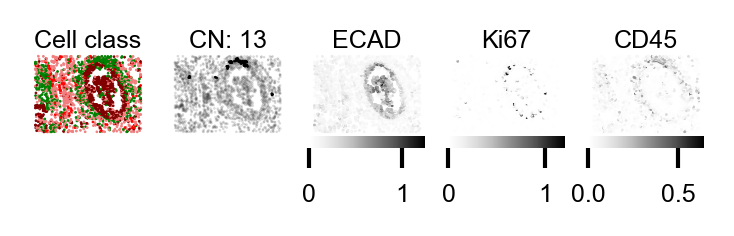

BaselTMA_SP41_280_X9Y5
(2909, 80)


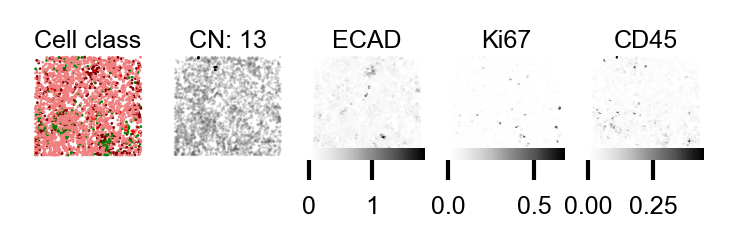

BaselTMA_SP41_69_X5Y3
(2147, 80)


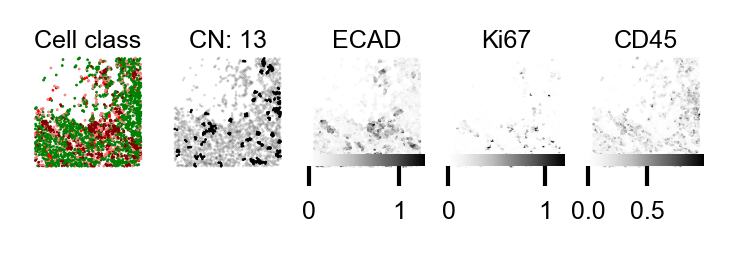

BaselTMA_SP42_70_X5Y3
(3097, 80)


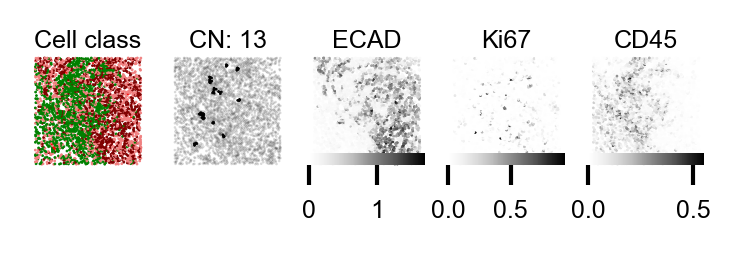

BaselTMA_SP42_82_X2Y9
(5024, 80)


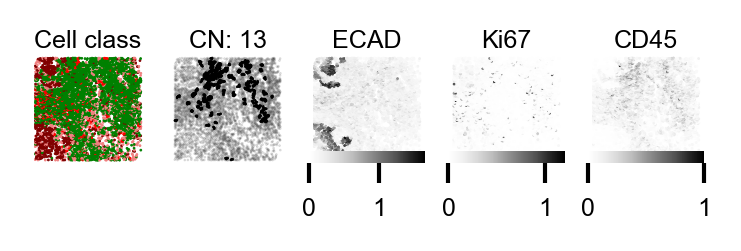

BaselTMA_SP41_191_X15Y7
(4544, 80)


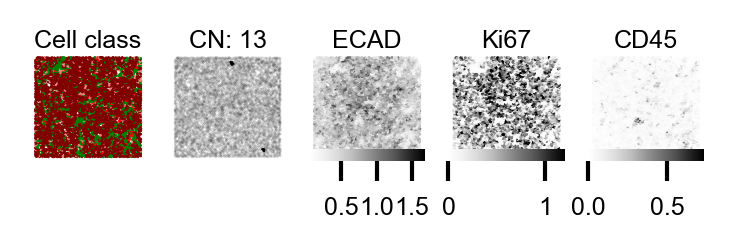

BaselTMA_SP42_145_X1Y4
(3361, 80)


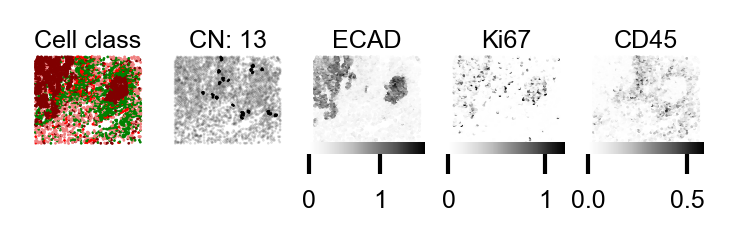

BaselTMA_SP43_21_X3Y5
(1743, 80)


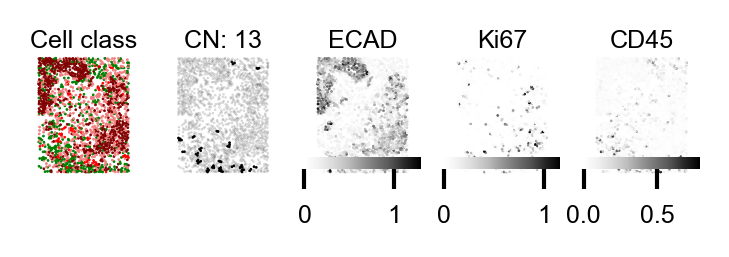

BaselTMA_SP42_155_X4Y9
(4585, 80)


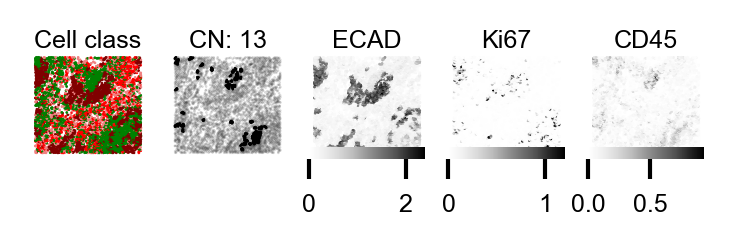

BaselTMA_SP42_89_X4Y6
(2730, 80)


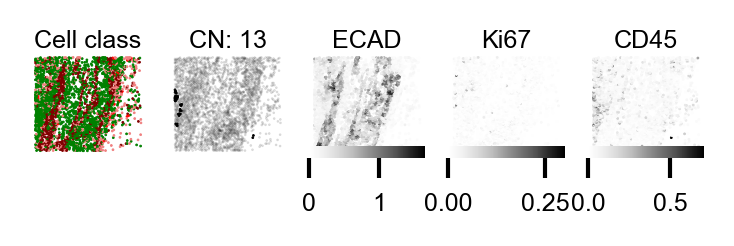

BaselTMA_SP42_185_X7Y5
(2427, 80)


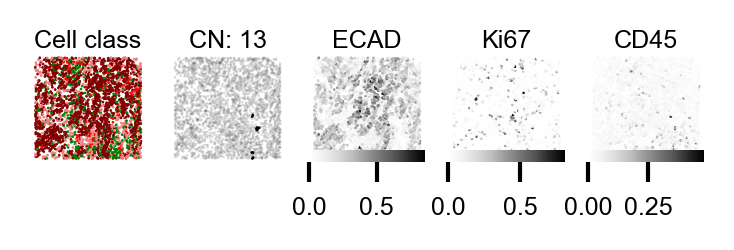

BaselTMA_SP42_273_X6Y7
(2872, 80)


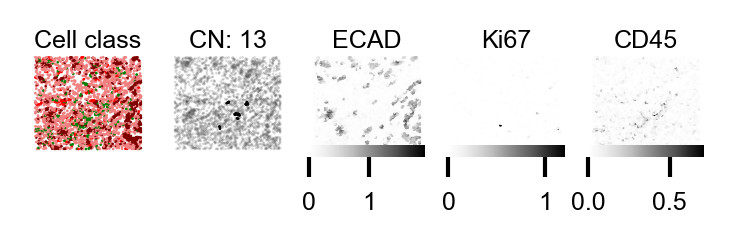

BaselTMA_SP42_99_X5Y7
(1923, 80)


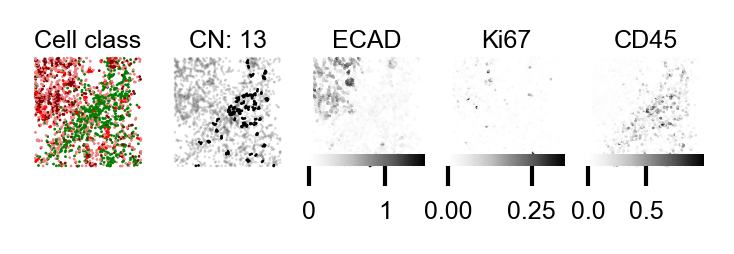

BaselTMA_SP42_163_X1Y9
(2690, 80)


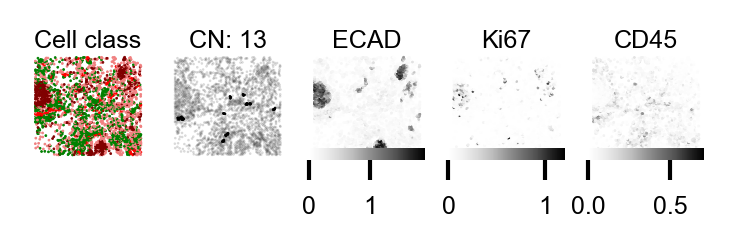

BaselTMA_SP41_177_X16Y5
(2723, 80)


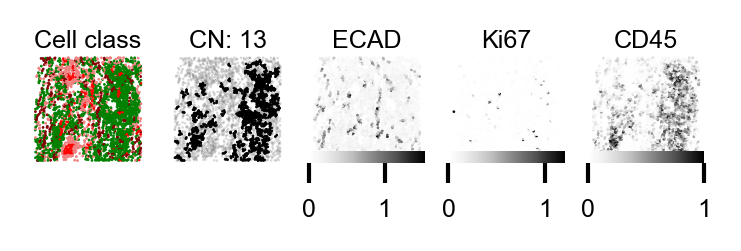

BaselTMA_SP43_271_X11Y8
(2256, 80)


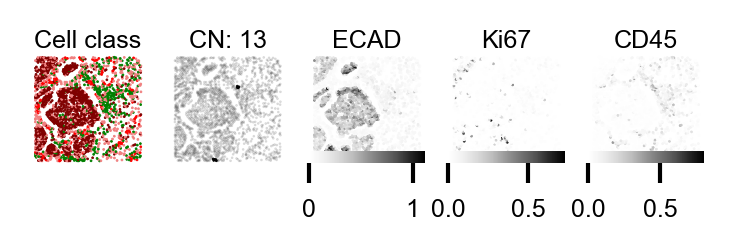

BaselTMA_SP42_184_X6Y8
(4380, 80)


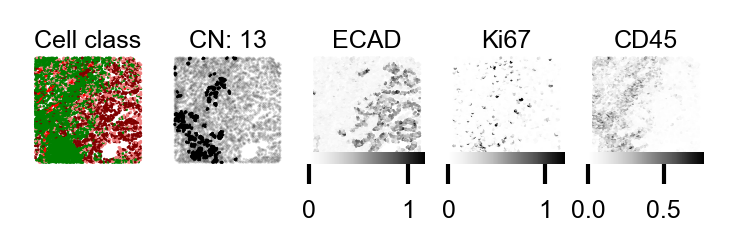

BaselTMA_SP43_90_X7Y6
(3194, 80)


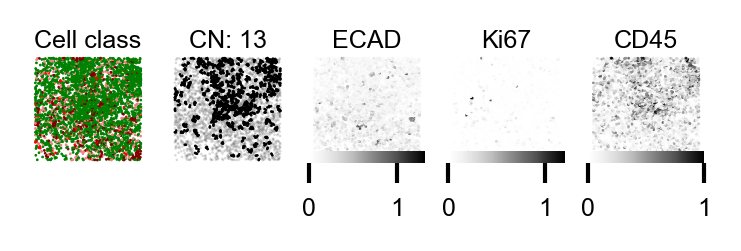

BaselTMA_SP42_148_X5Y6
(2821, 80)


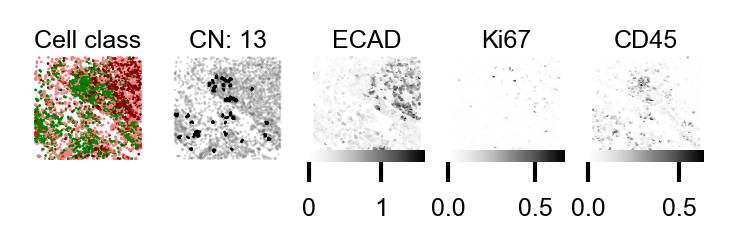

BaselTMA_SP41_224_X3Y7
(1593, 80)


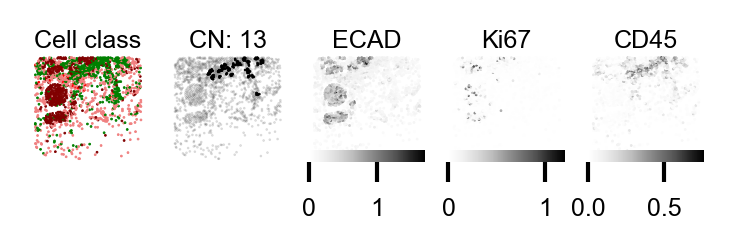

BaselTMA_SP42_275_X5Y4
(1811, 80)


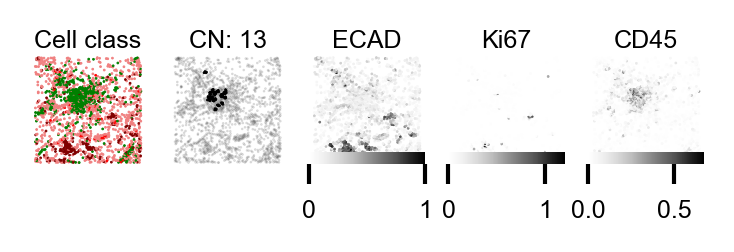

BaselTMA_SP41_212_X1Y9
(2203, 80)


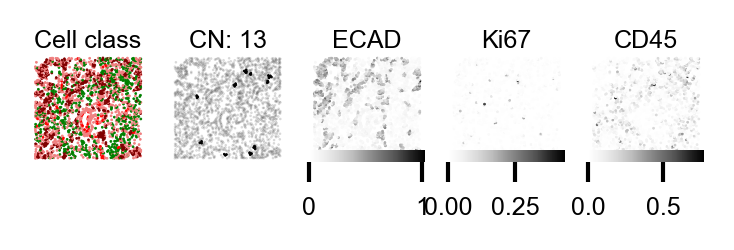

BaselTMA_SP42_46_X10Y7
(2901, 80)


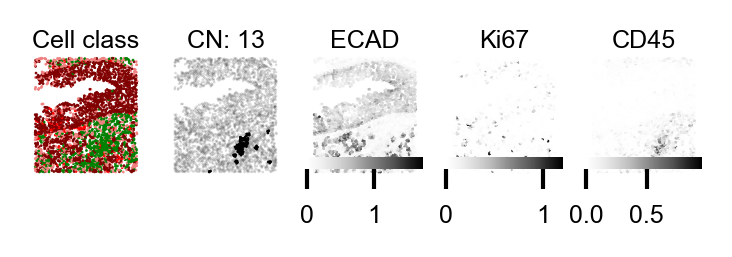

BaselTMA_SP42_96_X9Y3
(1204, 80)


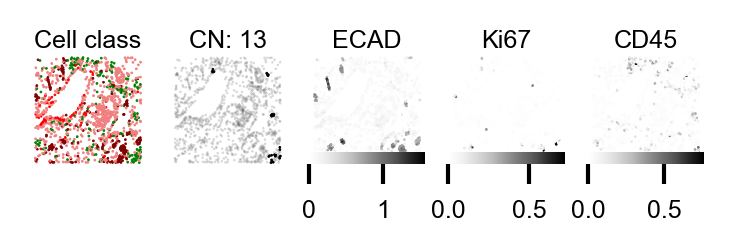

BaselTMA_SP41_33_X14Y6
(3556, 80)


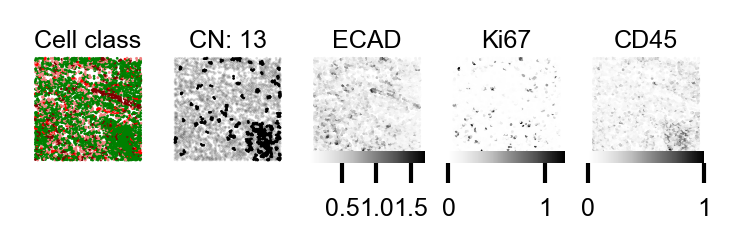

In [128]:
import matplotlib


CLUSTER_TO_ANALYZE = 2
cluster_images = list(set(sample_count_basel[clusters == CLUSTER_TO_ANALYZE].core))


from matplotlib import tri
from mpl_toolkits.axes_grid1 import make_axes_locatable

tumor_percentage_argsort = (-class_percentages['Tumor']).argsort().argsort()
MARKER_SIZE = 0.2

for image in cluster_images:
    # Create figure and gridspec for better control of subplot sizes
    fig = plt.figure(figsize=(3.5, 0.6), dpi=300)
    gs = plt.GridSpec(2, 6, height_ratios=[1, 0.1], hspace=0.01)
    
    # Create main plot axes
    axs = [plt.subplot(gs[0, i]) for i in range(1, 6)]
    print(image)
    image_df = cell_df[cell_df.core == image]
    print(image_df.shape)
    #image_sd_df = sd_df[cell_df.image == image]
    
    # Compute triangulation
    tr = tri.Triangulation(image_df['Location_Center_X'], image_df['Location_Center_Y'])
    areas = compute_triangle_areas(tr)
    tr.set_mask(areas > 200)
    
    # Plot 1: Cell types
    axs[0].set_title('Cell class', size=6, pad=0.1)
    scatter0 = axs[0].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        #alpha=0.5,
        c=image_df['class'].apply(lambda x: class_to_color[x]),
    )
    axs[0].set_aspect(1)
    axs[0].axis('off')
    axs[0].set_ylabel(f'{ROI_CLUSTER_NAME}: {CLUSTER_TO_ANALYZE}')
    # Create legend elements
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=color, label=cell_type, 
                                 markersize=4)
                      for cell_type, color in tau.PANEL_1_CELL_TYPE_TO_COLOR.items()]
    
    # Add legend with small font and two columns
#    legend_ax = plt.subplot(gs[0, 0])
#     legend = legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           bbox_to_anchor=(0.05, -0.1),
#                           loc='center left',
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     legend_ax.axis('off')
    
#     # Remove legend frame
#     legend.get_frame().set_linewidth(0.0)
    
    axs[0].set_aspect(1)
    axs[0].axis('off')
    
    # Plot 2: Cellohood
    axs[1].set_title('CN: 13', size=6, pad=0.1)
    scatter1 = axs[1].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        alpha=0.1 + 0.9 * (image_df['cc'] == 13),
        c='black',
        s=MARKER_SIZE,
        #cmap=custom_cmap,
        linewidths=MARKER_SIZE,
#         vmin=0,
#         vmax=6,
    )
    axs[1].axis('off')
    axs[1].set_aspect(1)
    
    #cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=6)
    #cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap=custom_cmap)
    

#     legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
#                                  markerfacecolor=cc_sm.to_rgba(i), label=f'CC:{i}', 
#                                  markersize=4)
#                      for i in range(7)]
#    cc_legend_ax = plt.subplot(gs[1, 2])
#     cc_legend = cc_legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           #bbox_to_anchor=(0.05, 0.1),
#                           #loc='upper center',
#                           bbox_to_anchor=(0.88, 3),
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     cc_legend.get_frame().set_linewidth(0.0)
#     cc_legend_ax.axis('off')
    
    # Plot 3: ECAD Expression
    axs[2].set_title('ECAD', size=6, pad=0.1)
    ind_ = JACKSON_MARKERS[(JACKSON_MARKERS_CLEAN.index('ECad'))]
    im1 = axs[2].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        c=image_df[ind_],
        cmap='Greys',
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[2].axis('off')
    axs[2].set_aspect(1)
    
    # Plot 4: Ki67 Expression
    axs[3].set_title('Ki67', size=6, pad=0.1)
    ind_ = JACKSON_MARKERS[(JACKSON_MARKERS_CLEAN.index('Ki67'))]
    im2 = axs[3].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        c=numpy.clip(image_df[ind_], 0, 1.2),
        cmap='Greys',
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[3].axis('off')
    axs[3].set_aspect(1)
    
    # Plot 5: CD3 Expression
    axs[4].set_title('CD45', size=6, pad=0.1)
    ind_ = JACKSON_MARKERS[(JACKSON_MARKERS_CLEAN.index('CD45'))]
    im3 = axs[4].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        c=numpy.clip(image_df[ind_], 0, 1.),
        cmap='Greys',
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[4].axis('off')
    axs[4].set_aspect(1)
    
    
    # Add colorbars in separate row
    # Only add for plots that need them (2-5)
    for i, im in enumerate([im1, im2, im3]):
        cax = plt.subplot(gs[1, i+3])
        cbar = plt.colorbar(
            im, 
            cax=cax, 
            orientation='horizontal', 
            aspect=40, 
            shrink=0.9, 
            pad=0.01, 
            anchor=(1.1, 0),
        )
        cbar.ax.tick_params(labelsize=6)
        cbar.outline.set_visible(False)
        EPS = 0.12
        cbar_pos = cbar.ax.get_position()
        new_box = matplotlib.transforms.Bbox([[cbar_pos.x0, cbar_pos.y0 + EPS], [cbar_pos.x1, cbar_pos.y1 + EPS]])
        cbar.ax.set_position(new_box)
    
    # Make sure all plots have same limits
    # Get the overall limits from all scatter plots and images
#     xlims = []
#     ylims = []
    
#     # Get limits from scatter plots
#     xlims.extend([axs[0].get_xlim(), axs[1].get_xlim()])
#     ylims.extend([axs[0].get_ylim(), axs[1].get_ylim()])
    
#     # Get limits from images
#     for i in range(1, 6):
#         xlims.append([0, img_array.shape[2]])
#         ylims.append([0, img_array.shape[1]])
    
#     # Find the overall limits
#     xmin = min([x[0] for x in xlims])
#     xmax = max([x[1] for x in xlims])
#     ymin = min([y[0] for y in ylims])
#     ymax = max([y[1] for y in ylims])
    
#     # Apply the same limits to all plots
#     for ax in axs:
#         ax.set_xlim(xmin, xmax)
#         ax.set_ylim(ymin, ymax)
    
    plt.tight_layout()

    plt.show()

BaselTMA_SP43_131_X13Y4
(1633, 80)


/tmp/ipykernel_4104654/2588206899.py:195: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


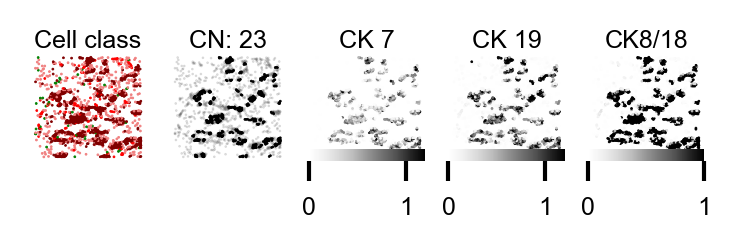

BaselTMA_SP43_3_X13Y6
(1563, 80)


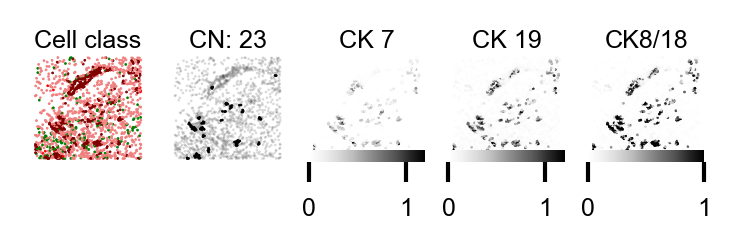

BaselTMA_SP41_52_X9Y3
(2892, 80)


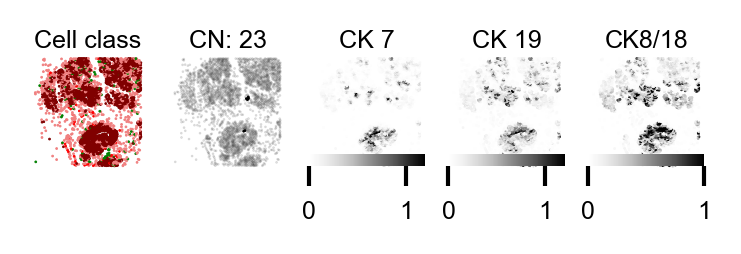

BaselTMA_SP41_92_X12Y7
(4533, 80)


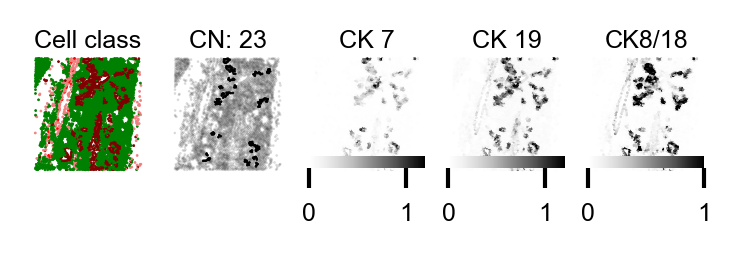

BaselTMA_SP41_159_X12Y4
(2515, 80)


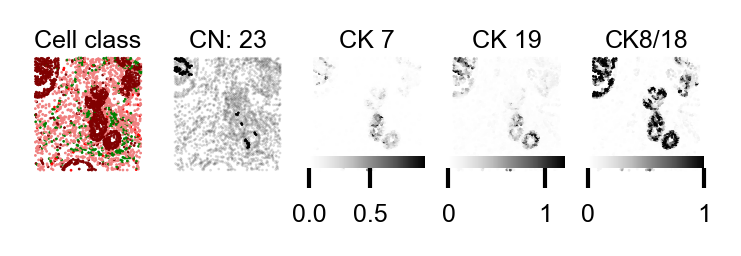

BaselTMA_SP41_57_X8Y6
(1248, 80)


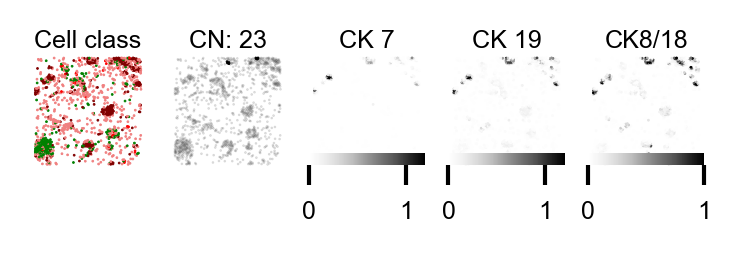

BaselTMA_SP42_236_X11Y7
(2716, 80)


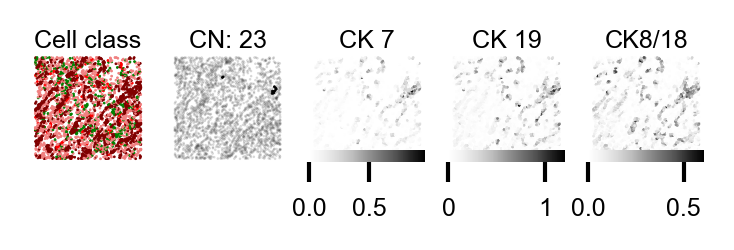

BaselTMA_SP43_281_X8Y7
(2198, 80)


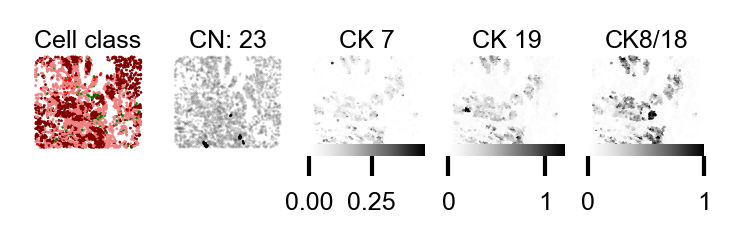

BaselTMA_SP42_188_X10Y5
(1617, 80)


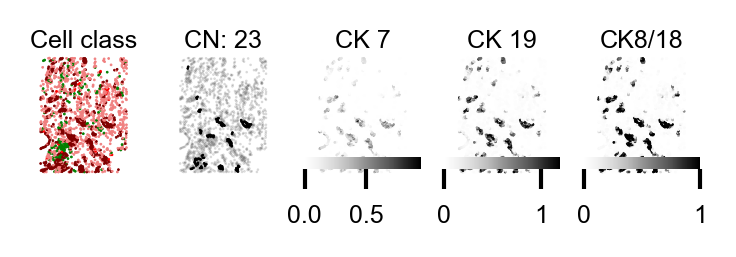

BaselTMA_SP43_197_X4Y9
(825, 80)


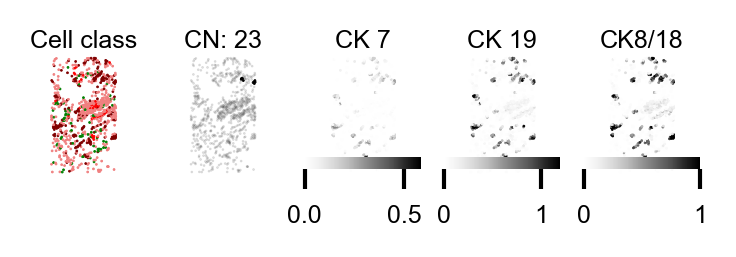

BaselTMA_SP43_207_X1Y6
(3131, 80)


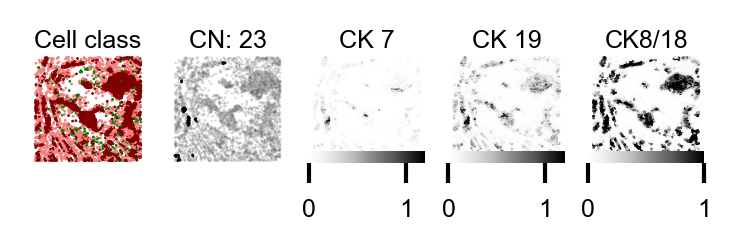

BaselTMA_SP43_118_X13Y5
(3309, 80)


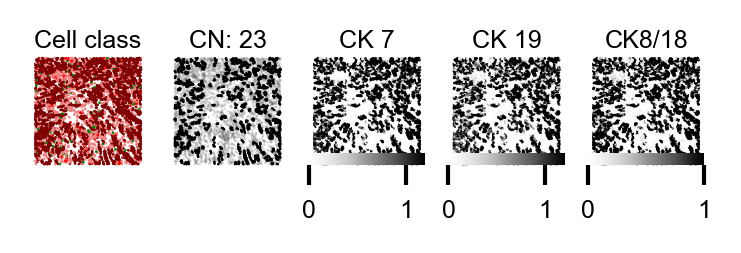

BaselTMA_SP43_4_X15Y3
(3076, 80)


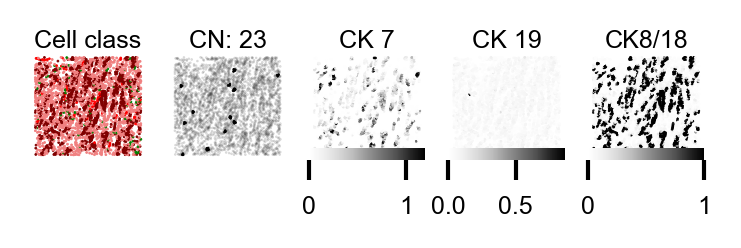

BaselTMA_SP43_119_X9Y8
(1583, 80)


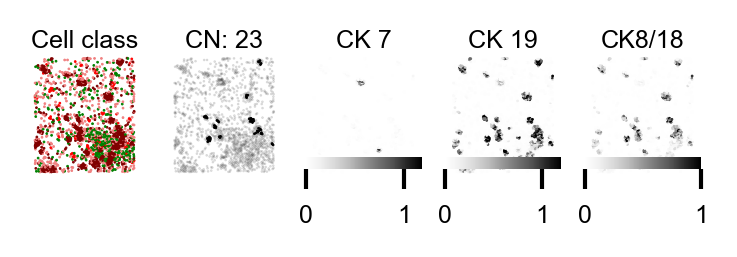

BaselTMA_SP43_248_X8Y8
(798, 80)


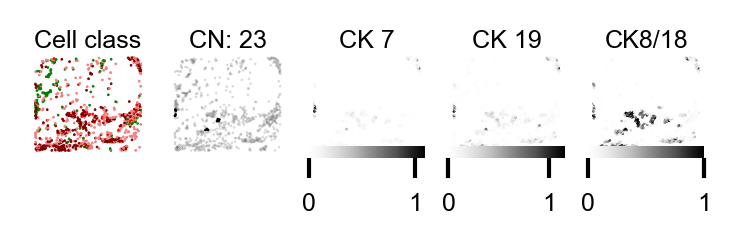

BaselTMA_SP43_97_X16Y6
(3648, 80)


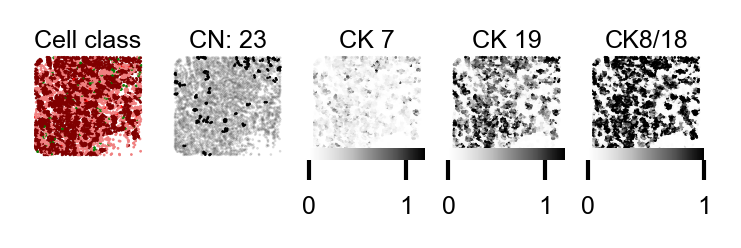

In [129]:
import matplotlib


CLUSTER_TO_ANALYZE = 6
cluster_images = list(set(sample_count_basel[clusters == CLUSTER_TO_ANALYZE].core))


from matplotlib import tri
from mpl_toolkits.axes_grid1 import make_axes_locatable

tumor_percentage_argsort = (-class_percentages['Tumor']).argsort().argsort()
MARKER_SIZE = 0.2

for image in cluster_images:
    # Create figure and gridspec for better control of subplot sizes
    fig = plt.figure(figsize=(3.5, 0.6), dpi=300)
    gs = plt.GridSpec(2, 6, height_ratios=[1, 0.1], hspace=0.01)
    
    # Create main plot axes
    axs = [plt.subplot(gs[0, i]) for i in range(1, 6)]
    print(image)
    image_df = cell_df[cell_df.core == image]
    print(image_df.shape)
    #image_sd_df = sd_df[cell_df.image == image]
    
    # Compute triangulation
    tr = tri.Triangulation(image_df['Location_Center_X'], image_df['Location_Center_Y'])
    areas = compute_triangle_areas(tr)
    tr.set_mask(areas > 200)
    
    # Plot 1: Cell types
    axs[0].set_title('Cell class', size=6, pad=0.1)
    scatter0 = axs[0].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        #alpha=0.5,
        c=image_df['class'].apply(lambda x: class_to_color[x]),
    )
    axs[0].set_aspect(1)
    axs[0].axis('off')
    axs[0].set_ylabel(f'{ROI_CLUSTER_NAME}: {CLUSTER_TO_ANALYZE}')
    # Create legend elements
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=color, label=cell_type, 
                                 markersize=4)
                      for cell_type, color in tau.PANEL_1_CELL_TYPE_TO_COLOR.items()]
    
    # Add legend with small font and two columns
#    legend_ax = plt.subplot(gs[0, 0])
#     legend = legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           bbox_to_anchor=(0.05, -0.1),
#                           loc='center left',
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     legend_ax.axis('off')
    
#     # Remove legend frame
#     legend.get_frame().set_linewidth(0.0)
    
    axs[0].set_aspect(1)
    axs[0].axis('off')
    
    # Plot 2: Cellohood
    axs[1].set_title('CN: 23', size=6, pad=0.1)
    scatter1 = axs[1].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        alpha=0.1 + 0.9 * (image_df['cc'] == 23),
        c='black',
        s=MARKER_SIZE,
        #cmap=custom_cmap,
        linewidths=MARKER_SIZE,
#         vmin=0,
#         vmax=6,
    )
    axs[1].axis('off')
    axs[1].set_aspect(1)
    
    #cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=6)
    #cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap=custom_cmap)
    

#     legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
#                                  markerfacecolor=cc_sm.to_rgba(i), label=f'CC:{i}', 
#                                  markersize=4)
#                      for i in range(7)]
#    cc_legend_ax = plt.subplot(gs[1, 2])
#     cc_legend = cc_legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           #bbox_to_anchor=(0.05, 0.1),
#                           #loc='upper center',
#                           bbox_to_anchor=(0.88, 3),
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     cc_legend.get_frame().set_linewidth(0.0)
#     cc_legend_ax.axis('off')
    
    # Plot 3: ECAD Expression
    axs[2].set_title('CK 7', size=6, pad=0.1)
    ind_ = JACKSON_MARKERS[(JACKSON_MARKERS_CLEAN.index('CK 7'))]
    im1 = axs[2].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        c=numpy.clip(image_df[ind_], 0, 1.2),
        cmap='Greys',
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[2].axis('off')
    axs[2].set_aspect(1)
    
    # Plot 4: Ki67 Expression
    axs[3].set_title('CK 19', size=6, pad=0.1)
    ind_ = JACKSON_MARKERS[(JACKSON_MARKERS_CLEAN.index('CK 19'))]
    im2 = axs[3].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        c=numpy.clip(image_df[ind_], 0, 1.2),
        cmap='Greys',
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[3].axis('off')
    axs[3].set_aspect(1)
    
    # Plot 5: CD3 Expression
    axs[4].set_title('CK8/18', size=6, pad=0.1)
    ind_ = JACKSON_MARKERS[(JACKSON_MARKERS_CLEAN.index('CK 8/18'))]
    im3 = axs[4].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        c=numpy.clip(image_df[ind_], 0, 1.),
        cmap='Greys',
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[4].axis('off')
    axs[4].set_aspect(1)
    
    
    # Add colorbars in separate row
    # Only add for plots that need them (2-5)
    for i, im in enumerate([im1, im2, im3]):
        cax = plt.subplot(gs[1, i+3])
        cbar = plt.colorbar(
            im, 
            cax=cax, 
            orientation='horizontal', 
            aspect=40, 
            shrink=0.9, 
            pad=0.01, 
            anchor=(1.1, 0),
        )
        cbar.ax.tick_params(labelsize=6)
        cbar.outline.set_visible(False)
        EPS = 0.12
        cbar_pos = cbar.ax.get_position()
        new_box = matplotlib.transforms.Bbox([[cbar_pos.x0, cbar_pos.y0 + EPS], [cbar_pos.x1, cbar_pos.y1 + EPS]])
        cbar.ax.set_position(new_box)
    
    # Make sure all plots have same limits
    # Get the overall limits from all scatter plots and images
#     xlims = []
#     ylims = []
    
#     # Get limits from scatter plots
#     xlims.extend([axs[0].get_xlim(), axs[1].get_xlim()])
#     ylims.extend([axs[0].get_ylim(), axs[1].get_ylim()])
    
#     # Get limits from images
#     for i in range(1, 6):
#         xlims.append([0, img_array.shape[2]])
#         ylims.append([0, img_array.shape[1]])
    
#     # Find the overall limits
#     xmin = min([x[0] for x in xlims])
#     xmax = max([x[1] for x in xlims])
#     ymin = min([y[0] for y in ylims])
#     ymax = max([y[1] for y in ylims])
    
#     # Apply the same limits to all plots
#     for ax in axs:
#         ax.set_xlim(xmin, xmax)
#         ax.set_ylim(ymin, ymax)
    
    plt.tight_layout()

    plt.show()

BaselTMA_SP43_241_X7Y3
(3041, 80)
     index  PID                    core  grade  tumor_size  gender  PTNM_M  \
265    345  241  BaselTMA_SP43_241_X7Y3      3          22  FEMALE       0   

     age Patientstatus  treatment  ... sum_area_cells Subtype        HR  \
265   85         alive        NaN  ...         423104  PR-ER-  negative   

    clinical_type response             sample  ductal lobular mucinous  \
265     TripleNeg      NaN  BaselTMA_SP43_241    True   False    False   

     medullary  
265      False  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


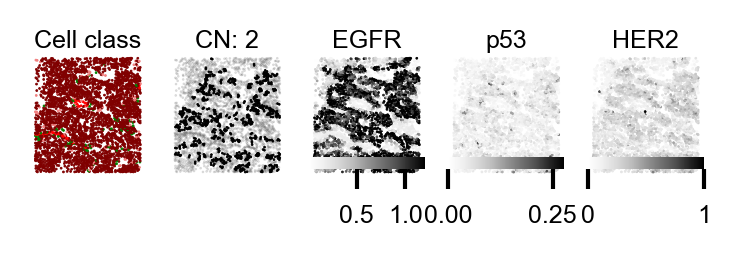

BaselTMA_SP43_199_X8Y5
(2943, 80)
     index  PID                    core  grade  tumor_size  gender  PTNM_M  \
273    357  199  BaselTMA_SP43_199_X8Y5      3          39  FEMALE       0   

     age             Patientstatus  treatment  ... sum_area_cells Subtype  \
273   48  death by primary disease        NaN  ...         314870  PR-ER-   

           HR clinical_type response             sample  ductal lobular  \
273  negative     TripleNeg      NaN  BaselTMA_SP43_199    True   False   

    mucinous  medullary  
273    False      False  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


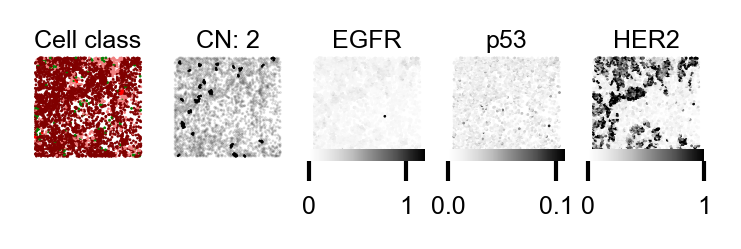

BaselTMA_SP43_116_X3Y4
(6069, 80)
     index  PID                    core  grade  tumor_size  gender  PTNM_M  \
278    363  116  BaselTMA_SP43_116_X3Y4      3          24  FEMALE       0   

     age Patientstatus  treatment  ... sum_area_cells Subtype        HR  \
278   49         alive        NaN  ...         534851  PR-ER-  negative   

    clinical_type response             sample  ductal lobular mucinous  \
278     TripleNeg      NaN  BaselTMA_SP43_116    True   False    False   

     medullary  
278      False  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


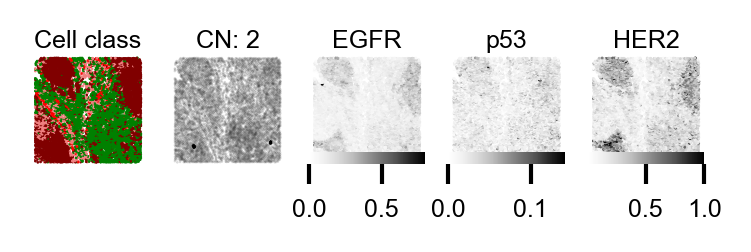

BaselTMA_SP41_276_X9Y8
(4068, 80)
    index  PID                    core  grade  tumor_size  gender  PTNM_M  \
85    114  276  BaselTMA_SP41_276_X9Y8      2          52  FEMALE       0   

    age             Patientstatus  treatment  ... sum_area_cells Subtype  \
85   80  death by primary disease        NaN  ...         388309  PR+ER+   

          HR clinical_type    response             sample  ductal lobular  \
85  positive      HR+HER2-  Refractory  BaselTMA_SP41_276    True   False   

   mucinous  medullary  
85    False      False  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


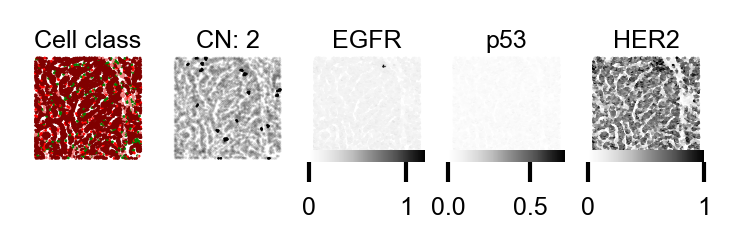

BaselTMA_SP42_27_X6Y6
(2934, 80)
     index  PID                   core  grade  tumor_size  gender  PTNM_M  \
153    209   27  BaselTMA_SP42_27_X6Y6      3          19  FEMALE       0   

     age Patientstatus  treatment  ... sum_area_cells Subtype        HR  \
153   54         alive        NaN  ...         367715  PR-ER-  negative   

    clinical_type response            sample  ductal lobular mucinous  \
153      HR-HER2+      NaN  BaselTMA_SP42_27    True   False    False   

     medullary  
153      False  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


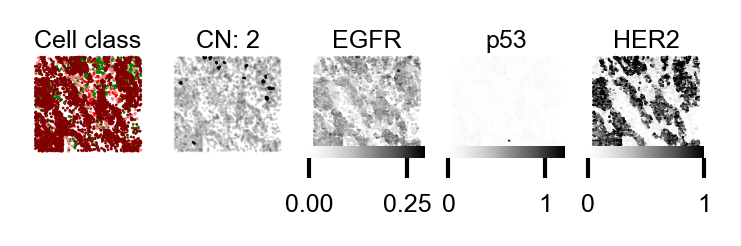

BaselTMA_SP43_23_X15Y7
(2607, 80)
     index  PID                    core  grade  tumor_size  gender  PTNM_M  \
225    296   23  BaselTMA_SP43_23_X15Y7      3          22  FEMALE       0   

     age Patientstatus  treatment  ... sum_area_cells Subtype        HR  \
225   84         alive        NaN  ...         325531  PR-ER-  negative   

    clinical_type response            sample  ductal lobular mucinous  \
225     TripleNeg      NaN  BaselTMA_SP43_23    True   False    False   

     medullary  
225      False  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


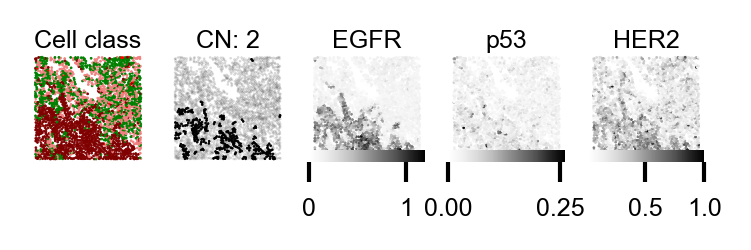

BaselTMA_SP43_111_X8Y6
(5057, 80)
     index  PID                    core  grade  tumor_size  gender  PTNM_M  \
229    302  111  BaselTMA_SP43_111_X8Y6      3          18  FEMALE       0   

     age Patientstatus  treatment  ... sum_area_cells Subtype        HR  \
229   61         alive        NaN  ...         395524  PR-ER-  negative   

    clinical_type response             sample  ductal lobular mucinous  \
229     TripleNeg      NaN  BaselTMA_SP43_111    True   False    False   

     medullary  
229      False  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


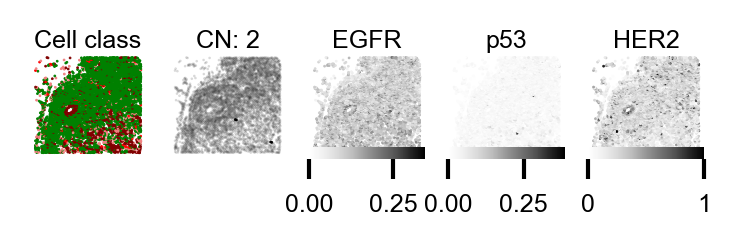

BaselTMA_SP42_179_X13Y8
(5186, 80)
     index  PID                     core  grade  tumor_size  gender  PTNM_M  \
184    241  179  BaselTMA_SP42_179_X13Y8      3          36  FEMALE       0   

     age Patientstatus  treatment  ... sum_area_cells Subtype        HR  \
184   59         alive        NaN  ...         512136  PR-ER-  negative   

    clinical_type response             sample  ductal lobular mucinous  \
184     TripleNeg      NaN  BaselTMA_SP42_179    True   False    False   

     medullary  
184      False  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


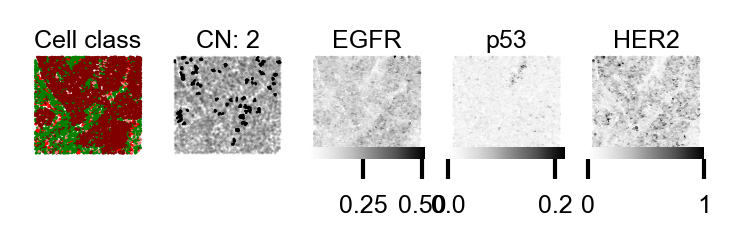

BaselTMA_SP43_108_X13Y8
(6320, 80)
     index  PID                     core  grade  tumor_size  gender  PTNM_M  \
271    354  108  BaselTMA_SP43_108_X13Y8      3          33  FEMALE       0   

     age             Patientstatus  treatment  ... sum_area_cells Subtype  \
271   64  death by primary disease        NaN  ...         559188  PR+ER+   

           HR clinical_type    response             sample  ductal lobular  \
271  positive      HR+HER2-  Refractory  BaselTMA_SP43_108   False   False   

    mucinous  medullary  
271    False       True  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


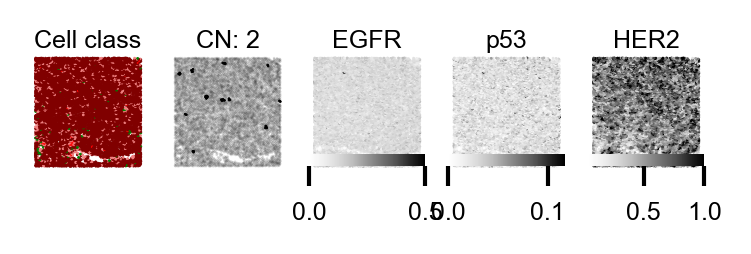

BaselTMA_SP43_15_X1Y9
(4396, 80)
     index  PID                   core  grade  tumor_size  gender  PTNM_M  \
283    370   15  BaselTMA_SP43_15_X1Y9      3          25  FEMALE       0   

     age Patientstatus  treatment  ... sum_area_cells Subtype        HR  \
283   63         alive        NaN  ...         444209  PR-ER-  negative   

    clinical_type response            sample  ductal lobular mucinous  \
283     TripleNeg      NaN  BaselTMA_SP43_15    True   False    False   

     medullary  
283      False  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


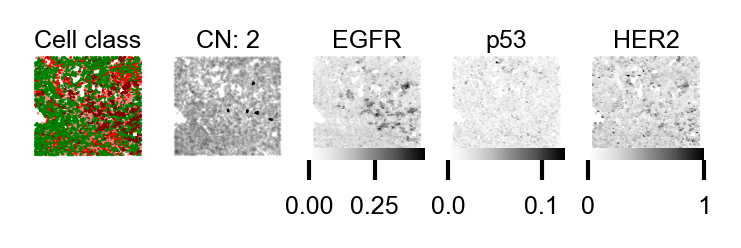

BaselTMA_SP41_186_X5Y4
(4923, 80)
    index  PID                    core  grade  tumor_size  gender  PTNM_M  \
57     80  186  BaselTMA_SP41_186_X5Y4      2          15  FEMALE       0   

    age Patientstatus  treatment  ... sum_area_cells Subtype        HR  \
57   65         alive        NaN  ...         480873  PR+ER+  positive   

   clinical_type   response             sample  ductal lobular mucinous  \
57      HR+HER2-  Sensitive  BaselTMA_SP41_186    True   False    False   

    medullary  
57      False  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


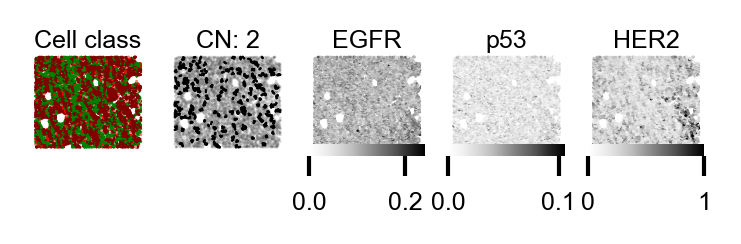

BaselTMA_SP43_107_X4Y7
(2831, 80)
     index  PID                    core  grade  tumor_size  gender  PTNM_M  \
253    328  107  BaselTMA_SP43_107_X4Y7      3          21  FEMALE       0   

     age Patientstatus  treatment  ... sum_area_cells Subtype        HR  \
253   85         alive        NaN  ...         366744  PR-ER-  negative   

    clinical_type response             sample  ductal lobular mucinous  \
253     TripleNeg      NaN  BaselTMA_SP43_107    True   False    False   

     medullary  
253      False  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


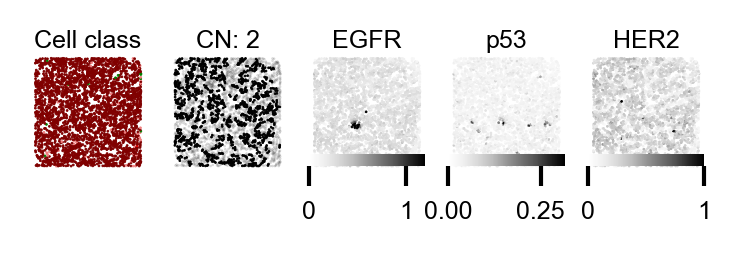

BaselTMA_SP42_12_X12Y8
(921, 80)
     index  PID                    core  grade  tumor_size  gender  PTNM_M  \
183    240   12  BaselTMA_SP42_12_X12Y8      3          18  FEMALE       0   

     age Patientstatus  treatment  ... sum_area_cells Subtype        HR  \
183   50         alive        NaN  ...          94866  PR-ER-  negative   

    clinical_type response            sample  ductal lobular mucinous  \
183      HR-HER2+      NaN  BaselTMA_SP42_12    True   False    False   

     medullary  
183      False  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


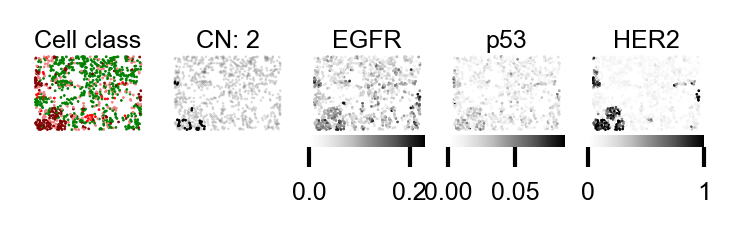

BaselTMA_SP43_230_X11Y5
(2440, 80)
     index  PID                     core  grade  tumor_size  gender  PTNM_M  \
274    358  230  BaselTMA_SP43_230_X11Y5      3          21  FEMALE       0   

     age Patientstatus  treatment  ... sum_area_cells Subtype        HR  \
274   71         alive        NaN  ...         316190  PR-ER-  negative   

    clinical_type response             sample  ductal lobular mucinous  \
274     TripleNeg      NaN  BaselTMA_SP43_230    True   False    False   

     medullary  
274      False  

[1 rows x 65 columns]


/tmp/ipykernel_4104654/950746125.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


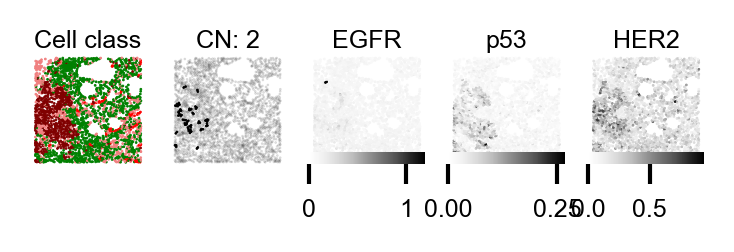

In [130]:
import matplotlib


CLUSTER_TO_ANALYZE = 10
cluster_images = list(set(sample_count_basel[clusters == CLUSTER_TO_ANALYZE].core))


from matplotlib import tri
from mpl_toolkits.axes_grid1 import make_axes_locatable

tumor_percentage_argsort = (-class_percentages['Tumor']).argsort().argsort()
MARKER_SIZE = 0.2

for image in cluster_images:
    # Create figure and gridspec for better control of subplot sizes
    fig = plt.figure(figsize=(3.5, 0.6), dpi=300)
    gs = plt.GridSpec(2, 6, height_ratios=[1, 0.1], hspace=0.01)
    
    # Create main plot axes
    axs = [plt.subplot(gs[0, i]) for i in range(1, 6)]
    print(image)
    image_df = cell_df[cell_df.core == image]
    print(image_df.shape)
    #image_sd_df = sd_df[cell_df.image == image]
    
    # Compute triangulation
    tr = tri.Triangulation(image_df['Location_Center_X'], image_df['Location_Center_Y'])
    areas = compute_triangle_areas(tr)
    tr.set_mask(areas > 200)
    print(clinical_data_basel[clinical_data_basel['core'] == image])
    
    # Plot 1: Cell types
    axs[0].set_title('Cell class', size=6, pad=0.1)
    scatter0 = axs[0].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        #alpha=0.5,
        c=image_df['class'].apply(lambda x: class_to_color[x]),
    )
    axs[0].set_aspect(1)
    axs[0].axis('off')
    axs[0].set_ylabel(f'{ROI_CLUSTER_NAME}: {CLUSTER_TO_ANALYZE}')
    # Create legend elements
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=color, label=cell_type, 
                                 markersize=4)
                      for cell_type, color in tau.PANEL_1_CELL_TYPE_TO_COLOR.items()]
    
    # Add legend with small font and two columns
#    legend_ax = plt.subplot(gs[0, 0])
#     legend = legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           bbox_to_anchor=(0.05, -0.1),
#                           loc='center left',
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     legend_ax.axis('off')
    
#     # Remove legend frame
#     legend.get_frame().set_linewidth(0.0)
    
    axs[0].set_aspect(1)
    axs[0].axis('off')
    
    # Plot 2: Cellohood
    axs[1].set_title('CN: 2', size=6, pad=0.1)
    scatter1 = axs[1].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        alpha=0.1 + 0.9 * (image_df['cc'] == 2),
        c='black',
        s=MARKER_SIZE,
        #cmap=custom_cmap,
        linewidths=MARKER_SIZE,
#         vmin=0,
#         vmax=6,
    )
    axs[1].axis('off')
    axs[1].set_aspect(1)
    
    #cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=6)
    #cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap=custom_cmap)
    

#     legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
#                                  markerfacecolor=cc_sm.to_rgba(i), label=f'CC:{i}', 
#                                  markersize=4)
#                      for i in range(7)]
#    cc_legend_ax = plt.subplot(gs[1, 2])
#     cc_legend = cc_legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           #bbox_to_anchor=(0.05, 0.1),
#                           #loc='upper center',
#                           bbox_to_anchor=(0.88, 3),
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     cc_legend.get_frame().set_linewidth(0.0)
#     cc_legend_ax.axis('off')
    
    # Plot 3: ECAD Expression
    axs[2].set_title('EGFR', size=6, pad=0.1)
    ind_ = JACKSON_MARKERS[(JACKSON_MARKERS_CLEAN.index('EGFR'))]
    im1 = axs[2].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        c=numpy.clip(image_df[ind_], 0, 1.2),
        cmap='Greys',
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[2].axis('off')
    axs[2].set_aspect(1)
    
    # Plot 4: Ki67 Expression
    axs[3].set_title('p53', size=6, pad=0.1)
    ind_ = JACKSON_MARKERS[(JACKSON_MARKERS_CLEAN.index('p53'))]
    im2 = axs[3].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        c=numpy.clip(image_df[ind_], 0, 1.2),
        cmap='Greys',
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[3].axis('off')
    axs[3].set_aspect(1)
    
    # Plot 5: CD3 Expression
    axs[4].set_title('HER2', size=6, pad=0.1)
    ind_ = JACKSON_MARKERS[(JACKSON_MARKERS_CLEAN.index('HER2'))]
    im3 = axs[4].scatter(
        image_df['Location_Center_X'],
        image_df['Location_Center_Y'],
        c=numpy.clip(image_df[ind_], 0, 1.),
        cmap='Greys',
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[4].axis('off')
    axs[4].set_aspect(1)
    
    
    # Add colorbars in separate row
    # Only add for plots that need them (2-5)
    for i, im in enumerate([im1, im2, im3]):
        cax = plt.subplot(gs[1, i+3])
        cbar = plt.colorbar(
            im, 
            cax=cax, 
            orientation='horizontal', 
            aspect=40, 
            shrink=0.9, 
            pad=0.01, 
            anchor=(1.1, 0),
        )
        cbar.ax.tick_params(labelsize=6)
        cbar.outline.set_visible(False)
        EPS = 0.12
        cbar_pos = cbar.ax.get_position()
        new_box = matplotlib.transforms.Bbox([[cbar_pos.x0, cbar_pos.y0 + EPS], [cbar_pos.x1, cbar_pos.y1 + EPS]])
        cbar.ax.set_position(new_box)
    
    # Make sure all plots have same limits
    # Get the overall limits from all scatter plots and images
#     xlims = []
#     ylims = []
    
#     # Get limits from scatter plots
#     xlims.extend([axs[0].get_xlim(), axs[1].get_xlim()])
#     ylims.extend([axs[0].get_ylim(), axs[1].get_ylim()])
    
#     # Get limits from images
#     for i in range(1, 6):
#         xlims.append([0, img_array.shape[2]])
#         ylims.append([0, img_array.shape[1]])
    
#     # Find the overall limits
#     xmin = min([x[0] for x in xlims])
#     xmax = max([x[1] for x in xlims])
#     ymin = min([y[0] for y in ylims])
#     ymax = max([y[1] for y in ylims])
    
#     # Apply the same limits to all plots
#     for ax in axs:
#         ax.set_xlim(xmin, xmax)
#         ax.set_ylim(ymin, ymax)
    
    plt.tight_layout()

    plt.show()